## Wedding Loans

In [1]:
#import dependencies
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#read the given file, do not edit these files directly
bureau = pd.read_csv('IS453 Group Assignment - Bureau Data.csv')
application = pd.read_csv('IS453 Group Assignment - Application Data.csv')

## DATA EXPLORATION

In [3]:
# === EDA SETUP: work on a COPY so original `application` is untouched ===
# All variables here are prefixed `eda_` to avoid clashing with later cells.

app_eda = application.copy()

# Identify columns by dtype
eda_obj_cols = app_eda.select_dtypes(include=['object', 'category']).columns.tolist()
eda_num_all  = app_eda.select_dtypes(include=['number']).columns.tolist()

# Exclude ID and TARGET from analysis
eda_exclude = {'SK_ID_CURR', 'TARGET'}

# Binary numerics (FLAG_* columns etc.) → categorical
eda_binary_cols = [
    c for c in eda_num_all
    if c not in eda_exclude and app_eda[c].dropna().nunique() == 2
]

# Ordinal ratings → categorical (explicitly named)
eda_ordinal_cols = [
    c for c in ['REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY']
    if c in app_eda.columns
]

eda_extra_cat = eda_binary_cols + eda_ordinal_cols

eda_cat_cols = [c for c in (eda_obj_cols + eda_extra_cat) if c not in eda_exclude]
eda_num_cols = [c for c in eda_num_all
                if c not in eda_exclude and c not in eda_extra_cat]

print(f"Numerical columns   : {len(eda_num_cols)}")
print(f"Categorical columns : {len(eda_cat_cols)} "
      f"(incl. {len(eda_binary_cols)} binary flags + {len(eda_ordinal_cols)} ordinal ratings)")

print(f"\nTarget distribution:\n{app_eda['TARGET'].value_counts().rename({0:'Good (0)', 1:'Bad (1)'})}")

print("\n" + "=" * 60)
print(f"NUMERICAL COLUMNS ({len(eda_num_cols)})")
print("=" * 60)
for c in eda_num_cols:
    print(f"  - {c}")

print("\n" + "=" * 60)
print(f"CATEGORICAL COLUMNS ({len(eda_cat_cols)})")
print("=" * 60)
for c in eda_cat_cols:
    eda_tag = ""
    if c in eda_binary_cols:
        eda_tag = " [binary flag]"
    elif c in eda_ordinal_cols:
        eda_tag = " [ordinal rating]"
    elif c in eda_obj_cols:
        eda_tag = " [object/string]"
    print(f"  - {c}{eda_tag}")

Numerical columns   : 68
Categorical columns : 50 (incl. 32 binary flags + 2 ordinal ratings)

Target distribution:
TARGET
Good (0)    282686
Bad (1)      24825
Name: count, dtype: int64

NUMERICAL COLUMNS (68)
  - CNT_CHILDREN
  - AMT_INCOME_TOTAL
  - AMT_CREDIT
  - AMT_ANNUITY
  - AMT_GOODS_PRICE
  - REGION_POPULATION_RELATIVE
  - DAYS_BIRTH
  - DAYS_EMPLOYED
  - DAYS_REGISTRATION
  - DAYS_ID_PUBLISH
  - OWN_CAR_AGE
  - CNT_FAM_MEMBERS
  - HOUR_APPR_PROCESS_START
  - EXT_SOURCE_1
  - APARTMENTS_AVG
  - BASEMENTAREA_AVG
  - YEARS_BEGINEXPLUATATION_AVG
  - YEARS_BUILD_AVG
  - COMMONAREA_AVG
  - ELEVATORS_AVG
  - ENTRANCES_AVG
  - FLOORSMAX_AVG
  - FLOORSMIN_AVG
  - LANDAREA_AVG
  - LIVINGAPARTMENTS_AVG
  - LIVINGAREA_AVG
  - NONLIVINGAPARTMENTS_AVG
  - NONLIVINGAREA_AVG
  - APARTMENTS_MODE
  - BASEMENTAREA_MODE
  - YEARS_BEGINEXPLUATATION_MODE
  - YEARS_BUILD_MODE
  - COMMONAREA_MODE
  - ELEVATORS_MODE
  - ENTRANCES_MODE
  - FLOORSMAX_MODE
  - FLOORSMIN_MODE
  - LANDAREA_MODE
  - LIVIN

## Univaraite Analysis

### Histogram of numerical

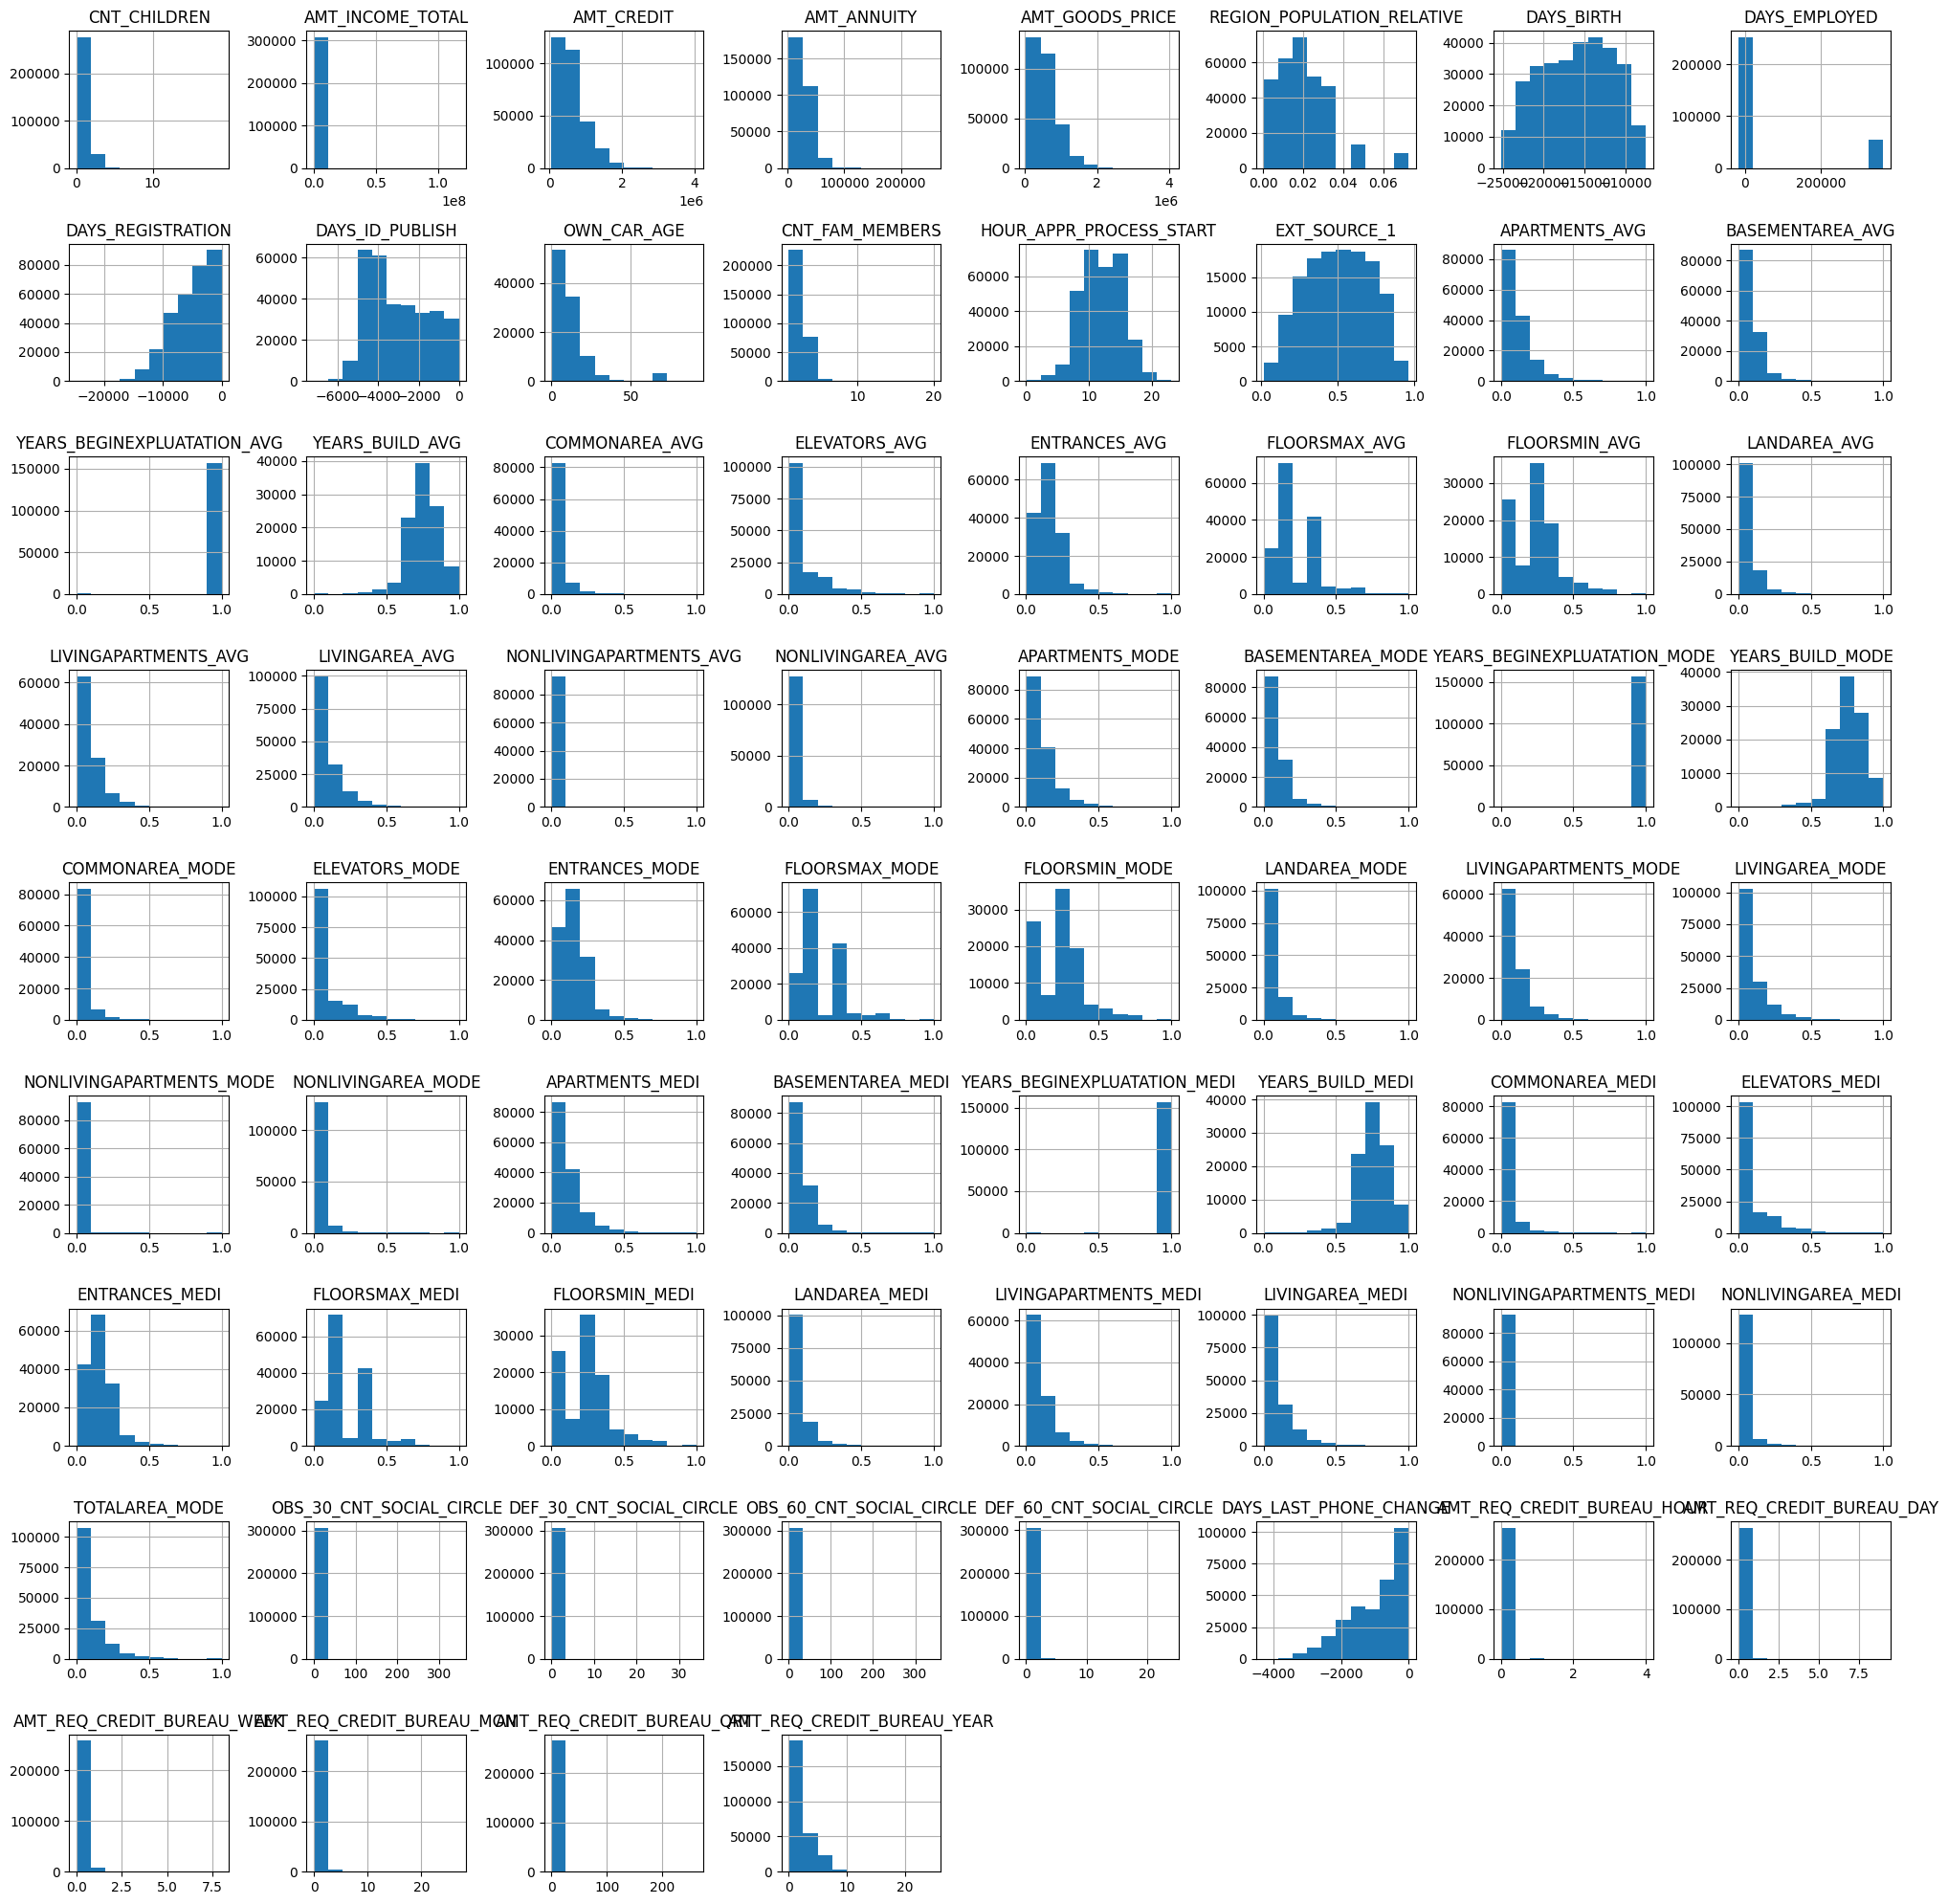

In [4]:
# === UNIVARIATE: Histograms for numerical variables ===
eda_ncols = 4
eda_nrows = math.ceil(len(eda_num_cols) / eda_ncols)

app_eda[eda_num_cols].hist(figsize=(5 * eda_ncols, 3 * eda_nrows),
                           layout=(eda_nrows, eda_ncols))
plt.tight_layout()
plt.show()

### Boxplot of numerical

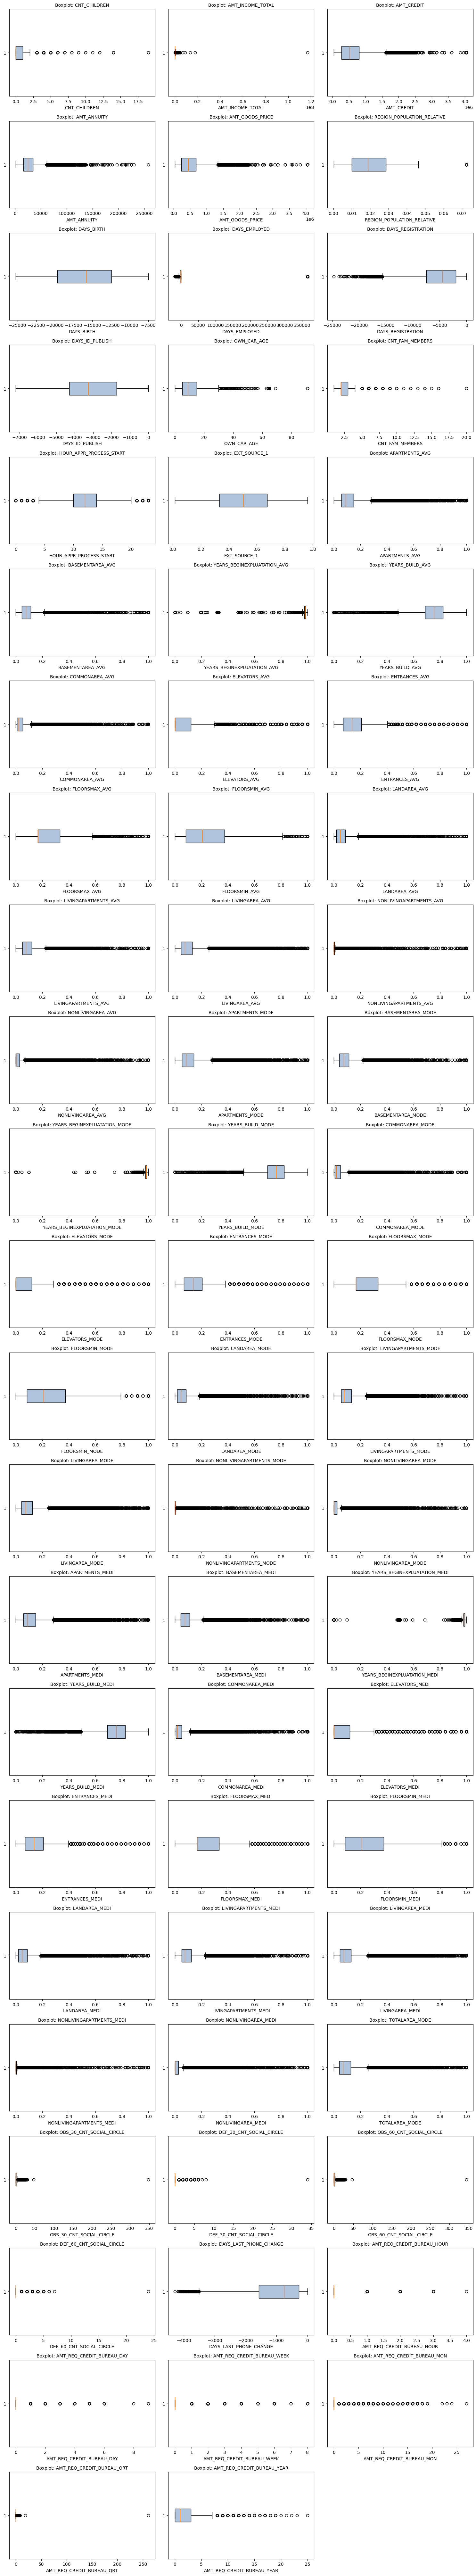

In [15]:
# === UNIVARIATE: Boxplots for numerical variables (horizontal) ===
eda_n = len(eda_num_cols)
eda_ncols = 3
eda_nrows = math.ceil(eda_n / eda_ncols)

fig, axes = plt.subplots(eda_nrows, eda_ncols, figsize=(5 * eda_ncols, 3.5 * eda_nrows))
axes = axes.flatten()

for i, col in enumerate(eda_num_cols):
    axes[i].boxplot(app_eda[col].dropna(), vert=False, patch_artist=True,
                    boxprops=dict(facecolor='lightsteelblue'))
    axes[i].set_title(f'Boxplot: {col}', fontsize=10)
    axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

### Bar Chart of categorical

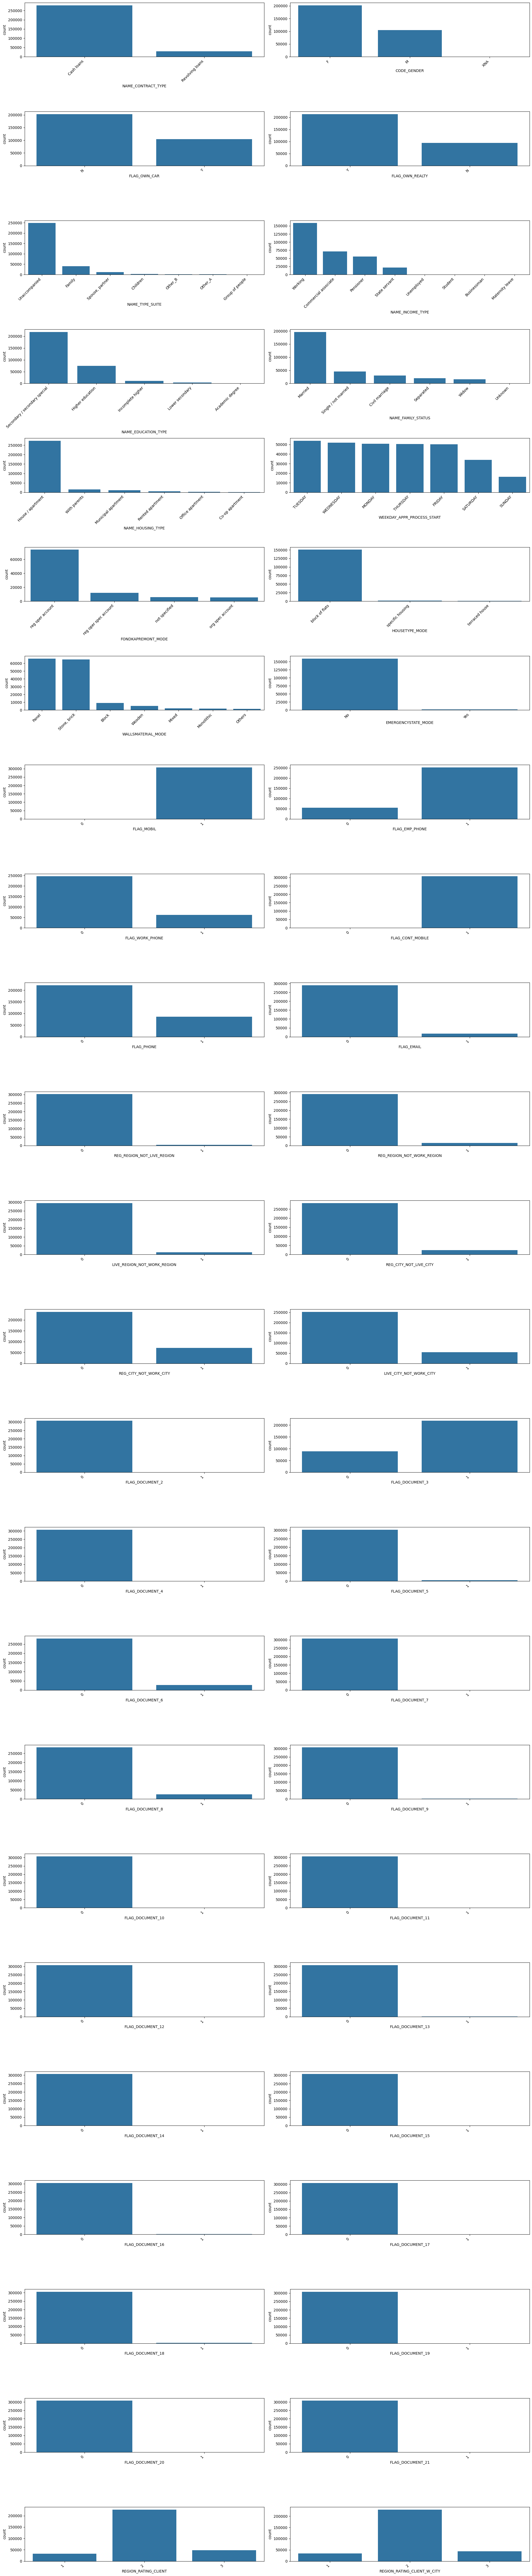

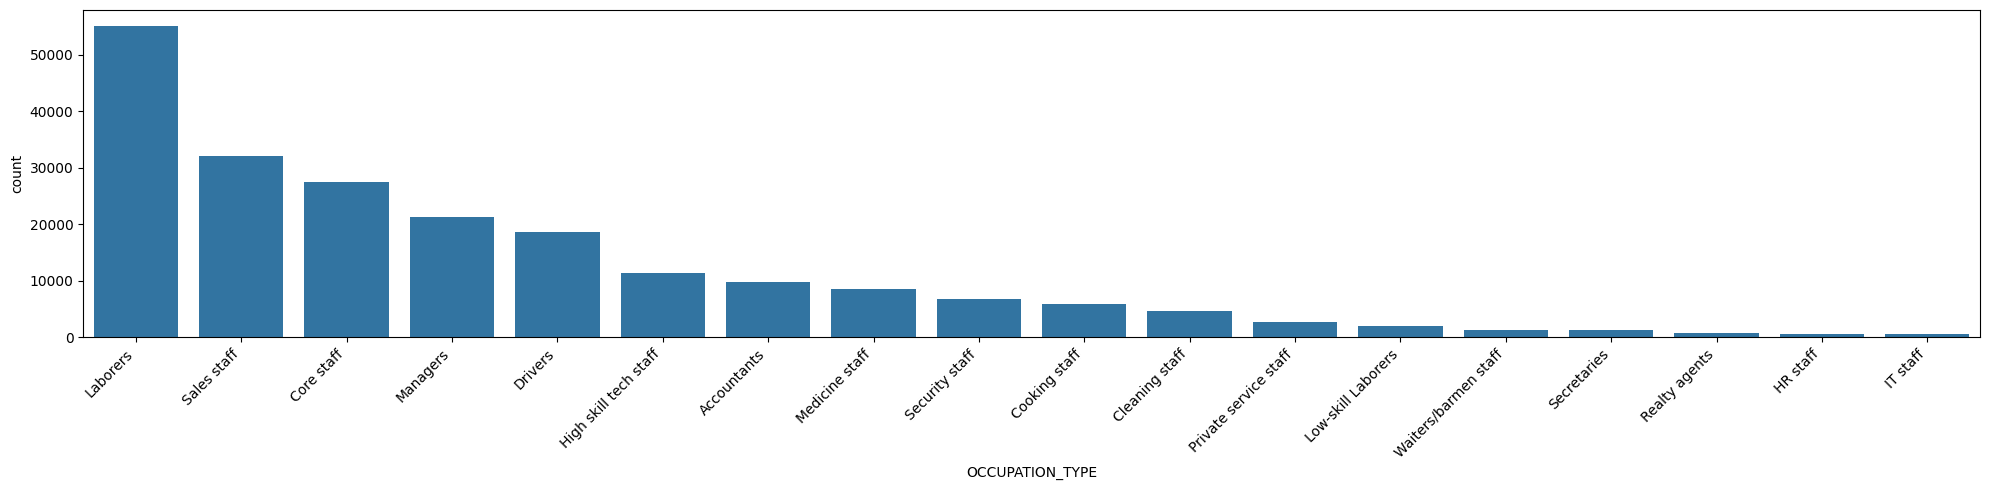

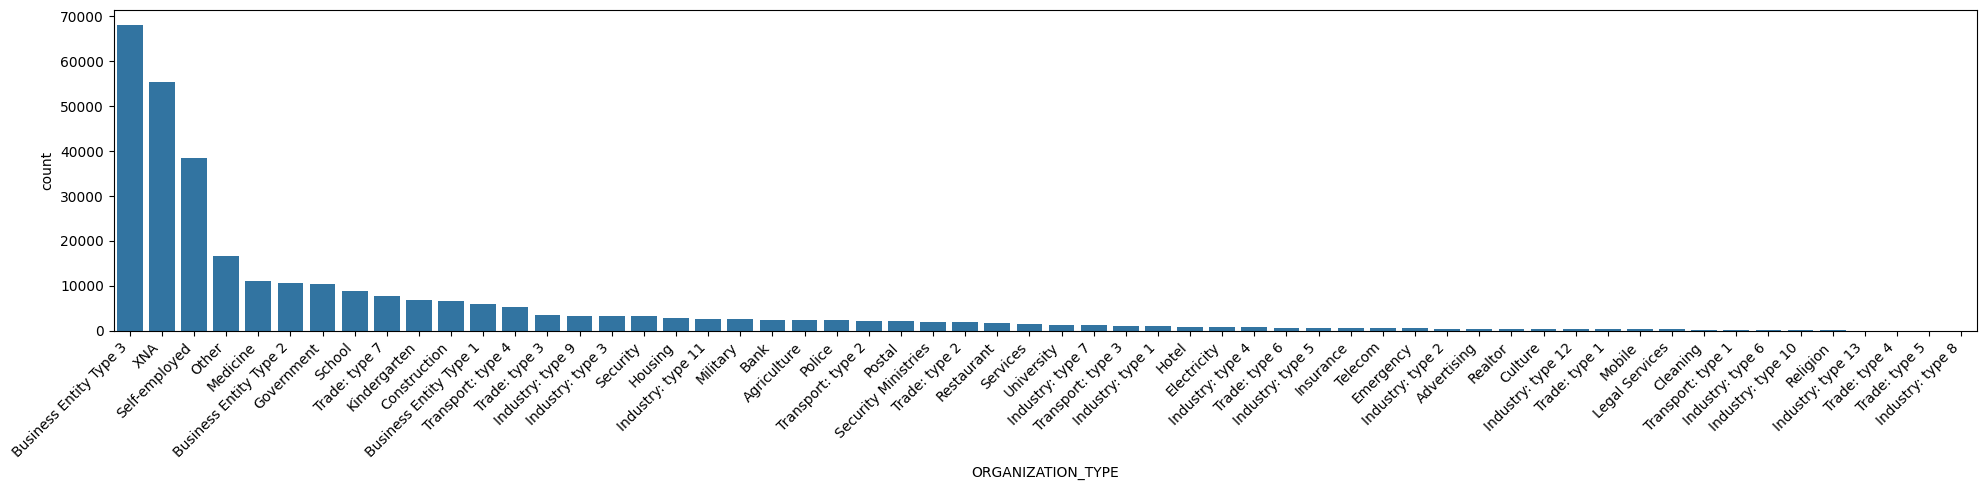

In [13]:
# === UNIVARIATE: Bar charts for categorical variables ===
# Split into high-cardinality (>15 categories) and normal columns
eda_high_card = [c for c in eda_cat_cols if app_eda[c].nunique() > 15]
eda_normal_cat = [c for c in eda_cat_cols if c not in eda_high_card]

# --- Normal categorical columns: 2 per row ---
eda_nrows = math.ceil(len(eda_normal_cat) / 2)
fig, axes = plt.subplots(ncols=2, nrows=eda_nrows, figsize=(20, 4 * eda_nrows))

for i, axis in enumerate(fig.axes):
    if i >= len(eda_normal_cat):
        axis.set_visible(False)
        continue
    col = eda_normal_cat[i]
    if app_eda[col].dtype == 'O':
        sns.countplot(ax=axis, x=app_eda[col],
                      order=app_eda[col].value_counts(ascending=False).index)
    else:
        sns.countplot(ax=axis, x=app_eda[col])
    axis.set_xlabel(str(col))
    axis.tick_params(axis='x', rotation=45)
    for label in axis.get_xticklabels():
        label.set_ha('right')

plt.tight_layout()
plt.show()

# --- High-cardinality columns: one per row, full width ---
for col in eda_high_card:
    fig, axis = plt.subplots(figsize=(20, 5))
    sns.countplot(ax=axis, x=app_eda[col],
                  order=app_eda[col].value_counts(ascending=False).index)
    axis.set_xlabel(str(col))
    axis.tick_params(axis='x', rotation=45)
    for label in axis.get_xticklabels():
        label.set_ha('right')
    plt.tight_layout()
    plt.show()

## Bivariate Analysis

### KDE of numerical

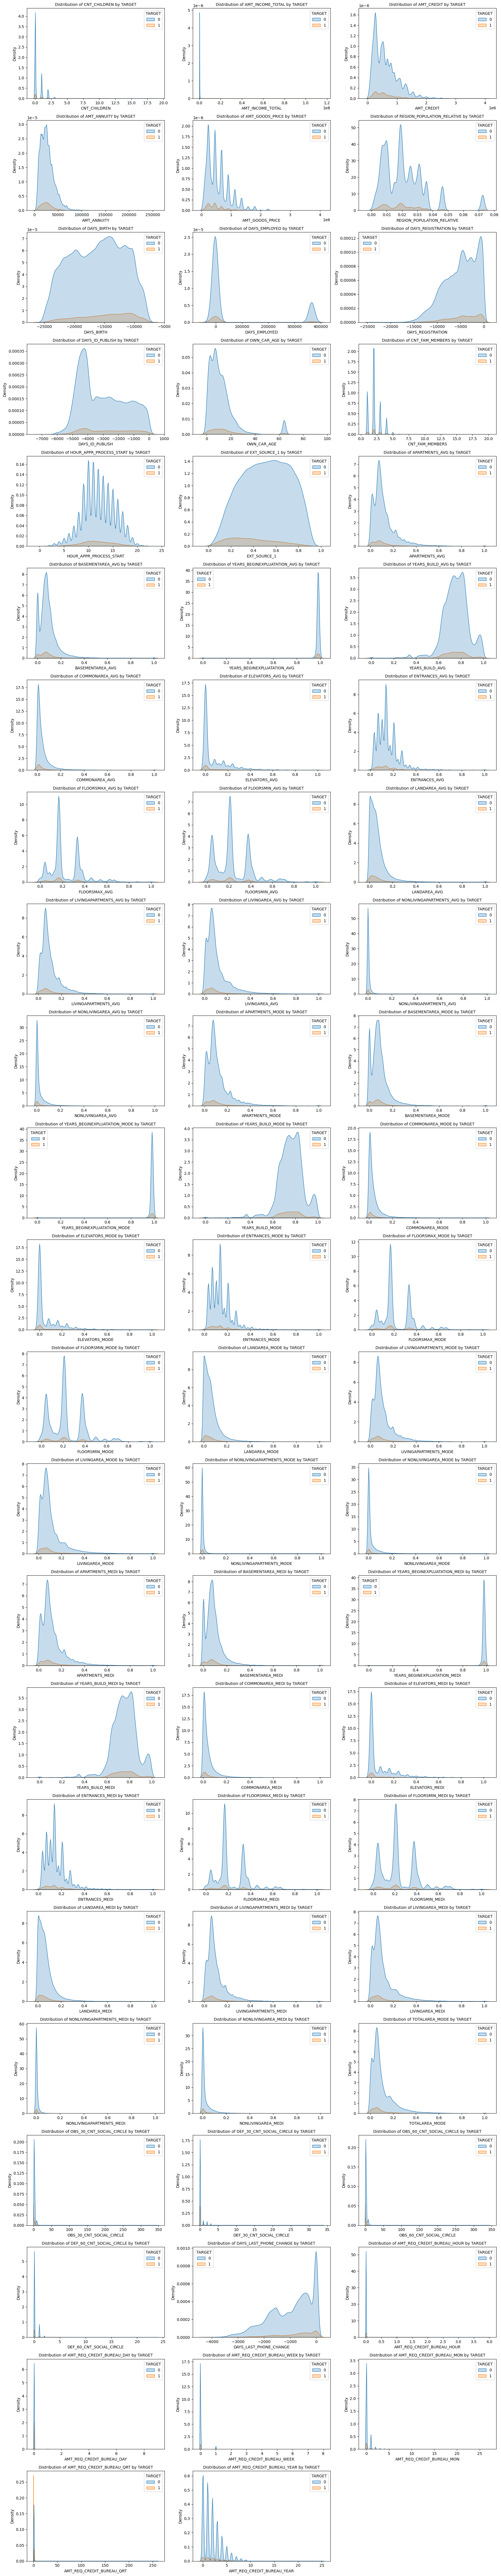

In [8]:
# === BIVARIATE: KDE plots for numerical variables, split by TARGET ===
eda_nrows = math.ceil(len(eda_num_cols) / 3)
fig, axes = plt.subplots(ncols=3, nrows=eda_nrows, figsize=(18, 4 * eda_nrows))

for i, axis in enumerate(fig.axes):
    if i >= len(eda_num_cols):
        axis.set_visible(False)
        continue
    col = eda_num_cols[i]
    sns.kdeplot(data=app_eda, x=col, hue='TARGET', fill=True, ax=axis,
                warn_singular=False)
    axis.set_title(f'Distribution of {col} by TARGET', fontsize=10)

plt.tight_layout()
plt.show()

### Stacked Bar Charts of categorical



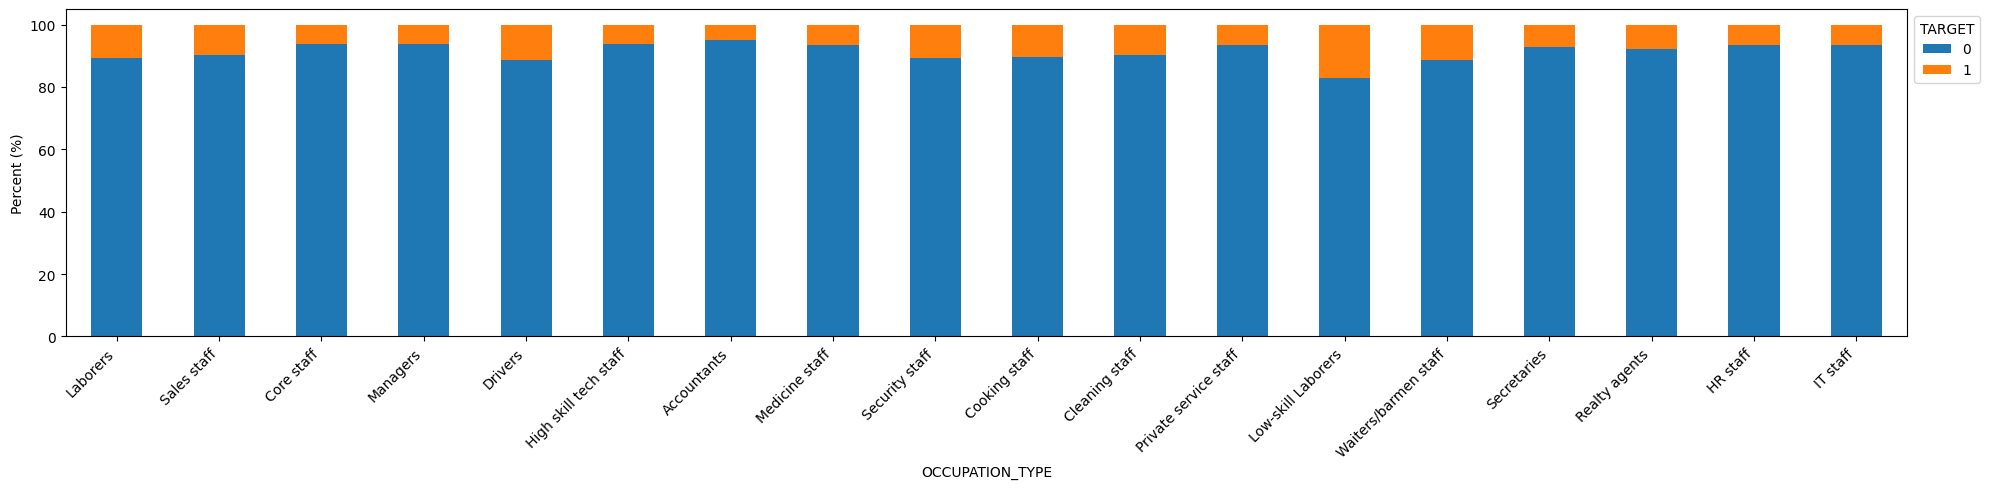

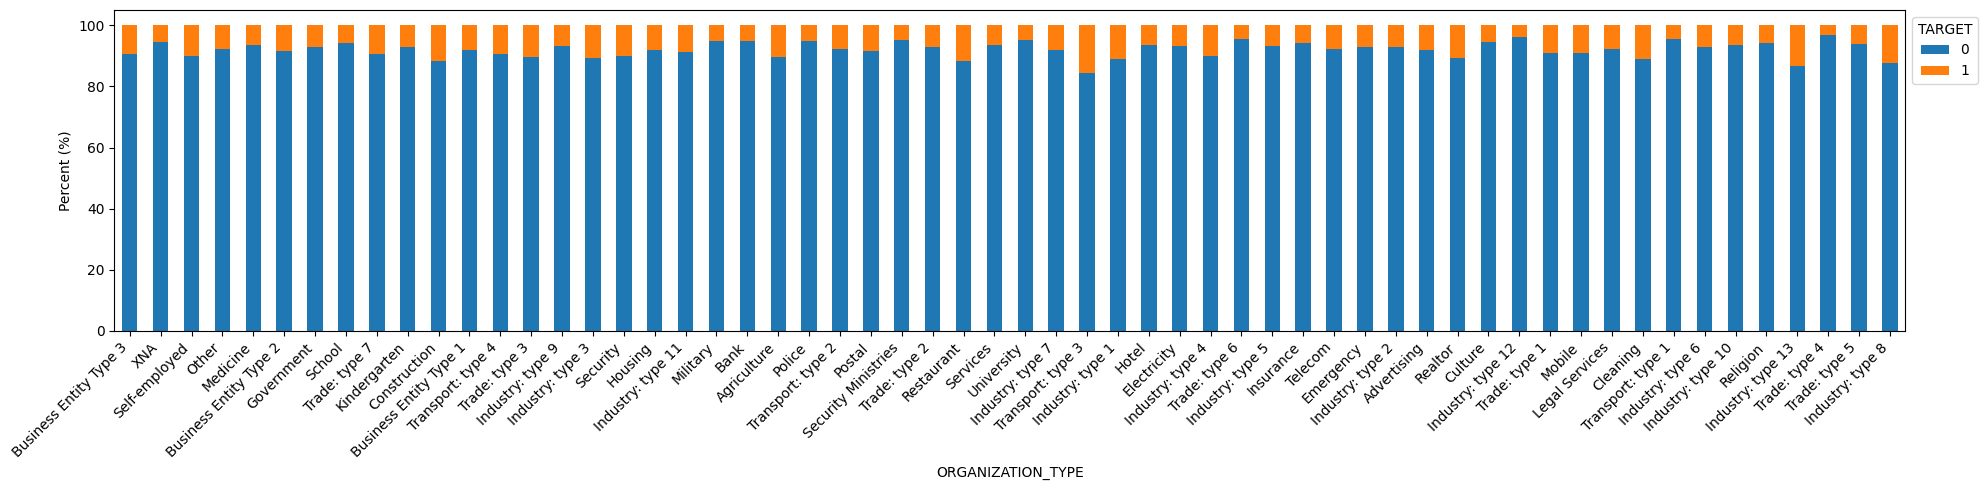

In [11]:
# === BIVARIATE: 100% stacked bar charts for categorical variables ===
eda_high_card = [c for c in eda_cat_cols if app_eda[c].nunique() > 15]
eda_normal_cat = [c for c in eda_cat_cols if c not in eda_high_card]

# --- Normal categorical columns: 2 per row ---
eda_nrows = math.ceil(len(eda_normal_cat) / 2)
fig, axes = plt.subplots(ncols=2, nrows=eda_nrows, figsize=(20, 5 * eda_nrows))

for i, axis in enumerate(fig.axes):
    if i >= len(eda_normal_cat):
        axis.set_visible(False)
        continue
    col = eda_normal_cat[i]

    eda_ct = pd.crosstab(app_eda[col], app_eda['TARGET'], normalize='index') * 100
    eda_ct = eda_ct.loc[app_eda[col].value_counts(ascending=False).index.intersection(eda_ct.index)]

    eda_ct.plot(kind='bar', stacked=True, ax=axis)
    axis.set_xlabel(str(col))
    axis.set_ylabel('Percent (%)')
    axis.legend(title='TARGET', bbox_to_anchor=(1.0, 1.0))
    axis.tick_params(axis='x', rotation=45)
    for label in axis.get_xticklabels():
        label.set_ha('right')

plt.tight_layout()
plt.show()

# --- High-cardinality columns: one per row, full width ---
for col in eda_high_card:
    fig, axis = plt.subplots(figsize=(20, 5))

    eda_ct = pd.crosstab(app_eda[col], app_eda['TARGET'], normalize='index') * 100
    eda_ct = eda_ct.loc[app_eda[col].value_counts(ascending=False).index.intersection(eda_ct.index)]

    eda_ct.plot(kind='bar', stacked=True, ax=axis)
    axis.set_xlabel(str(col))
    axis.set_ylabel('Percent (%)')
    axis.legend(title='TARGET', bbox_to_anchor=(1.0, 1.0))
    axis.tick_params(axis='x', rotation=45)
    for label in axis.get_xticklabels():
        label.set_ha('right')

    plt.tight_layout()
    plt.show()

### Grouped bar charts of categorical



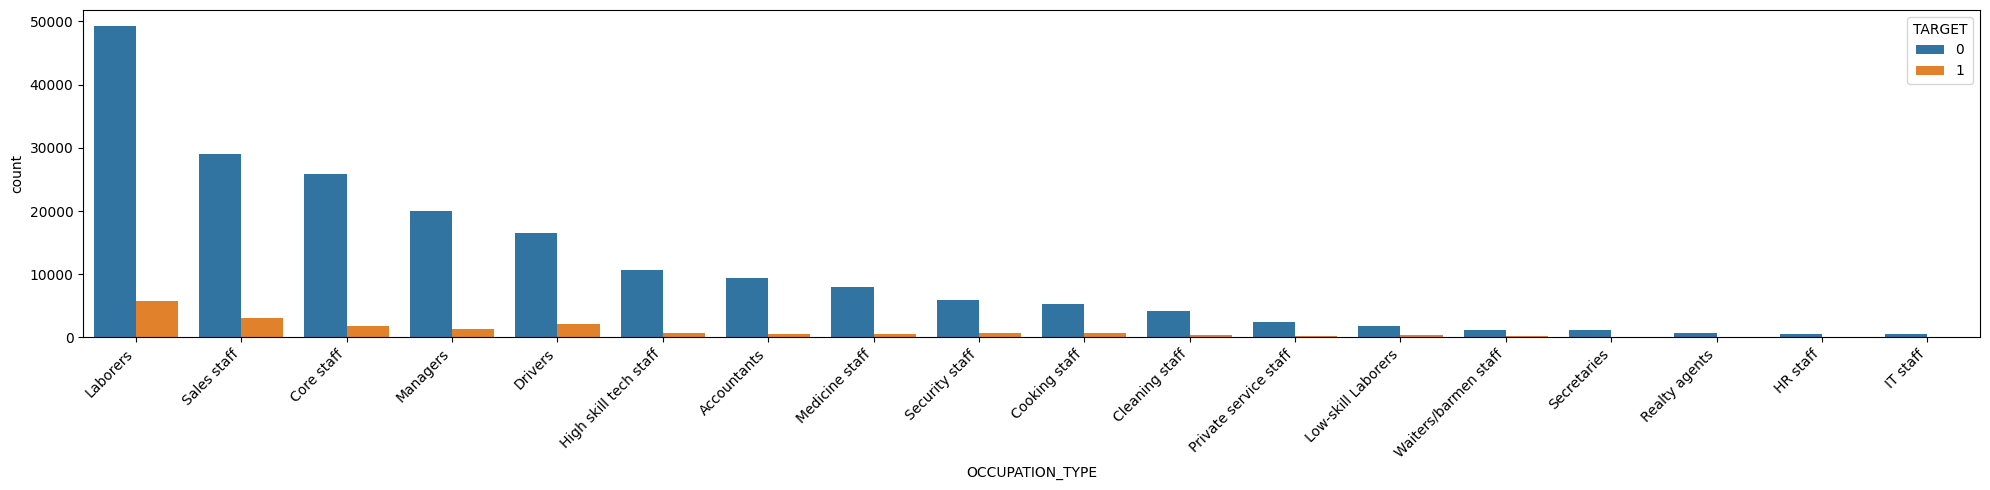

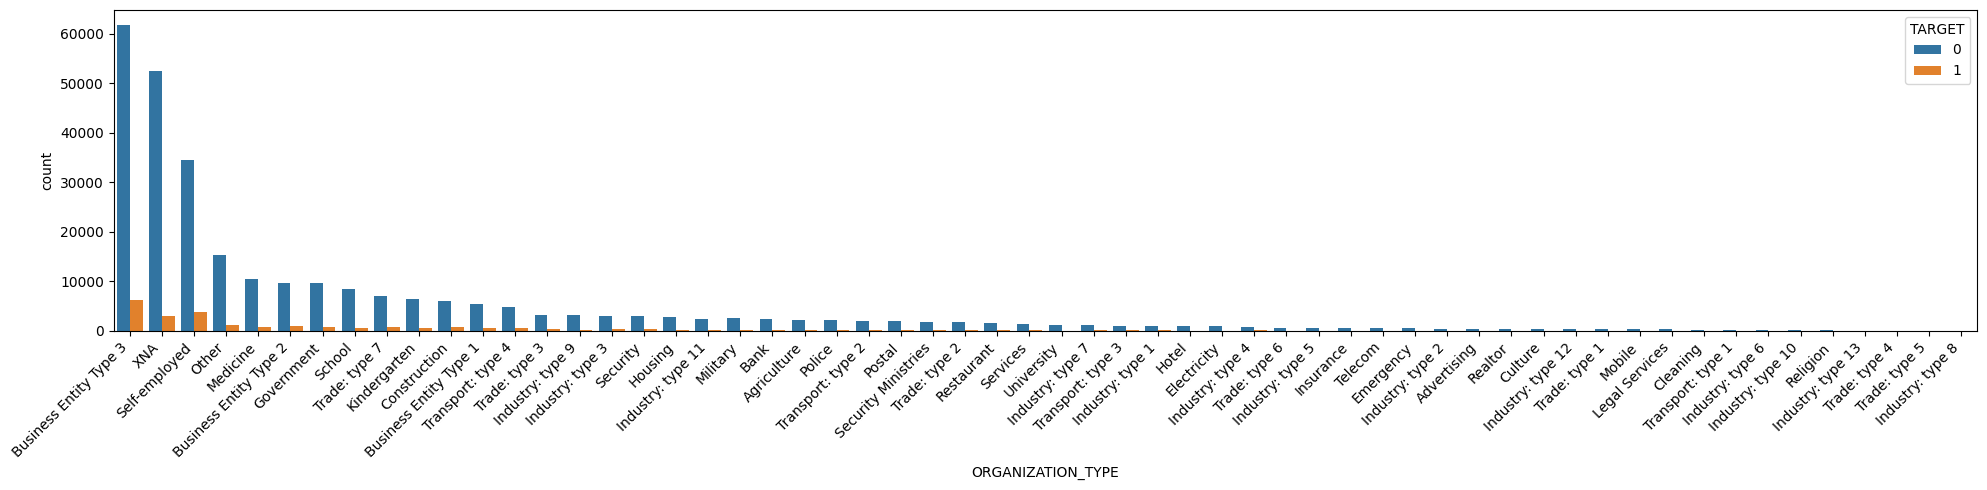

In [12]:
# === BIVARIATE: Grouped bar charts for categorical variables ===
eda_high_card = [c for c in eda_cat_cols if app_eda[c].nunique() > 15]
eda_normal_cat = [c for c in eda_cat_cols if c not in eda_high_card]

# --- Normal categorical columns: 2 per row ---
eda_nrows = math.ceil(len(eda_normal_cat) / 2)
fig, axes = plt.subplots(ncols=2, nrows=eda_nrows, figsize=(20, 5 * eda_nrows))

for i, axis in enumerate(fig.axes):
    if i >= len(eda_normal_cat):
        axis.set_visible(False)
        continue
    col = eda_normal_cat[i]
    sns.countplot(ax=axis, x=app_eda[col], hue=app_eda['TARGET'],
                  order=app_eda[col].value_counts(ascending=False).index
                  if app_eda[col].dtype == 'O' else None)
    axis.set_xlabel(str(col))
    axis.tick_params(axis='x', rotation=45)
    for label in axis.get_xticklabels():
        label.set_ha('right')

plt.tight_layout()
plt.show()

# --- High-cardinality columns: one per row, full width ---
for col in eda_high_card:
    fig, axis = plt.subplots(figsize=(20, 5))
    sns.countplot(ax=axis, x=app_eda[col], hue=app_eda['TARGET'],
                  order=app_eda[col].value_counts(ascending=False).index)
    axis.set_xlabel(str(col))
    axis.tick_params(axis='x', rotation=45)
    for label in axis.get_xticklabels():
        label.set_ha('right')
    plt.tight_layout()
    plt.show()

# DATA PREPARATION

## Filtering application data based on business logic

In [17]:
columns_to_remove = [
    #Gender
    'CODE_GENDER',
    
    # Car-related
    'OWN_CAR_AGE',

    #Timing of application:
    'WEEKDAY_APPR_PROCESS_START',
    'HOUR_APPR_PROCESS_START',

    # Building/Apartment detail variables (_AVG)
    'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG',
    'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG',
    'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG',
    'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG',

    # Building/Apartment detail variables (_MODE)
    'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE',
    'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'ELEVATORS_MODE', 'ENTRANCES_MODE',
    'FLOORSMAX_MODE', 'FLOORSMIN_MODE', 'LANDAREA_MODE', 'LIVINGAPARTMENTS_MODE',
    'LIVINGAREA_MODE', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAREA_MODE',
    'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'TOTALAREA_MODE',
    'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE',

    # Building/Apartment detail variables (_MEDI)
    'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MEDI',
    'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'ELEVATORS_MEDI', 'ENTRANCES_MEDI',
    'FLOORSMAX_MEDI', 'FLOORSMIN_MEDI', 'LANDAREA_MEDI', 'LIVINGAPARTMENTS_MEDI',
    'LIVINGAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAREA_MEDI',

    # Document flags
    'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_5',
    'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_9',
    'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_13',
    'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_17',
    'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_21',

    # Contact & reachability flags
    'FLAG_MOBIL',
    'FLAG_CONT_MOBILE',
    'FLAG_EMP_PHONE',

    # Address mismatch flags
    'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION',
    'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY',
    'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY',
]

In [18]:
# Create a new csv file with the reduced columns

# Step 1: Create the reduced dataframe
application_reduced = application.drop(columns=columns_to_remove)

# Step 2: Save it
application_reduced.to_csv('application_reduced.csv', index=False)

In [19]:
# Helper function to mask invalid data
def mask_invalid(df, column, condition, label):
    """Replaces invalid data with NaN and reports the count."""
    already_null = df[column].isna().sum()
    df.loc[condition, column] = np.nan
    new_nulls = df[column].isna().sum() - already_null
    print(f"{label:<21} | Converted {new_nulls:,} values to NaN")
print(application_reduced.columns)

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'FLAG_OWN_CAR',
       'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
       'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE',
       'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
       'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
       'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'FLAG_WORK_PHONE', 'FLAG_PHONE',
       'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS',
       'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY',
       'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'OBS_30_CNT_SOCIAL_CIRCLE',
       'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE',
       'DEF_60_CNT_SOCIAL_CIRCLE', 'DAYS_LAST_PHONE_CHANGE',
       'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY',
       'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON',
       'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='object')


I'm not sure what the purpose of the code cell below, it is not changing anything(JC)
Bryan: doesnt change anyth cause all of the data is correct 

In [20]:
# days column should be negative
original_count= len(application_reduced)

# days columns (must be negative)
mask_invalid(application_reduced, 'DAYS_BIRTH',            application_reduced['DAYS_BIRTH'] > 0,            'DAYS_BIRTH')
mask_invalid(application_reduced, 'DAYS_REGISTRATION',     application_reduced['DAYS_REGISTRATION'] > 0,     'DAYS_REGISTRATION')
mask_invalid(application_reduced, 'DAYS_ID_PUBLISH',       application_reduced['DAYS_ID_PUBLISH'] > 0,       'DAYS_ID_PUBLISH')
mask_invalid(application_reduced, 'DAYS_LAST_PHONE_CHANGE',application_reduced['DAYS_LAST_PHONE_CHANGE'] > 0,'DAYS_LAST_PHONE_CHANGE')
mask_invalid(application_reduced, 'DAYS_EMPLOYED',       application_reduced['DAYS_EMPLOYED'] > 0,      'DAYS_EMPLOYED')

# amount columns (must be positive)
mask_invalid(application_reduced, 'AMT_INCOME_TOTAL',      application_reduced['AMT_INCOME_TOTAL'] <= 0,     'AMT_INCOME_TOTAL')
mask_invalid(application_reduced, 'AMT_CREDIT',            application_reduced['AMT_CREDIT'] <= 0,           'AMT_CREDIT')
mask_invalid(application_reduced, 'AMT_ANNUITY',           application_reduced['AMT_ANNUITY'] <= 0,          'AMT_ANNUITY')
mask_invalid(application_reduced, 'AMT_GOODS_PRICE',       application_reduced['AMT_GOODS_PRICE'] <= 0,      'AMT_GOODS_PRICE')


# --- 3. FINAL SUMMARY ---
print("==”" * 65)
print(f"Final rows : {len(application_reduced)}")
print(f"Total dropped: {original_count - len(application_reduced)}")

DAYS_BIRTH            | Converted 0 values to NaN
DAYS_REGISTRATION     | Converted 0 values to NaN
DAYS_ID_PUBLISH       | Converted 0 values to NaN
DAYS_LAST_PHONE_CHANGE | Converted 0 values to NaN
DAYS_EMPLOYED         | Converted 55,374 values to NaN
AMT_INCOME_TOTAL      | Converted 0 values to NaN
AMT_CREDIT            | Converted 0 values to NaN
AMT_ANNUITY           | Converted 0 values to NaN
AMT_GOODS_PRICE       | Converted 0 values to NaN
==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”==”
Final rows : 307511
Total dropped: 0


In [21]:
print(f"Remaining columns: {application_reduced.shape[1]}")

Remaining columns: 40


## Aggregate Bureau Data

In [22]:
original_bureau_shape = bureau.shape[0]
print(f"Starting cleaning for {original_bureau_shape:,} records...")
print("==" * 65)

# A. THE ONLY DROP: DAYS_CREDIT_ENDDATE
# Drop entire row if credit duration > 35 years (12,775 days).
before_rows = bureau.shape[0]
bureau = bureau[bureau['DAYS_CREDIT_ENDDATE'].isna() | (bureau['DAYS_CREDIT_ENDDATE'] <= 35 * 365)].copy()
dropped_rows = before_rows - bureau.shape[0]
print(f"DAYS_CREDIT_ENDDATE   | DROPPED {dropped_rows:>12,} rows (Invalid Duration)")

# B. MASKING: Convert invalid values to NaN (keep rows)
mask_invalid(bureau, 'DAYS_CREDIT',            bureau['DAYS_CREDIT'] > 0,            "DAYS_CREDIT")
mask_invalid(bureau, 'CREDIT_DAY_OVERDUE',     bureau['CREDIT_DAY_OVERDUE'] < 0,     "CREDIT_DAY_OVERDUE")
mask_invalid(bureau, 'CNT_CREDIT_PROLONG',     bureau['CNT_CREDIT_PROLONG'] < 0,     "CNT_CREDIT_PROLONG")
mask_invalid(bureau, 'DAYS_CREDIT_UPDATE',     bureau['DAYS_CREDIT_UPDATE'] > 0,     "DAYS_CREDIT_UPDATE")
mask_invalid(bureau, 'AMT_CREDIT_SUM_DEBT',    bureau['AMT_CREDIT_SUM_DEBT'] < 0,    "AMT_CREDIT_SUM_DEBT")
mask_invalid(bureau, 'AMT_CREDIT_MAX_OVERDUE', bureau['AMT_CREDIT_MAX_OVERDUE'] < 0, "AMT_CREDIT_MAX_OVERDUE")
mask_invalid(bureau, 'AMT_CREDIT_SUM',         bureau['AMT_CREDIT_SUM'] < 0,         "AMT_CREDIT_SUM")
mask_invalid(bureau, 'DAYS_ENDDATE_FACT',      bureau['DAYS_ENDDATE_FACT'] > 0,      "DAYS_ENDDATE_FACT")

print("==" * 65)
print(f"Total rows dropped : {original_bureau_shape - bureau.shape[0]:,}")
print(f"Final bureau shape : {bureau.shape}")

bureau.to_csv('bureau_cleaned.csv', index=False)
print("Saved cleaned bureau data to bureau_cleaned.csv")

Starting cleaning for 1,716,428 records...
DAYS_CREDIT_ENDDATE   | DROPPED       41,017 rows (Invalid Duration)
DAYS_CREDIT           | Converted 0 values to NaN
CREDIT_DAY_OVERDUE    | Converted 0 values to NaN
CNT_CREDIT_PROLONG    | Converted 0 values to NaN
DAYS_CREDIT_UPDATE    | Converted 17 values to NaN
AMT_CREDIT_SUM_DEBT   | Converted 8,418 values to NaN
AMT_CREDIT_MAX_OVERDUE | Converted 0 values to NaN
AMT_CREDIT_SUM        | Converted 0 values to NaN
DAYS_ENDDATE_FACT     | Converted 0 values to NaN
Total rows dropped : 41,017
Final bureau shape : (1675411, 17)
Saved cleaned bureau data to bureau_cleaned.csv


In [23]:
bureau_cleaned = bureau.copy()

# Ensure numeric columns are correctly typed
bureau_numeric_cols = [
    "DAYS_CREDIT",
    "CREDIT_DAY_OVERDUE",
    "AMT_CREDIT_MAX_OVERDUE",
    "CNT_CREDIT_PROLONG",
    "AMT_CREDIT_SUM",
    "AMT_CREDIT_SUM_DEBT",
    "AMT_CREDIT_SUM_OVERDUE",
]
for col in bureau_numeric_cols:
    bureau_cleaned[col] = pd.to_numeric(bureau_cleaned[col], errors="coerce")

# Helper flags
bureau_cleaned["is_active"]       = (bureau_cleaned["CREDIT_ACTIVE"] == "Active").astype(int)
bureau_cleaned["is_closed"]       = (bureau_cleaned["CREDIT_ACTIVE"] == "Closed").astype(int)
bureau_cleaned["is_bad_debt_loan"] = (bureau_cleaned["CREDIT_DAY_OVERDUE"] > 180).astype(int)

# Active-loan amounts for debt ratio feature
bureau_cleaned["active_credit_sum"]      = bureau_cleaned["AMT_CREDIT_SUM"].where(bureau_cleaned["CREDIT_ACTIVE"] == "Active", 0)
bureau_cleaned["active_credit_sum_debt"] = bureau_cleaned["AMT_CREDIT_SUM_DEBT"].where(bureau_cleaned["CREDIT_ACTIVE"] == "Active", 0)

In [24]:
# Group by SK_ID_CURR: one row per customer
bureau_grouped      = bureau_cleaned.groupby("SK_ID_CURR")
bureau_agg_features = pd.DataFrame(index=bureau_grouped.size().index)

# 1. Active / (active + closed)
bureau_agg_features["active_loan_ratio"] = bureau_grouped["is_active"].sum() / (
    bureau_grouped["is_active"].sum() + bureau_grouped["is_closed"].sum()
)

# 2. DAYS_CREDIT max - DAYS_CREDIT average
# bureau_agg_features["days_credit_max_minus_avg"] = (
#     bureau_grouped["DAYS_CREDIT"].max() - bureau_grouped["DAYS_CREDIT"].mean()
# )

# test (this performed better)
bureau_agg_features["days_credit_avg"] = bureau_grouped["DAYS_CREDIT"].mean()

# 3. Worst delinquency
bureau_agg_features["max_credit_day_overdue"] = bureau_grouped["CREDIT_DAY_OVERDUE"].max()

# 4. Worst overdue amount
bureau_agg_features["max_amt_credit_max_overdue"] = bureau_grouped["AMT_CREDIT_MAX_OVERDUE"].max()

#test; avg better slightly better only, but max makes more sense
# bureau_agg_features["avg_amt_credit_max_overdue"] = bureau_grouped["AMT_CREDIT_MAX_OVERDUE"].mean()


# 5. Mean prolong count
bureau_agg_features["mean_cnt_credit_prolong"] = bureau_grouped["CNT_CREDIT_PROLONG"].mean()


# 6. Active debt ratio (active loans only)
active_credit_sum_total      = bureau_grouped["active_credit_sum"].sum()
active_credit_sum_debt_total = bureau_grouped["active_credit_sum_debt"].sum()
# bureau_agg_features["active_debt_ratio"] = active_credit_sum_debt_total / active_credit_sum_total

#handle division by 0
bureau_agg_features["active_debt_ratio"] = np.where(
    active_credit_sum_total == 0,
    np.nan,
    active_credit_sum_debt_total / active_credit_sum_total
)


# 7. Overdue relative to total debt
# bureau_agg_features["overdue_to_total_debt_ratio"] = (
#     bureau_grouped["AMT_CREDIT_SUM_OVERDUE"].sum() / bureau_grouped["AMT_CREDIT_SUM_DEBT"].sum()
# )

#handle division by 0
bureau_agg_features["overdue_to_total_debt_ratio"] = np.where(
    bureau_grouped["AMT_CREDIT_SUM_DEBT"].sum() == 0,
    np.nan,
    bureau_grouped["AMT_CREDIT_SUM_OVERDUE"].sum() / bureau_grouped["AMT_CREDIT_SUM_DEBT"].sum()
)


# 8. Credit utilisation
# bureau_agg_features["credit_utilisation"] = (
#     bureau_grouped["AMT_CREDIT_SUM_DEBT"].sum() / bureau_grouped["AMT_CREDIT_SUM"].sum()
# )

# handle division by 0
bureau_agg_features["credit_utilisation"] = np.where(
    bureau_grouped["AMT_CREDIT_SUM"].sum() == 0,
    np.nan,
    bureau_grouped["AMT_CREDIT_SUM_DEBT"].sum() / bureau_grouped["AMT_CREDIT_SUM"].sum()
)


# 9. Bad debt loans / total loans
bureau_agg_features["bad_debt_ratio"] = bureau_grouped["is_bad_debt_loan"].sum() / bureau_grouped.size()

# 10. CREDIT_TYPE counts (one column per credit type)
credit_type_counts = pd.crosstab(bureau_cleaned["SK_ID_CURR"], bureau_cleaned["CREDIT_TYPE"])
credit_type_counts.columns = [
    "credit_type_count_" + str(col).strip().lower().replace(" ", "_").replace("/", "_")
    for col in credit_type_counts.columns
]

# 11. DAYS_CREDIT_UPDATE average 
bureau_agg_features["days_credit_update_avg"] = bureau_grouped["DAYS_CREDIT_UPDATE"].mean()

# 12. DAYS_CREDIT_ENDDATE average
bureau_agg_features["days_credit_enddate_avg"] = bureau_grouped["DAYS_CREDIT_ENDDATE"].mean()

# 13. DAYS_ENDDATE_FACT average
bureau_agg_features["days_enddate_fact_avg"] = bureau_grouped["DAYS_ENDDATE_FACT"].mean()


In [25]:
# GET active credit cards and take the average of the limit
credit_card_active = bureau_cleaned[
    (bureau_cleaned['CREDIT_TYPE'] == 'Credit card') & 
    (bureau_cleaned['CREDIT_ACTIVE'] == 'Active')
]
credit_card_grouped = credit_card_active.groupby('SK_ID_CURR')
bureau_agg_features['credit_card_limit_mean'] = credit_card_grouped['AMT_CREDIT_SUM_LIMIT'].mean()


In [26]:
bureau_agg_features = bureau_agg_features.join(credit_type_counts, how="left")
bureau_agg_features = bureau_agg_features.reset_index()
bureau_agg_features.to_csv('bureau_aggregated.csv', index=False)
print(f"Saved aggregated bureau features to bureau_aggregated.csv")

Saved aggregated bureau features to bureau_aggregated.csv


In [27]:
# Feature engineering, converting negative days to years
application_reduced['AGE_YEARS'] = (-application_reduced['DAYS_BIRTH'] / 365).round().astype(int)
application_reduced['YEARS_EMPLOYED'] = -application_reduced['DAYS_EMPLOYED'] / 365

#drop old columns
application_reduced = application_reduced.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED'])



In [28]:
#drop these as well
application_reduced = application_reduced.drop(columns=['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH','DAYS_LAST_PHONE_CHANGE',
                                                        'REGION_POPULATION_RELATIVE'])
                                           

In [29]:
# Feature engineering - ratios; I noticed the high correlation could indicate feature engineering (JC)

# What % of observed social circle defaulted at 30 DPD
application_reduced['SOCIAL_DEF_RATE_30'] = (
    application_reduced['DEF_30_CNT_SOCIAL_CIRCLE'] / application_reduced['OBS_30_CNT_SOCIAL_CIRCLE']
).fillna(0)

# Drop old columns
application_reduced = application_reduced.drop(columns=['DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_30_CNT_SOCIAL_CIRCLE'])


## Merged Data

In [30]:
merged_df = application_reduced.merge(bureau_agg_features, on='SK_ID_CURR', how='left')

print(f"Application shape      : {application_reduced.shape}")
print(f"Bureau aggregated shape: {bureau_agg_features.shape}")
print(f"Merged df shape        : {merged_df.shape}")

#merged_df.to_csv('merged_df.csv', index=False)
#print("Saved merged data to merged_df.csv")
merged_df

Application shape      : (307511, 35)
Bureau aggregated shape: (304514, 29)
Merged df shape        : (307511, 63)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,credit_type_count_interbank_credit,credit_type_count_loan_for_business_development,credit_type_count_loan_for_purchase_of_shares_(margin_lending),credit_type_count_loan_for_the_purchase_of_equipment,credit_type_count_loan_for_working_capital_replenishment,credit_type_count_microloan,credit_type_count_mobile_operator_loan,credit_type_count_mortgage,credit_type_count_real_estate_loan,credit_type_count_unknown_type_of_loan
0,100002,1,Cash loans,N,Y,0,202500.0,406597.5,24700.5,351000.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,100003,0,Cash loans,N,N,0,270000.0,1293502.5,35698.5,1129500.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,Y,Y,0,67500.0,135000.0,6750.0,135000.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,N,Y,0,135000.0,312682.5,29686.5,297000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,N,Y,0,121500.0,513000.0,21865.5,513000.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,N,N,0,157500.0,254700.0,27558.0,225000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,N,Y,0,72000.0,269550.0,12001.5,225000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,N,Y,0,153000.0,677664.0,29979.0,585000.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
307509,456254,1,Cash loans,N,Y,0,171000.0,370107.0,20205.0,319500.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [31]:
# Split merged features into numeric and categorical (excluding ID and target)
numeric_features     = merged_df.drop(columns=['SK_ID_CURR', 'TARGET']).select_dtypes(include=['number'])
categorical_features = merged_df.select_dtypes(include=['object', 'category'])

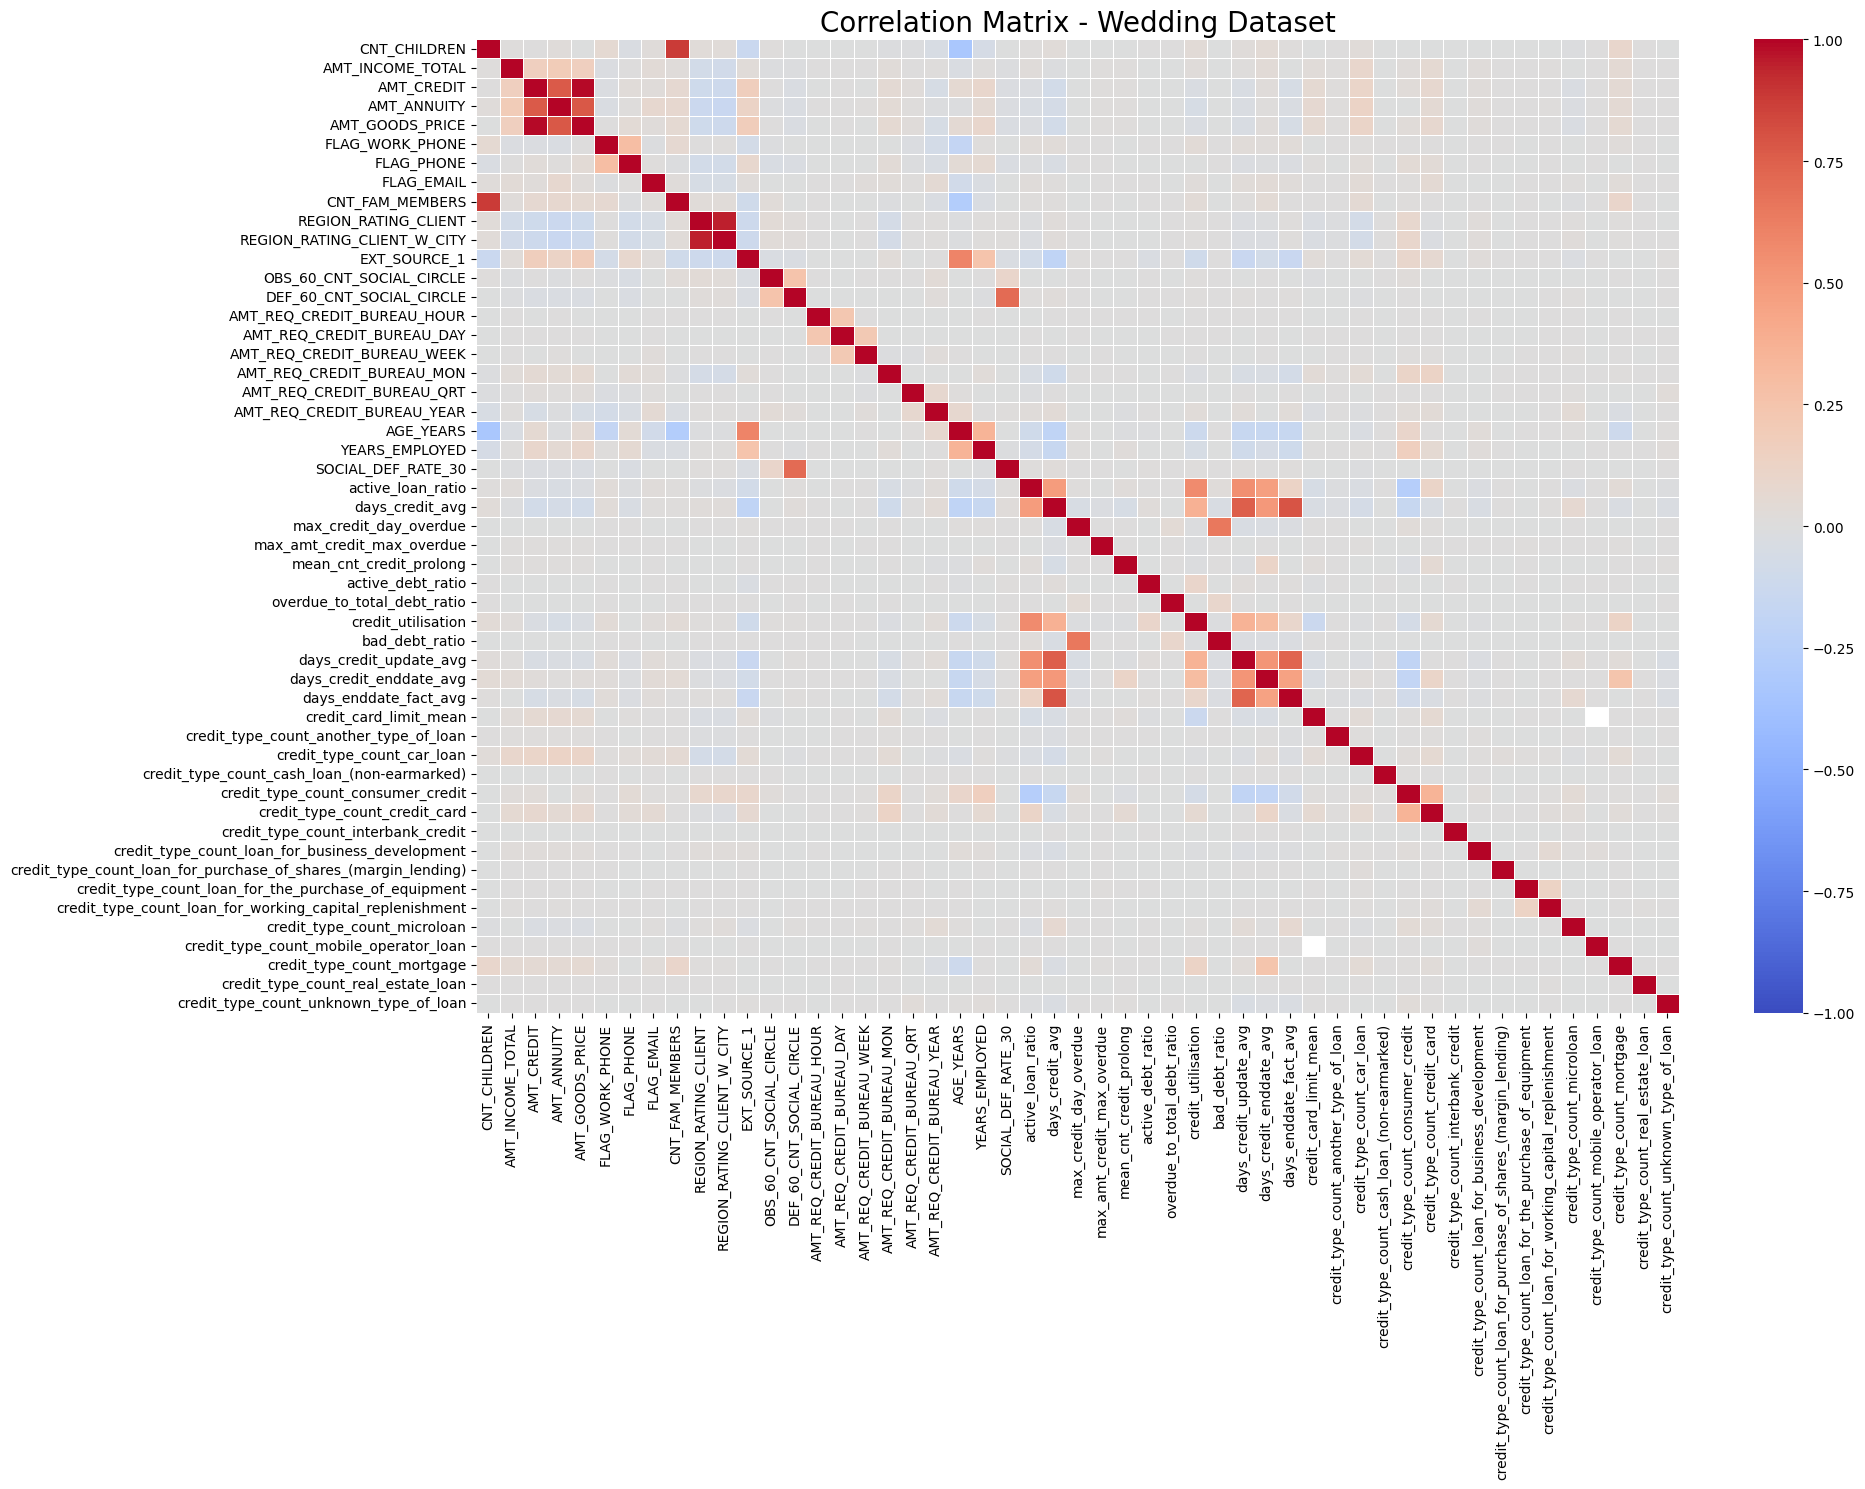

<Figure size 640x480 with 0 Axes>

In [32]:
corr_matrix = numeric_features.corr()

# Reduce size for practicality
plt.figure(figsize=(20, 15))
sns.heatmap(
    corr_matrix, annot=False, fmt='.2f', cmap='coolwarm', center=0,
    vmin=-1, vmax=1, square=False, linewidths=0.5)

plt.title('Correlation Matrix - Wedding Dataset', fontsize=20)
plt.tight_layout()
plt.show()

plt.savefig('correlation_matrix.png', dpi=150, bbox_inches='tight')

In [33]:
# check higly correlated variables
high_corr_pairs = []

valid_cols = numeric_features.loc[:, numeric_features.std() > 0].dropna(axis=1, how='all').columns
corr_matrix = numeric_features[valid_cols].corr()
numeric_feature_cols = valid_cols.tolist()


for i in range(len(numeric_feature_cols)):
    for j in range(i + 1, len(numeric_feature_cols)):
        col1 = numeric_feature_cols[i]
        col2 = numeric_feature_cols[j]
        corr_value = corr_matrix.loc[col1, col2]
        if abs(corr_value) > 0.8:
            high_corr_pairs.append((col1, col2, round(corr_value, 4)))

if high_corr_pairs:
    for col1, col2, v in sorted(high_corr_pairs, key=lambda x: abs(x[2]), reverse=True):
        print(f"{col1} vs {col2}: {v}")
else:
    print("No pairs with correlation > 0.8")


AMT_CREDIT vs AMT_GOODS_PRICE: 0.987
REGION_RATING_CLIENT vs REGION_RATING_CLIENT_W_CITY: 0.9508
CNT_CHILDREN vs CNT_FAM_MEMBERS: 0.8792


In [34]:
numeric_feature_cols = numeric_features.columns.tolist()
target_corr = numeric_features.corrwith(merged_df['TARGET']).abs()

to_drop       = set()
checked_pairs = []

for i in range(len(numeric_feature_cols)):
    for j in range(i + 1, len(numeric_feature_cols)):
        col1       = numeric_feature_cols[i]
        col2       = numeric_feature_cols[j]
        corr_value = corr_matrix.loc[col1, col2]

        if abs(corr_value) > 0.8:
            checked_pairs.append((col1, col2, corr_value))
            if target_corr[col1] < target_corr[col2]:
                to_drop.add(col1)
            else:
                to_drop.add(col2)

merged_df_reduced = merged_df.drop(columns=list(to_drop))
numeric_features = numeric_features.drop(columns=list(to_drop))
print(to_drop)
print(merged_df_reduced.shape)

{'AMT_CREDIT', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT'}
(307511, 60)


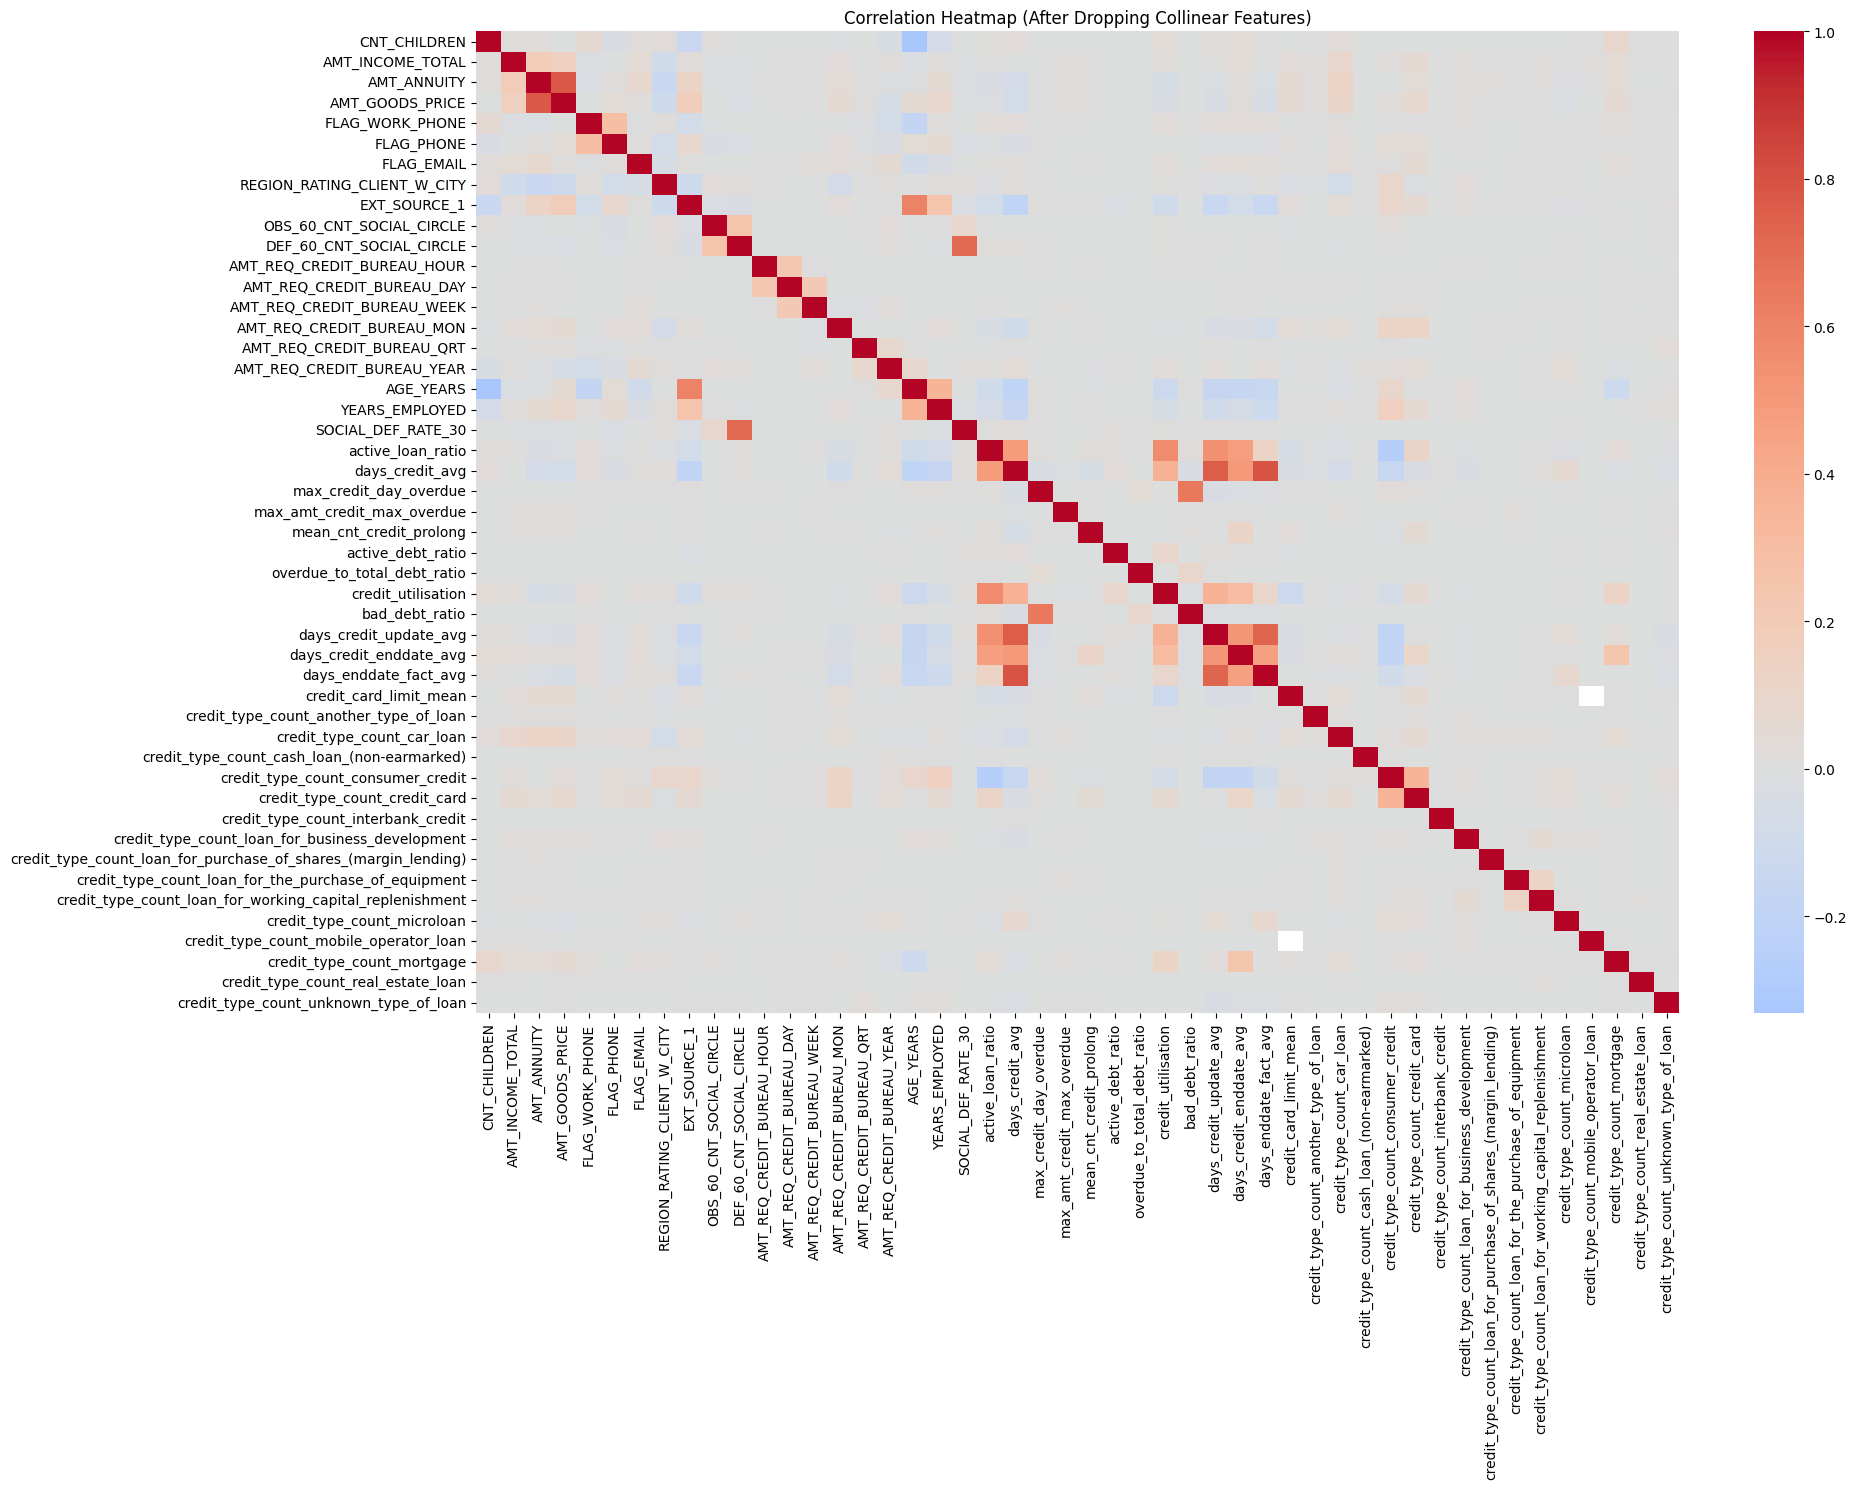

In [35]:
# Check heatmap after dropping highly correlated variables
numeric_feature_cols = numeric_features.columns.tolist()
corr_matrix = numeric_features.corr()

plt.figure(figsize=(20, 15))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (After Dropping Collinear Features)')
plt.tight_layout()
plt.show()

# FINE CLASSING

In [36]:
def fine_classing(rawdata, feature_cols, target_col='BAD', q=20):
    """
    Fine Classing for Scorecard Development
    
    For each numeric characteristic:
    1. Remove missing values → work on non-missing only
    2. Detect and skip pseudo-categorical numerics (e.g. rating scales)
    3. Split non-missing into quantile bins (5% per bin = 20 bins)
    4. Append Missing as a separate last bin
    """
    all_bin_stats = []
    skipped_categorical = []

    for col in feature_cols:
        if col == target_col:
            continue

        data_working = rawdata[[col, target_col]].copy()

        # ── Step 1: Separate missing vs non-missing ──────────────────────
        missing_mask  = data_working[col].isna()
        non_missing   = data_working[~missing_mask]
        n_missing     = missing_mask.sum()
        n_remaining   = len(non_missing)           # Total - Missing = Remaining
        n_unique      = non_missing[col].nunique()
        col_min       = non_missing[col].min()
        col_max       = non_missing[col].max()

        # ── Step 2: Detect pseudo-categorical numerics ───────────────────
        # Flag if: few unique values AND looks like a scale (integers, small range)
        is_small_int_range = (
            n_unique <= 10 and                        # few unique values
            (non_missing[col] == non_missing[col].round()).all() and  # all integers
            (col_max - col_min) <= 20                 # small range e.g. 1-5, 0-10
        )

        if is_small_int_range:
            skipped_categorical.append(col)
            continue  # skip — treat separately as categorical

        # ── Step 3: Skip if not enough unique values to bin ──────────────
        if n_unique <= 1:
            continue

        # ── Step 4: Determine actual number of bins ───────────────────────
        # 5% per bin = 20 bins, but constrained by data
        actual_q = min(q, n_unique, max(2, n_remaining // 20))

        try:
            # ── Step 5: Quantile bin the non-missing values ───────────────
            bins = pd.qcut(
                non_missing[col],
                q=actual_q,
                duplicates='drop',
                precision=4
            )

            non_missing_binned = non_missing.copy()
            non_missing_binned['Bin'] = bins

            bin_stats = non_missing_binned.groupby('Bin', observed=False)[target_col].agg(
                Count='size',
                Bad='sum'
            )
            bin_stats['Good']     = bin_stats['Count'] - bin_stats['Bad']
            bin_stats['Bad_Rate'] = bin_stats['Bad'] / bin_stats['Count']
            bin_stats             = bin_stats.reset_index()
            bin_stats['Bin_Range'] = bin_stats['Bin'].astype(str)
            bin_stats             = bin_stats.drop(columns=['Bin']).set_index('Bin_Range')

            # ── Step 6: Append Missing bin at the bottom ──────────────────
            if n_missing > 0:
                missing_bad  = data_working.loc[missing_mask, target_col].sum()
                missing_good = n_missing - missing_bad
                missing_row  = pd.DataFrame({
                    'Count':    [n_missing],
                    'Bad':      [missing_bad],
                    'Good':     [missing_good],
                    'Bad_Rate': [missing_bad / n_missing if n_missing > 0 else 0]
                }, index=['Missing'])
                bin_stats = pd.concat([bin_stats, missing_row])

            all_bin_stats.append((col, bin_stats))

        except Exception as e:
            print(f"Skipping {col}: {e}")
            continue

    # ── Summary ───────────────────────────────────────────────────────────
    print(f"\n✅ Fine classed : {len(all_bin_stats)} variables")
    print(f"⚠️  Skipped (pseudo-categorical): {len(skipped_categorical)}")
    if skipped_categorical:
        print(f"   → {skipped_categorical}")

    if not all_bin_stats:
        raise ValueError("No valid features were binned.")

    fine_class_df = pd.concat(
        [stats for _, stats in all_bin_stats],
        keys=[name for name, _ in all_bin_stats],
        names=['Feature_Name', 'Bin_Range']
    )
    return fine_class_df, skipped_categorical


# ── Run it ────────────────────────────────────────────────────────────────
fine_class_df, pseudo_cat_cols = fine_classing(
    merged_df_reduced,
    numeric_features.columns.tolist(),
    target_col='TARGET', 
    q=20
)

fine_class_df


✅ Fine classed : 29 variables
⚠️  Skipped (pseudo-categorical): 19
   → ['FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'REGION_RATING_CLIENT_W_CITY', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'credit_type_count_another_type_of_loan', 'credit_type_count_car_loan', 'credit_type_count_cash_loan_(non-earmarked)', 'credit_type_count_interbank_credit', 'credit_type_count_loan_for_business_development', 'credit_type_count_loan_for_purchase_of_shares_(margin_lending)', 'credit_type_count_loan_for_the_purchase_of_equipment', 'credit_type_count_loan_for_working_capital_replenishment', 'credit_type_count_mobile_operator_loan', 'credit_type_count_mortgage', 'credit_type_count_real_estate_loan', 'credit_type_count_unknown_type_of_loan']


Count    Bad    Good  \
Feature_Name                  Bin_Range                                      
CNT_CHILDREN                  (-0.0001, 1.0]         276490  22063  254427   
                              (1.0, 2.0]              26749   2333   24416   
                              (2.0, 19.0]              4272    429    3843   
AMT_INCOME_TOTAL              (25649.9999, 67500.0]   21266   1677   19589   
                              (67500.0, 81000.0]      12125   1058   11067   
...                                                     ...    ...     ...   
credit_type_count_credit_card (3.0, 4.0]               8505    796    7709   
                              (4.0, 21.0]              8313    870    7443   
                              Missing                 45154   4598   40556   
credit_type_count_microloan   (-0.0001, 79.0]        262357  20227  242130   
                              Missing                 45154   4598   40556   

                                                     Bad_Rate  
Feature_Name                  Bin_Range                        
CNT_CHILDREN                  (-0.0001, 1.0]         0.079797  
                              (1.0, 2.0]             0.087218  
                              (2.0, 19.0]            0.100421  
AMT_INCOME_TOTAL              (25649.9999, 67500.0]  0.078858  
                              (67500.0, 81000.0]     0.087258  
...                                                       ...  
credit_type_count_credit_card (3.0, 4.0]             0.093592  
                              (4.0, 21.0]            0.104655  
                              Missing                0.101829  
credit_type_count_microloan   (-0.0001, 79.0]        0.077097  
                              Missing                0.101829  

[327 rows x 4 columns]

# WOE Calculation

In [37]:
# function to calculate IV
def calc_iv_from_bins(fine_class_df, target_col='TARGET'):
    iv_summary = []

    for feature in fine_class_df.index.get_level_values(0).unique():
        feature_data = fine_class_df.loc[feature].copy()

        # Total good and bad
        total_good = feature_data['Good'].sum()
        total_bad = feature_data['Bad'].sum()

        if total_good == 0 or total_bad == 0:
            continue

        # Compute distributions
        feature_data['Dist_Good'] = feature_data['Good'] / total_good
        feature_data['Dist_Bad'] = feature_data['Bad'] / total_bad

        # Replace 0 with small value to avoid log(0)
        feature_data['Dist_Good'] = feature_data['Dist_Good'].replace(0, 0.0001)
        feature_data['Dist_Bad'] = feature_data['Dist_Bad'].replace(0, 0.0001)

        # WOE formula: ln(% of Goods / % of Bads)
        feature_data['WOE'] = np.log(feature_data['Dist_Good'] / feature_data['Dist_Bad'])

        # IV formula: (Dist_Good - Dist_Bad) × WOE
        feature_data['IV'] = (feature_data['Dist_Good'] - feature_data['Dist_Bad']) * feature_data['WOE']

        total_iv = feature_data['IV'].sum()
        iv_summary.append({'Variable': feature, 'IV': total_iv})

    # Final IV table sorted by IV descending
    iv_table = pd.DataFrame(iv_summary).sort_values('IV', ascending=False).reset_index(drop=True)

    return iv_table

# Correct usage for WOE using fine_class_df

iv_table = calc_iv_from_bins(fine_class_df)
iv_table['IV'] = iv_table['IV'].round(4)
print(iv_table)

                             Variable      IV
0                        EXT_SOURCE_1  0.1558
1                     days_credit_avg  0.1206
2                      YEARS_EMPLOYED  0.1134
3                     AMT_GOODS_PRICE  0.1026
4                  credit_utilisation  0.0962
5              days_credit_update_avg  0.0915
6                           AGE_YEARS  0.0865
7                   active_loan_ratio  0.0860
8             days_credit_enddate_avg  0.0753
9               days_enddate_fact_avg  0.0710
10                  active_debt_ratio  0.0537
11                        AMT_ANNUITY  0.0317
12             credit_card_limit_mean  0.0280
13         max_amt_credit_max_overdue  0.0253
14      credit_type_count_credit_card  0.0205
15         AMT_REQ_CREDIT_BUREAU_YEAR  0.0182
16  credit_type_count_consumer_credit  0.0171
17          AMT_REQ_CREDIT_BUREAU_MON  0.0150
18          AMT_REQ_CREDIT_BUREAU_QRT  0.0137
19                     bad_debt_ratio  0.0128
20        credit_type_count_microl

In [38]:
# function to plot IV
def plot_woe_from_bins(fine_class_df):
    for feature in fine_class_df.index.get_level_values(0).unique():
        result = fine_class_df.loc[feature].copy()

        total_bad  = result['Bad'].sum()
        total_good = result['Good'].sum()

        if total_bad == 0 or total_good == 0:
            continue

        result['Dist_Bad']  = (result['Bad']  / total_bad).replace(0, 0.0001)
        result['Dist_Good'] = (result['Good'] / total_good).replace(0, 0.0001)
        result['WOE'] = np.log(result['Dist_Good'] / result['Dist_Bad'])
        result['IV']  = (result['Dist_Good'] - result['Dist_Bad']) * result['WOE']

        if "Missing" in result.index:
            result = pd.concat([result[result.index != "Missing"], result.loc[["Missing"]]])

        fig, ax1 = plt.subplots(figsize=(12, 5))

        x = range(len(result))
        ax1.bar(x, result['Count'], color='lightblue', alpha=0.7)
        ax1.set_ylabel('Count', color='steelblue')
        ax1.tick_params(axis='y', labelcolor='steelblue')

        ax2 = ax1.twinx()
        ax2.plot(x, result['WOE'], color='red', marker='o', linewidth=2)
        ax2.axhline(y=0, color='grey', linestyle='--', linewidth=0.8)
        ax2.set_ylabel('WOE', color='red')
        ax2.tick_params(axis='y', labelcolor='red')

        ax1.set_xticks(x)
        ax1.set_xticklabels(result.index, rotation=45, ha='right', fontsize=8)

        plt.title(f'{feature} WOE by Bin (IV: {result["IV"].sum():.4f})')
        fig.tight_layout()
        plt.show()

11


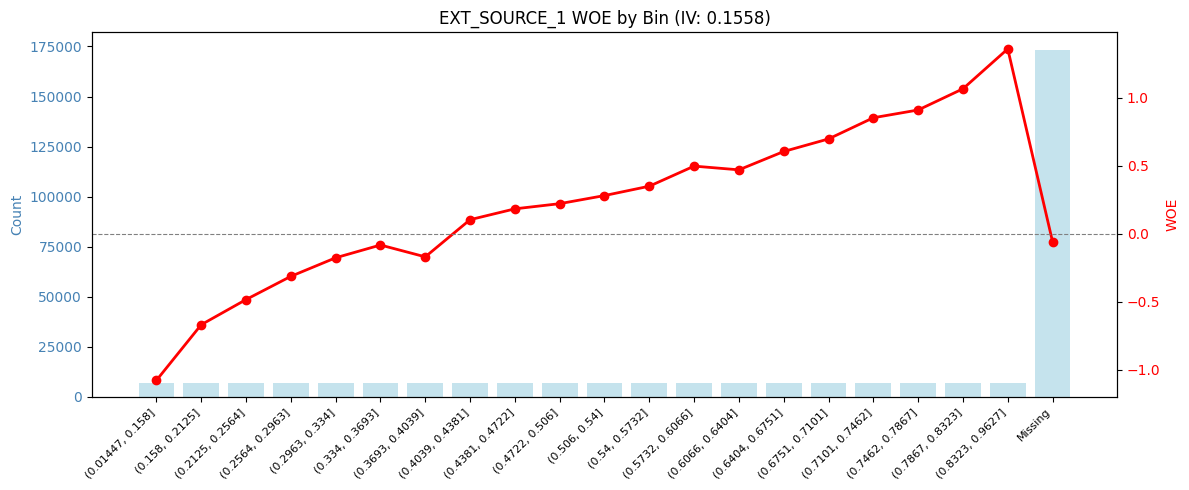

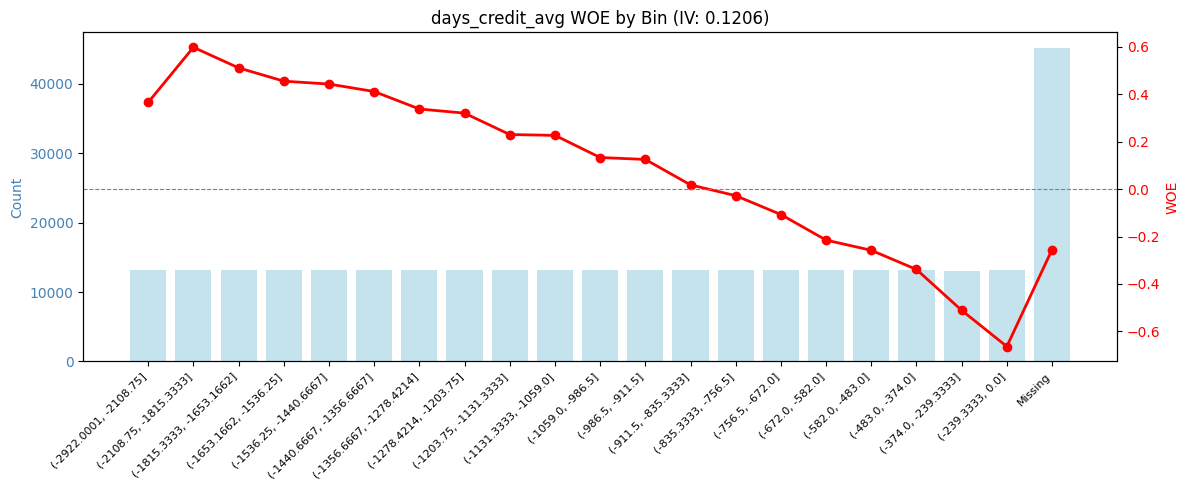

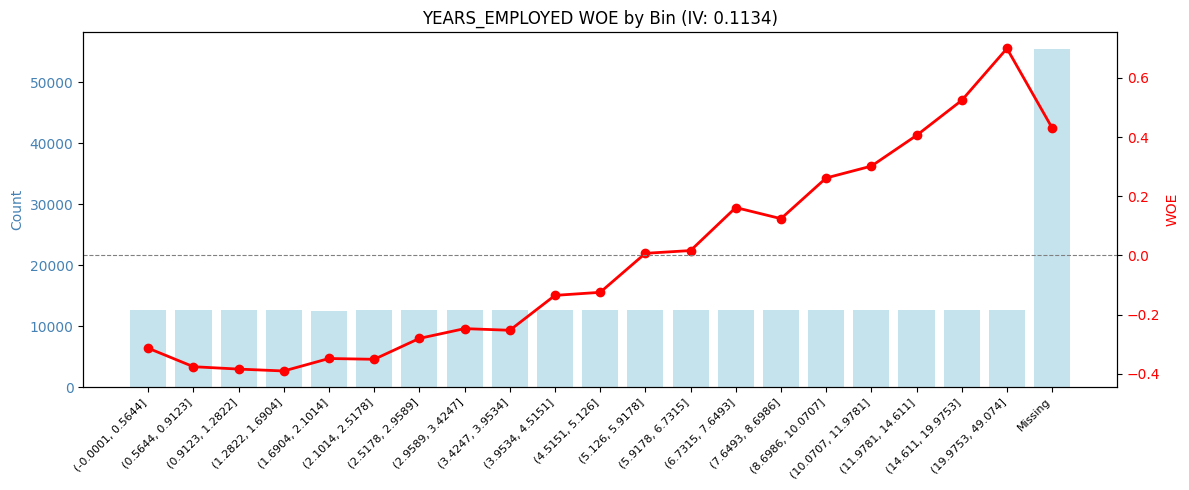

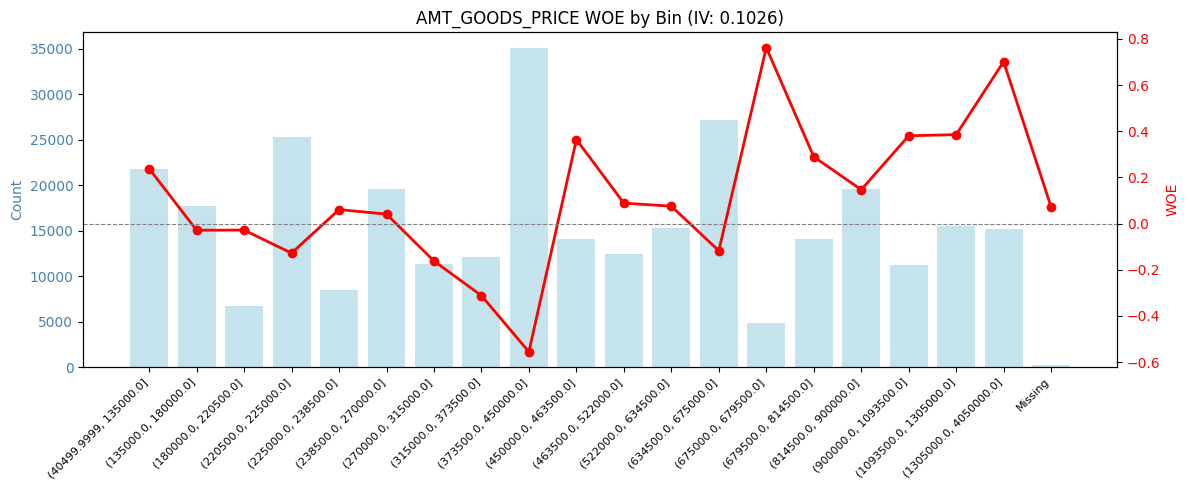

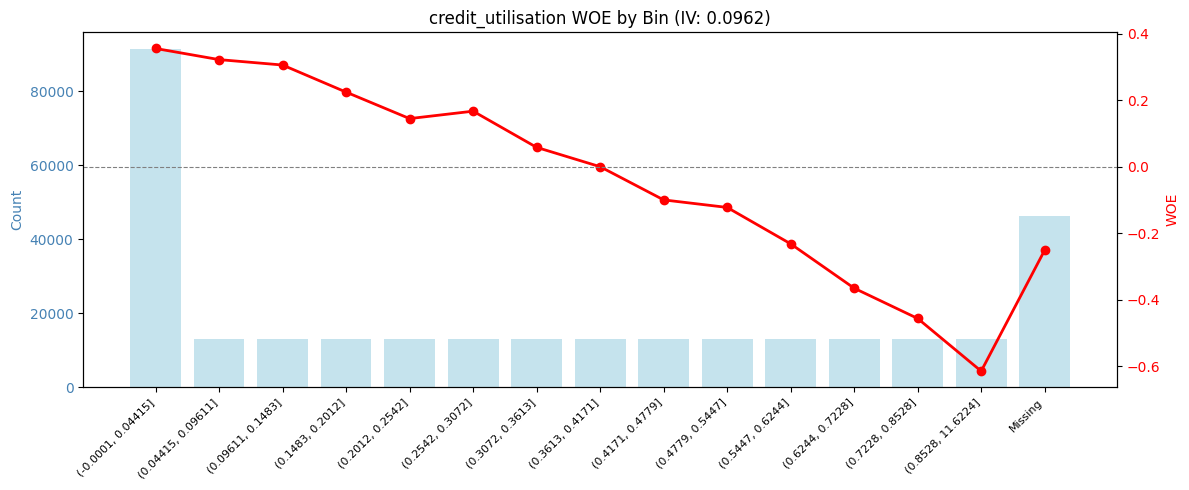

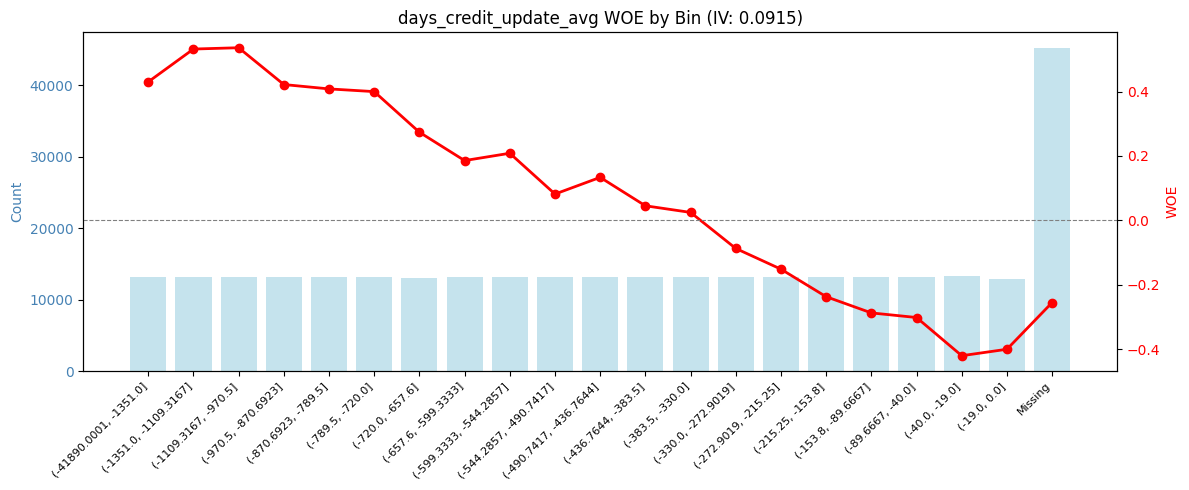

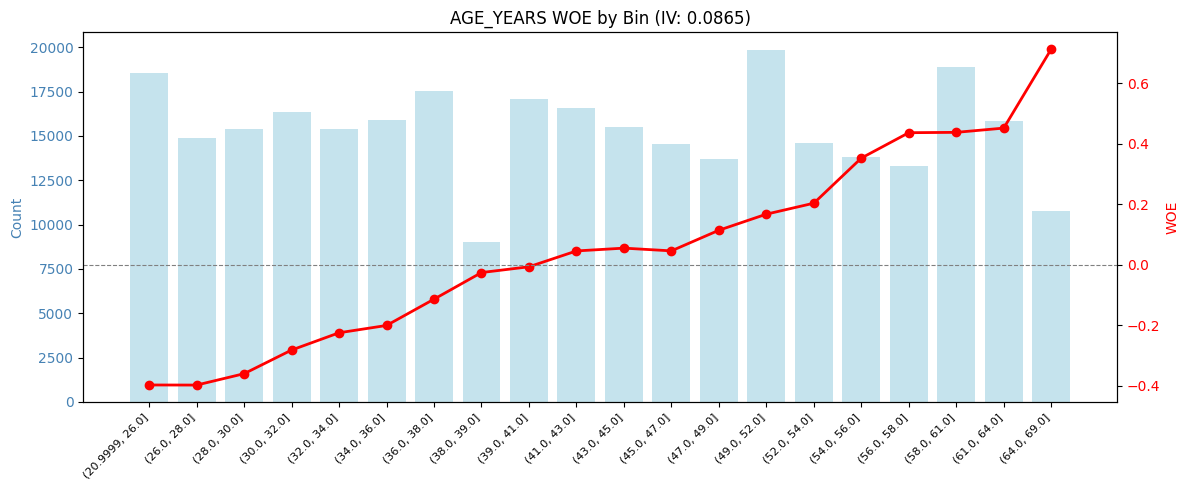

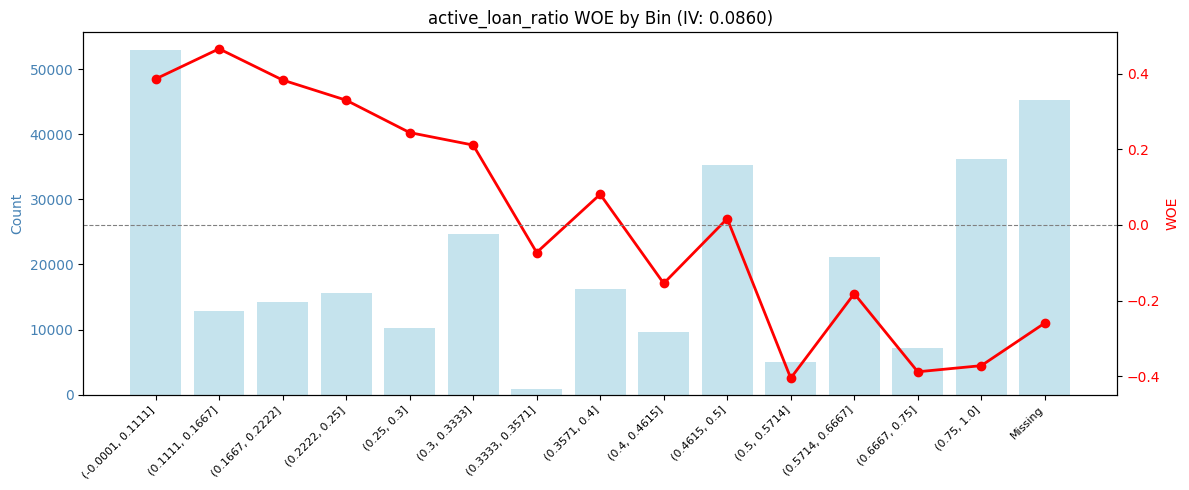

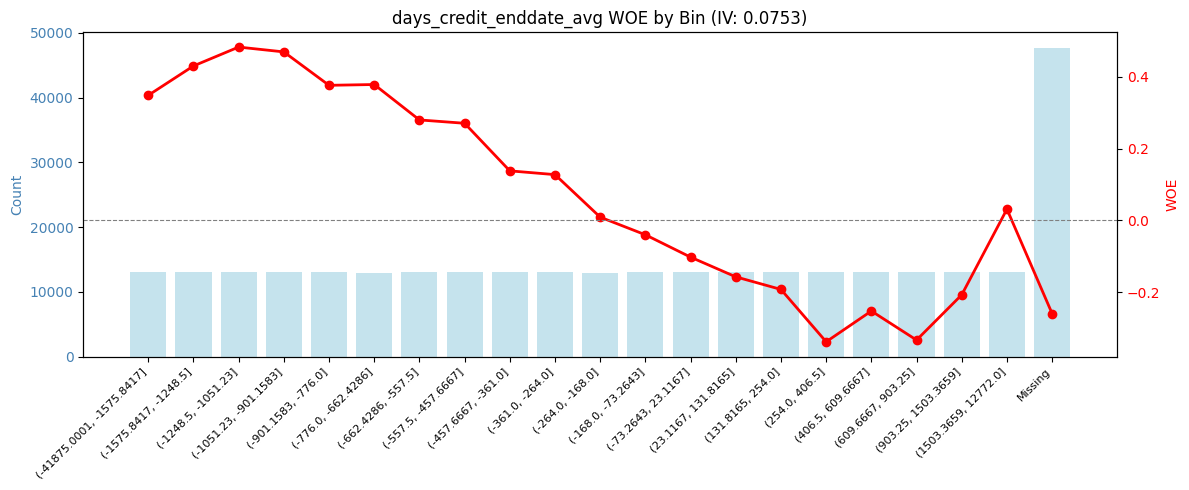

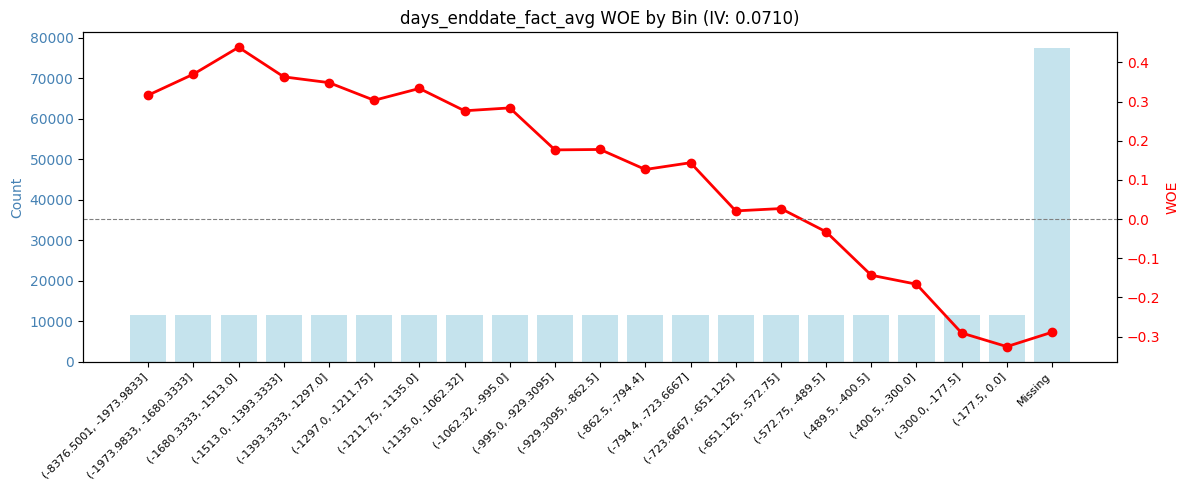

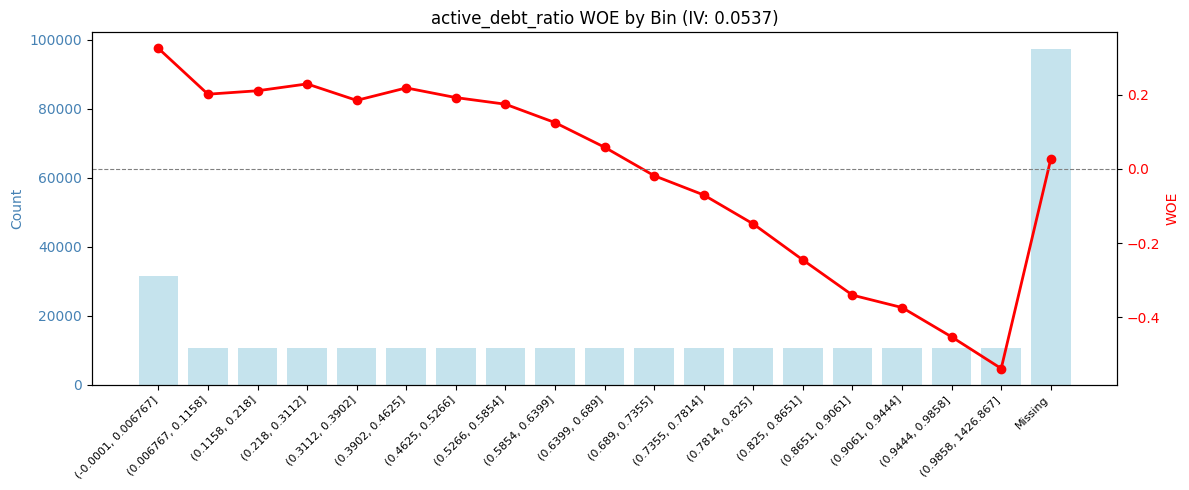

In [39]:
# Filter and remove variables with IV < 0.02 before plotting
selected_features = iv_table[iv_table['IV'] >= 0.05]['Variable'].tolist()
print (len(selected_features))
plot_woe_from_bins(fine_class_df.loc[selected_features])

In [40]:
# helper function to analyse numerical variables

def summary(df, col):
    print(f"\n{'='*40}")
    print(f"Column: {col}")
    print('='*40)
    print(df[col].describe())
    print(f"Missing: {df[col].isna().sum()} ({df[col].isna().mean()*100:.2f}%)")

# COARSE CLASSING 

,Variable,Min_Bin_%,Min_5%_Rule
10,credit_card_limit_mean,0.0357,FAIL
6,AGE_YEARS,0.1054,PASS
8,AMT_ANNUITY,0.1625,PASS
3,AMT_GOODS_PRICE,0.1284,PASS
0,EXT_SOURCE_1,0.0632,PASS
9,REGION_RATING_CLIENT_W_CITY,0.1111,PASS
2,YEARS_EMPLOYED,0.1581,PASS
7,active_debt_ratio,0.0719,PASS
5,active_loan_ratio,0.1764,PASS
12,credit_type_count_credit_card,0.1149,PASS


,Variable,Fine_IV,Coarse_IV,IV_Check,IV_0.02_Check
0,EXT_SOURCE_1,0.1558,0.1318,PASS,PASS
1,days_credit_avg,0.1206,0.1087,PASS,PASS
2,YEARS_EMPLOYED,0.1134,0.1048,PASS,PASS
3,AMT_GOODS_PRICE,0.1026,0.0349,FAIL,PASS
4,credit_utilisation,0.0962,0.0922,PASS,PASS
5,AGE_YEARS,0.0865,0.0800,PASS,PASS
6,active_loan_ratio,0.0860,0.0821,PASS,PASS
7,active_debt_ratio,0.0537,0.0471,PASS,PASS
8,AMT_ANNUITY,0.0317,0.0206,PASS,PASS
9,credit_card_limit_mean,0.0280,0.0265,PASS,PASS


,Variable,IV
0,EXT_SOURCE_1,0.1318
1,days_credit_avg,0.1087
2,YEARS_EMPLOYED,0.1048
3,credit_utilisation,0.0922
4,active_loan_ratio,0.0821
5,AGE_YEARS,0.0800
6,REGION_RATING_CLIENT_W_CITY,0.0512
7,active_debt_ratio,0.0471
8,AMT_GOODS_PRICE,0.0349
9,credit_card_limit_mean,0.0265


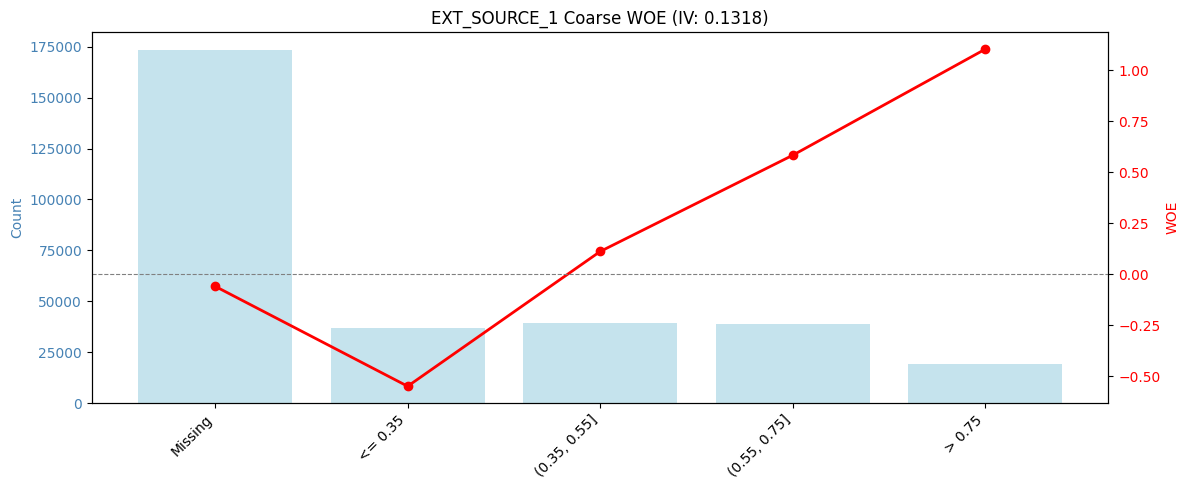

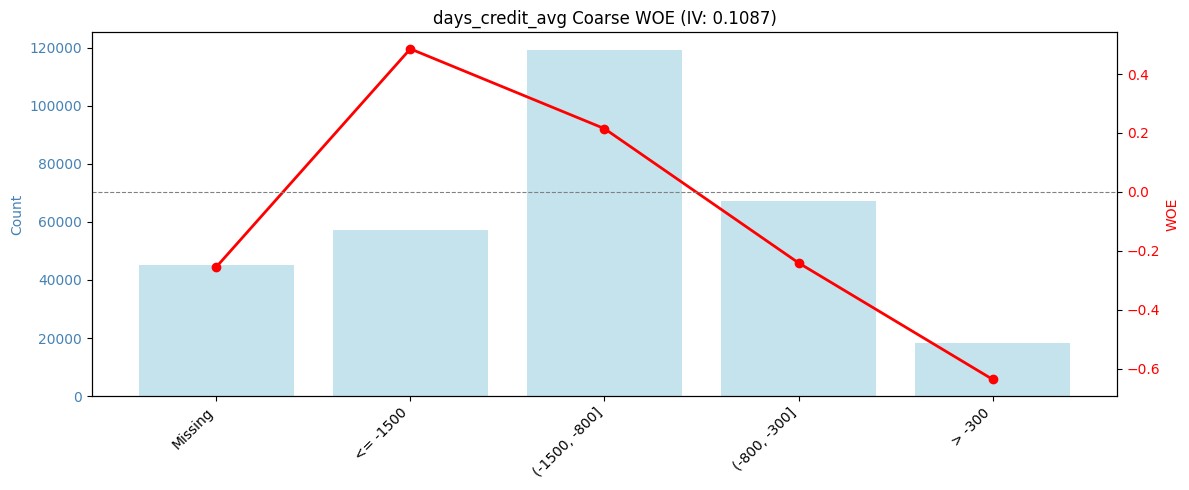

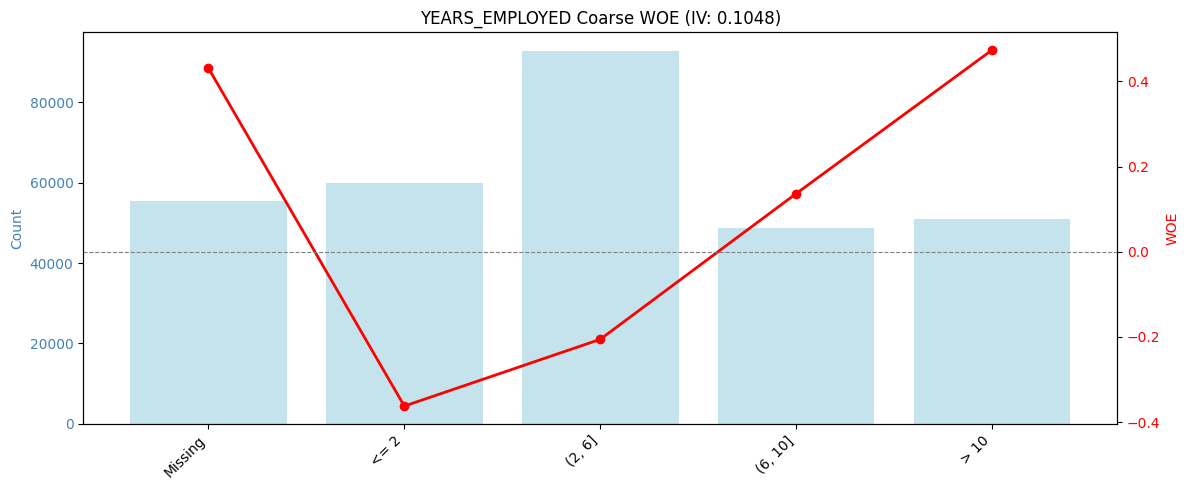

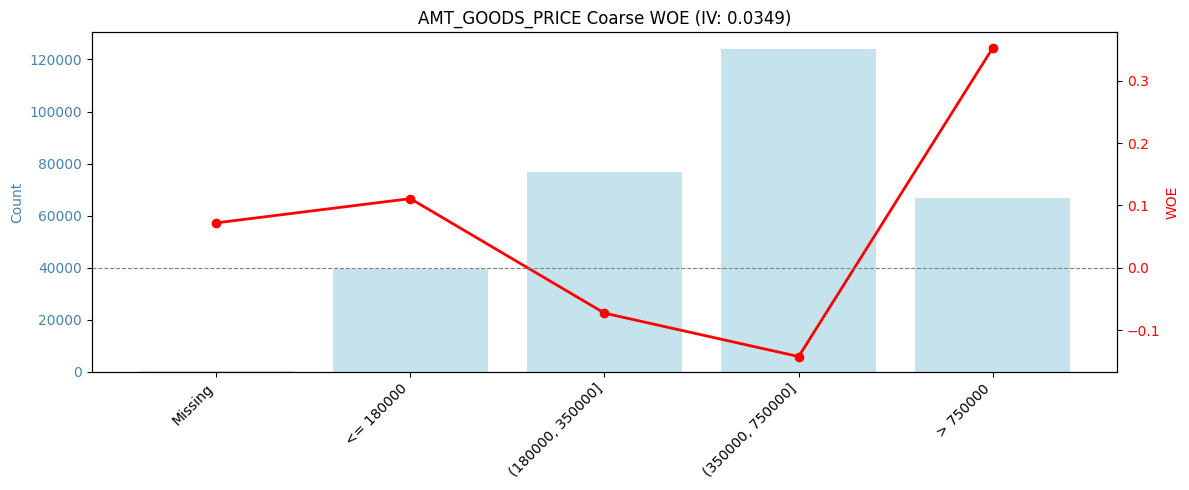

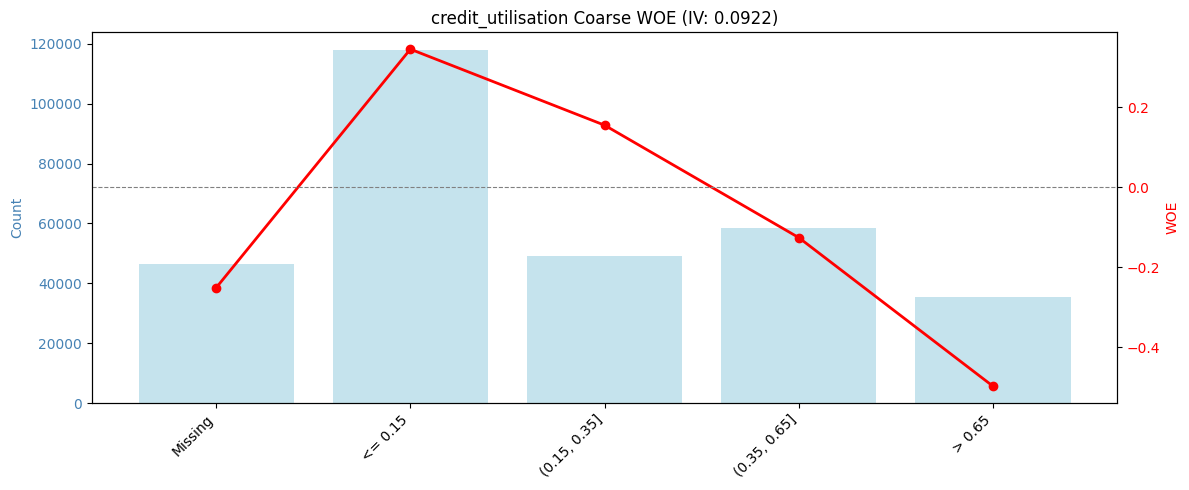

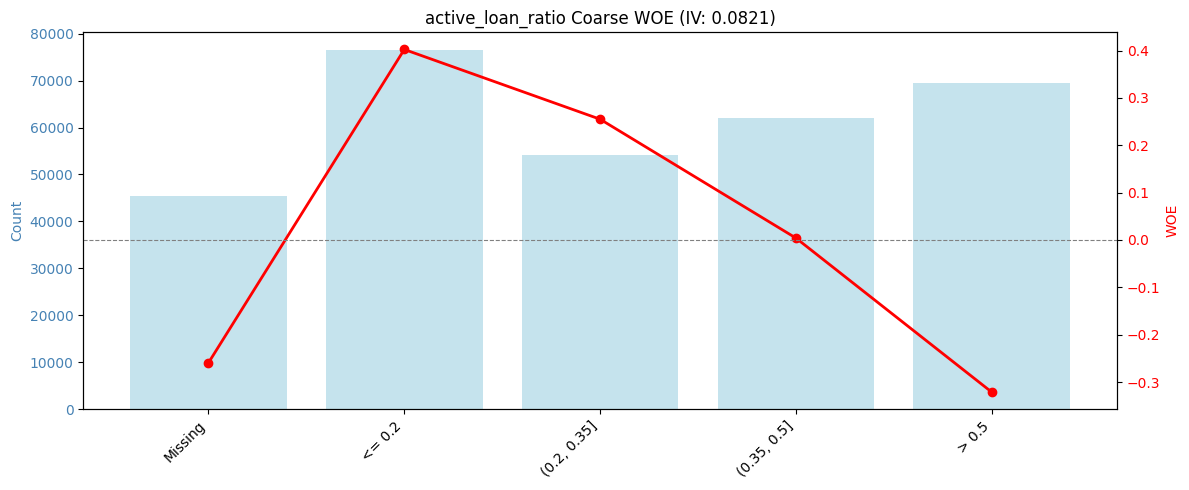

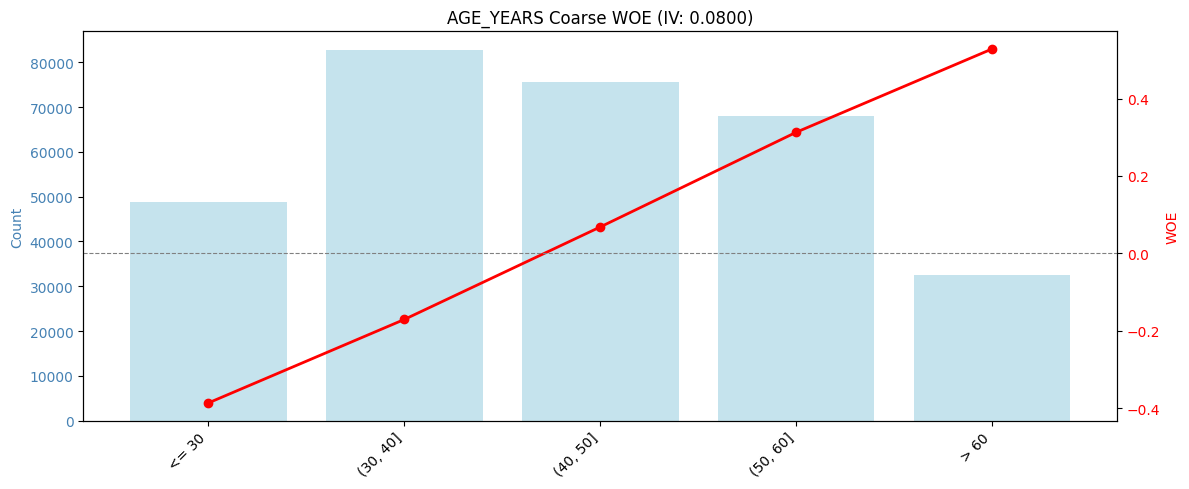

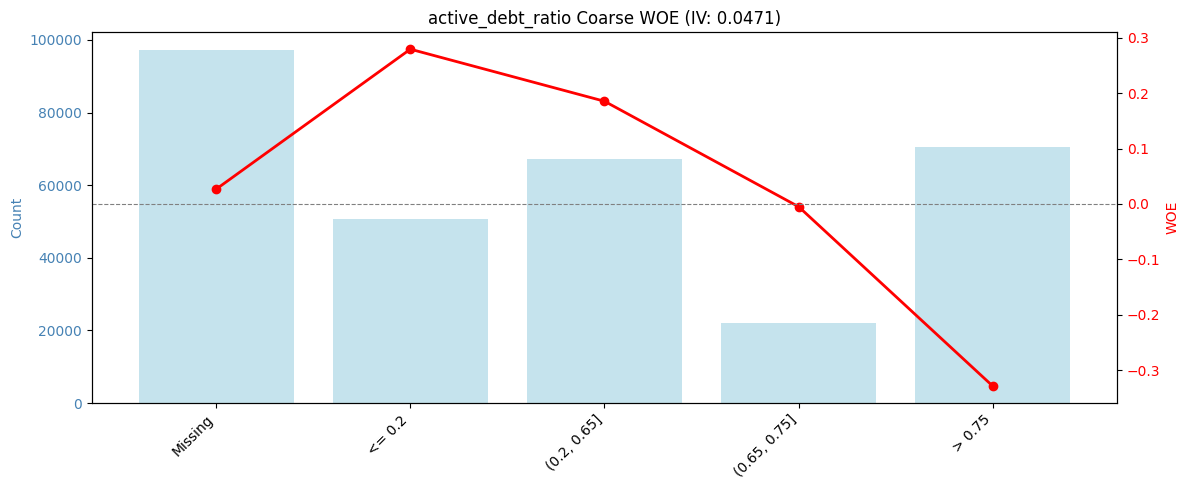

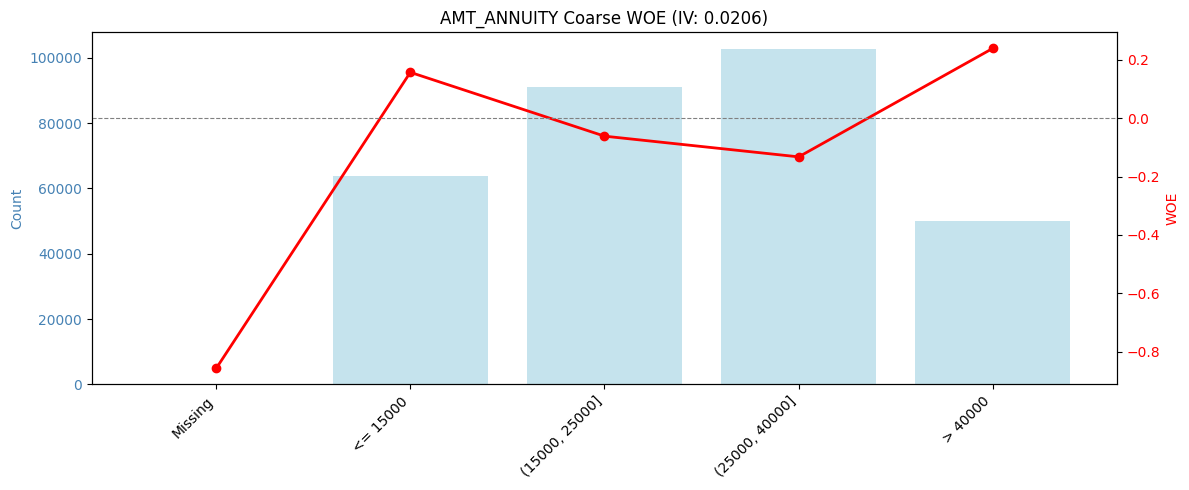

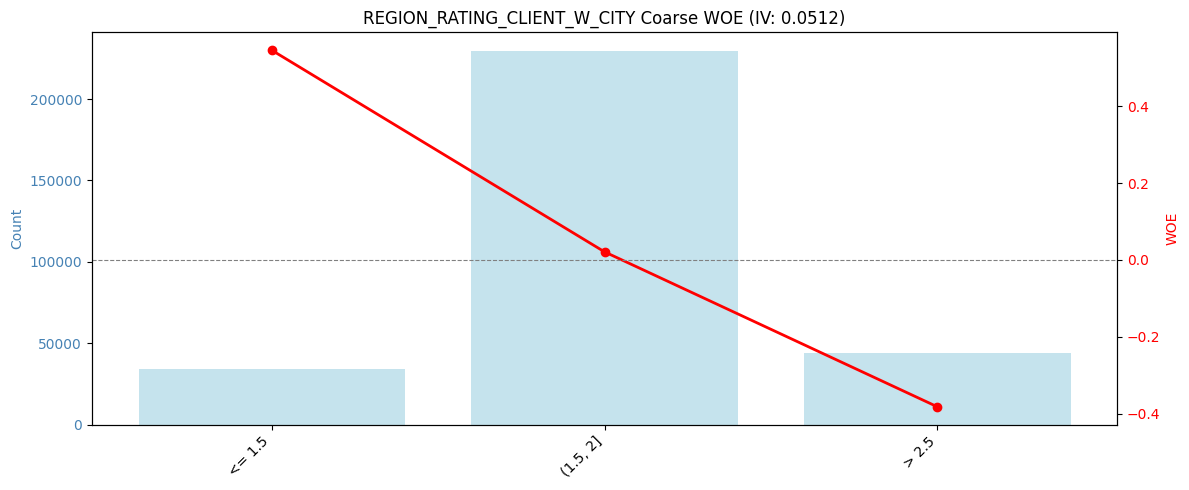

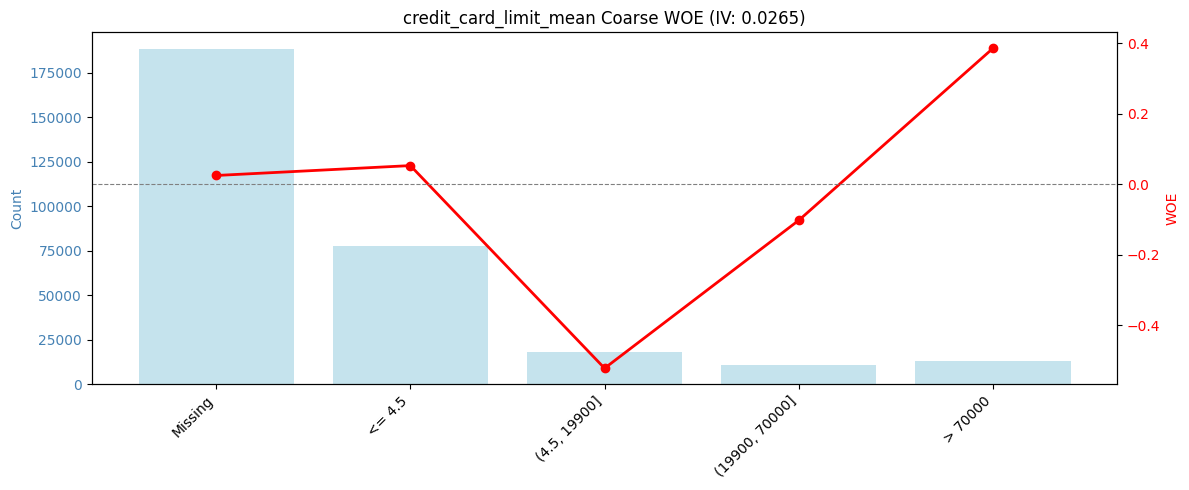

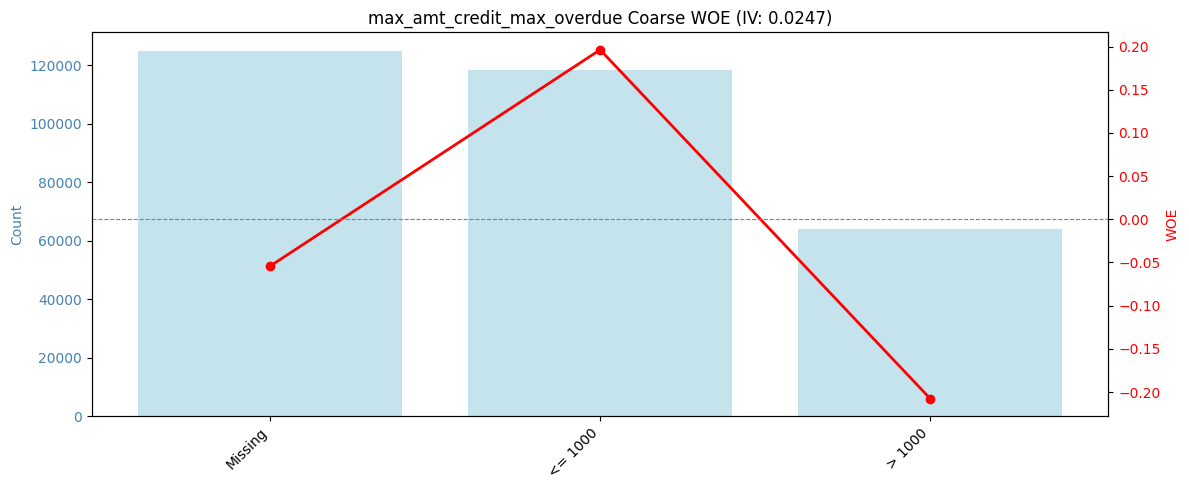

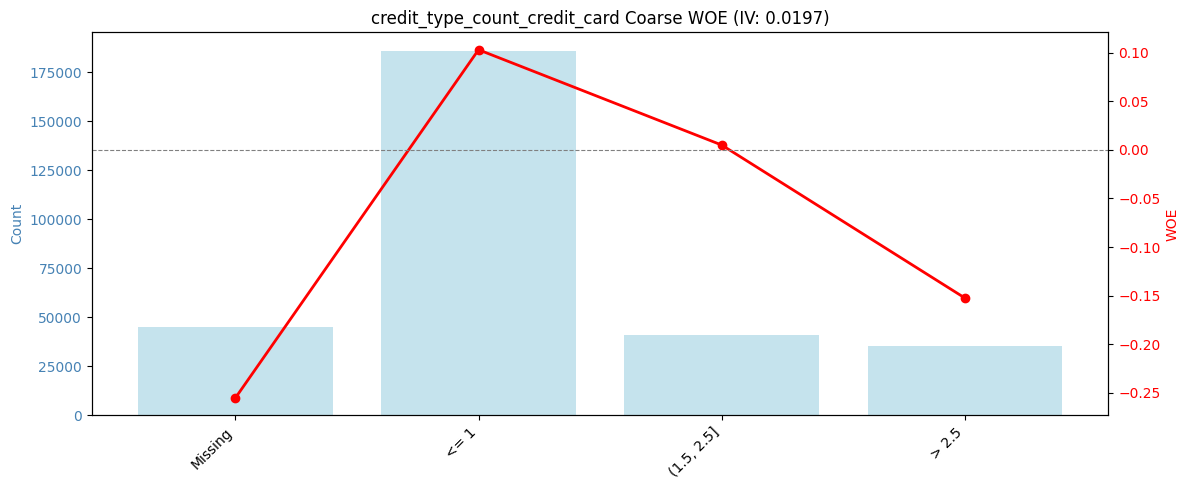

In [41]:

# ---------------------------------------------------------
# 1. MANUAL COARSE BINS
# Edit these cut points
# Keep bins few and wide to minimise IV loss
# Manually specified cut points for each variable. These were determined by looking at the fine-class WOE plots and choosing where to 
# draw boundaries that preserve the WOE trend.
# ---------------------------------------------------------
manual_bins = {
    'EXT_SOURCE_1': [0.35, 0.55, 0.75],
    'days_credit_avg': [-1500, -800, -300],
    'YEARS_EMPLOYED': [2, 6, 10],
    'AMT_GOODS_PRICE': [180000, 350000, 750000],
    'credit_utilisation': [0.15, 0.35, 0.65],
    'active_loan_ratio': [0.20, 0.35, 0.50],
    'AGE_YEARS': [30, 40, 50, 60],
    'active_debt_ratio': [0.2, 0.65, 0.75],
    'AMT_ANNUITY': [15000, 25000, 40000],
    'REGION_RATING_CLIENT_W_CITY': [1.5, 2.0, 2.5],
    'credit_card_limit_mean': [4.5, 19900, 70000],
    'max_amt_credit_max_overdue': [1000],
    'credit_type_count_credit_card': [1, 1.5, 2.5]
}




iv_tolerance = 0.02

# ---------------------------------------------------------
# 2. HELPERS
# ---------------------------------------------------------
def manual_bin(s, cuts):
    bins = [-np.inf] + cuts + [np.inf]
    labels = [f"{i+1:02d}" for i in range(len(bins) - 1)]
    out = pd.cut(s, bins=bins, labels=labels, include_lowest=True, right=True).astype(object)
    out = out.where(s.notna(), '00')
    return out

def build_summary(df, rules, target='TARGET'):
    rows = []
    for var, cuts in rules.items():
        tmp = df[[var, target]].copy()
        tmp['Bin'] = manual_bin(tmp[var], cuts)

        g = tmp.groupby('Bin', observed=False)[target].agg(['count', 'sum']).rename(
            columns={'count': 'Count', 'sum': 'Bad'}
        )
        g['Good'] = g['Count'] - g['Bad']
        g['Bad_Rate'] = g['Bad'] / g['Count']
        g = g.reset_index()
        g['Variable'] = var
        rows.append(g[['Variable', 'Bin', 'Count', 'Good', 'Bad', 'Bad_Rate']])

    return pd.concat(rows).set_index(['Variable', 'Bin'])

def calc_iv(fine_class_df):
    out = []
    for var in fine_class_df.index.get_level_values(0).unique():
        d = fine_class_df.loc[var].copy()
        total_good = d['Good'].sum()
        total_bad = d['Bad'].sum()
        d['Dist_Good'] = (d['Good'] / total_good).replace(0, 0.0001)
        d['Dist_Bad'] = (d['Bad'] / total_bad).replace(0, 0.0001)
        d['WOE'] = np.log(d['Dist_Good'] / d['Dist_Bad'])
        d['IV'] = (d['Dist_Good'] - d['Dist_Bad']) * d['WOE']
        out.append({'Variable': var, 'IV': d['IV'].sum()})
    return pd.DataFrame(out).sort_values('IV', ascending=False).reset_index(drop=True)

    
#Verifies that every bin contains at least 5% of the total sample. 
def check_bin_size(fine_class_df, total_n):
    rows = []
    for var in fine_class_df.index.get_level_values(0).unique():
        d = fine_class_df.loc[var].copy()
        d = d[d.index != '00']   # exclude missing bin from 5% rule
        min_pct = (d['Count'] / total_n).min()
        rows.append({
            'Variable': var,
            'Min_Bin_%': round(min_pct, 4),
            'Min_5%_Rule': 'PASS' if min_pct >= 0.05 else 'FAIL'
        })
    return pd.DataFrame(rows).sort_values(['Min_5%_Rule', 'Variable'])


# Compares the fine IV range to the coarse IV range.
# A "PASS" means coarse classing did not degrade predictive power enough to fall into a lower IV bracket.
def compare_iv(fine_iv_table, coarse_iv_table):
    def iv_range(iv):
        if 0.30 <= iv <= 0.50:
            return '0.30-0.50'
        elif 0.10 <= iv < 0.30:
            return '0.10-0.30'
        elif 0.02 <= iv < 0.10:
            return '0.02-0.10'
        else:
            return 'OUT_OF_RANGE'

    x = fine_iv_table[['Variable', 'IV']].rename(columns={'IV': 'Fine_IV'}).merge(
        coarse_iv_table[['Variable', 'IV']].rename(columns={'IV': 'Coarse_IV'}),
        on='Variable',
        how='inner'
    )

    x['Fine_IV_Range'] = x['Fine_IV'].apply(iv_range)
    x['Coarse_IV_Range'] = x['Coarse_IV'].apply(iv_range)
    x['IV_Drop'] = x['Fine_IV'] - x['Coarse_IV']

    x['IV_Check'] = np.where(
        x['Fine_IV_Range'] == x['Coarse_IV_Range'],
        'PASS',
        'FAIL'
    )

    x['IV_0.02_Check'] = np.where(x['Coarse_IV'] >= 0.02, 'PASS', 'FAIL')
    x.drop(columns= ['Fine_IV_Range', 'Coarse_IV_Range','IV_Drop' ], inplace=True)
    return x


def plot_coarse_woe(fine_class_df, manual_bins):
    for var in fine_class_df.index.get_level_values(0).unique():
        d = fine_class_df.loc[var].copy()

        total_good = d['Good'].sum()
        total_bad = d['Bad'].sum()

        d['Dist_Good'] = (d['Good'] / total_good).replace(0, 0.0001)
        d['Dist_Bad'] = (d['Bad'] / total_bad).replace(0, 0.0001)
        d['WOE'] = np.log(d['Dist_Good'] / d['Dist_Bad'])
        d['IV'] = (d['Dist_Good'] - d['Dist_Bad']) * d['WOE']

        d = d.reset_index()
        d['order'] = d['Bin'].astype(str).astype(int)
        d = d.sort_values('order')

        cuts = manual_bins[var]
        full_bins = [-np.inf] + cuts + [np.inf]

        bin_labels = []
        for b in d['Bin'].astype(str):
            if b == '00':
                bin_labels.append('Missing')
            else:
                i = int(b)
                left = full_bins[i - 1]
                right = full_bins[i]

                if np.isneginf(left):
                    label = f"<= {right:g}"
                elif np.isposinf(right):
                    label = f"> {left:g}"
                else:
                    label = f"({left:g}, {right:g}]"

                bin_labels.append(label)

        fig, ax1 = plt.subplots(figsize=(12, 5))
        x = range(len(d))

        ax1.bar(x, d['Count'], color='lightblue', alpha=0.7)
        ax1.set_ylabel('Count', color='steelblue')
        ax1.tick_params(axis='y', labelcolor='steelblue')

        ax2 = ax1.twinx()
        ax2.plot(x, d['WOE'], color='red', marker='o', linewidth=2)
        ax2.axhline(y=0, color='grey', linestyle='--', linewidth=0.8)
        ax2.set_ylabel('WOE', color='red')
        ax2.tick_params(axis='y', labelcolor='red')

        ax1.set_xticks(list(x))
        ax1.set_xticklabels(bin_labels, rotation=45, ha='right')

        plt.title(f'{var} Coarse WOE (IV: {d["IV"].sum():.4f})')
        fig.tight_layout()
        plt.show()


# ---------------------------------------------------------
# 3. RUN
# Assumes merged_df_reduced and fine-class iv_table already exist
# ---------------------------------------------------------
coarse_fine_class_df = build_summary(merged_df_reduced, manual_bins, target='TARGET')
coarse_iv_table = calc_iv(coarse_fine_class_df)
coarse_iv_table['IV'] = coarse_iv_table['IV'].round(4)


bin_check = check_bin_size(coarse_fine_class_df, len(merged_df_reduced))
iv_check = compare_iv(iv_table, coarse_iv_table)

display(bin_check)
display(iv_check)
display(coarse_iv_table)

plot_coarse_woe(coarse_fine_class_df, manual_bins)


In [42]:
# Drops two variables that failed the IV threshold check after coarse classing. They were too weak to include in the scorecard.
coarse_fine_class_df = coarse_fine_class_df.drop(index=['AMT_GOODS_PRICE', 'credit_type_count_credit_card'], level='Variable')

# CATEGORICAL

## FINE CLASSING- Categorical 

,Variable,IV
0,OCCUPATION_TYPE_FINE,0.0829
1,ORGANIZATION_TYPE_FINE,0.0734
2,NAME_INCOME_TYPE_FINE,0.0584
3,REGION_RATING_CLIENT_W_CITY_FINE,0.0512
4,NAME_EDUCATION_TYPE_FINE,0.0508
5,NAME_FAMILY_STATUS_FINE,0.0219
6,credit_type_count_mortgage_FINE,0.0216
7,credit_type_count_car_loan_FINE,0.0201
8,NAME_HOUSING_TYPE_FINE,0.0157
9,NAME_CONTRACT_TYPE_FINE,0.0150


Fine-classed categorical variables with IV >= 0.02:
['OCCUPATION_TYPE_FINE', 'ORGANIZATION_TYPE_FINE', 'NAME_INCOME_TYPE_FINE', 'REGION_RATING_CLIENT_W_CITY_FINE', 'NAME_EDUCATION_TYPE_FINE', 'NAME_FAMILY_STATUS_FINE', 'credit_type_count_mortgage_FINE', 'credit_type_count_car_loan_FINE']


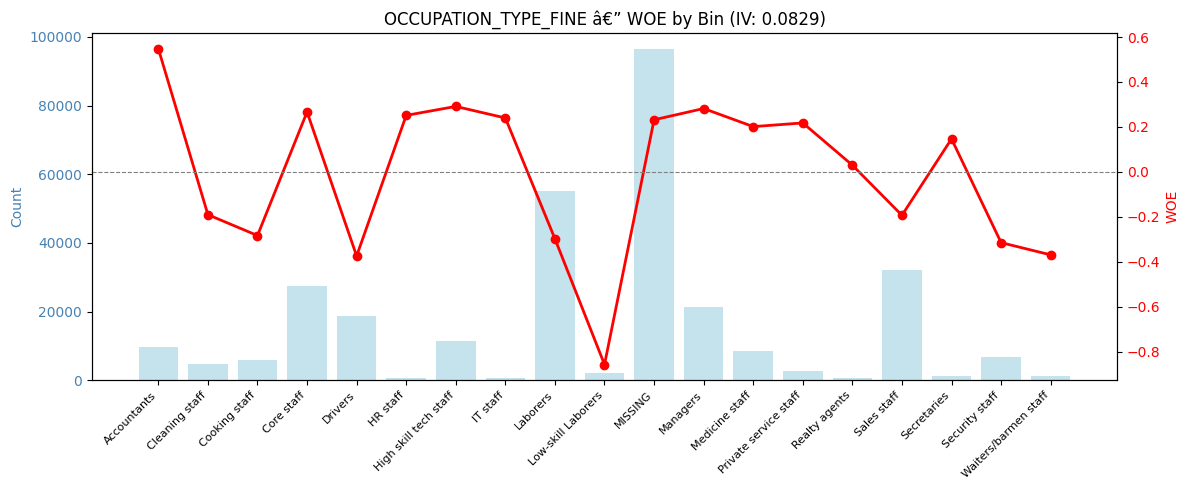

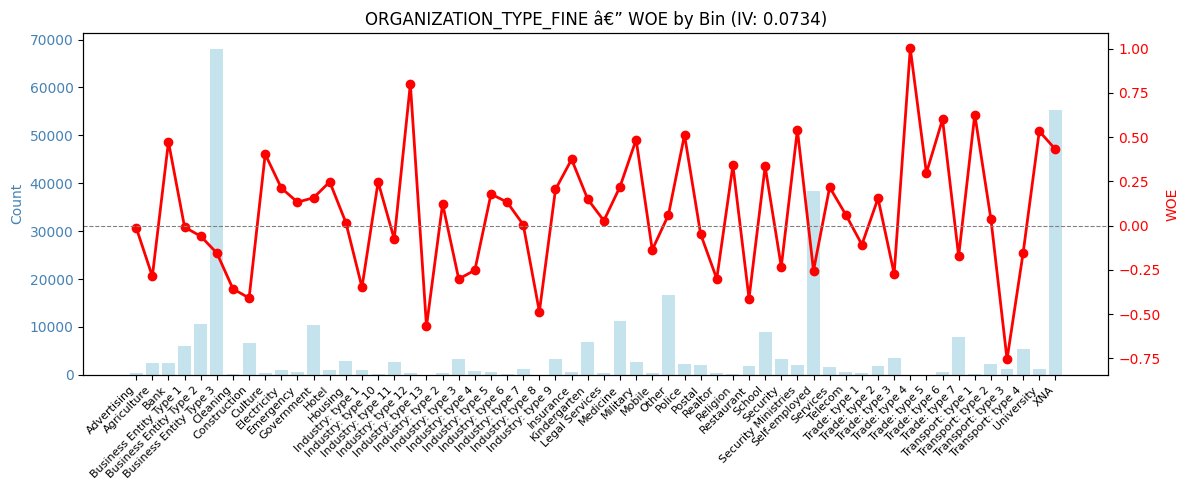

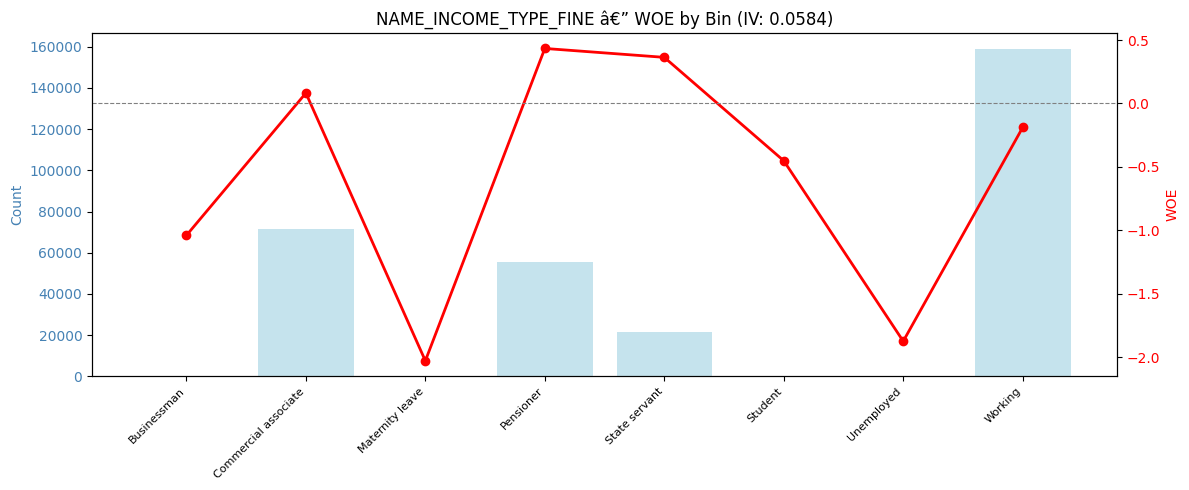

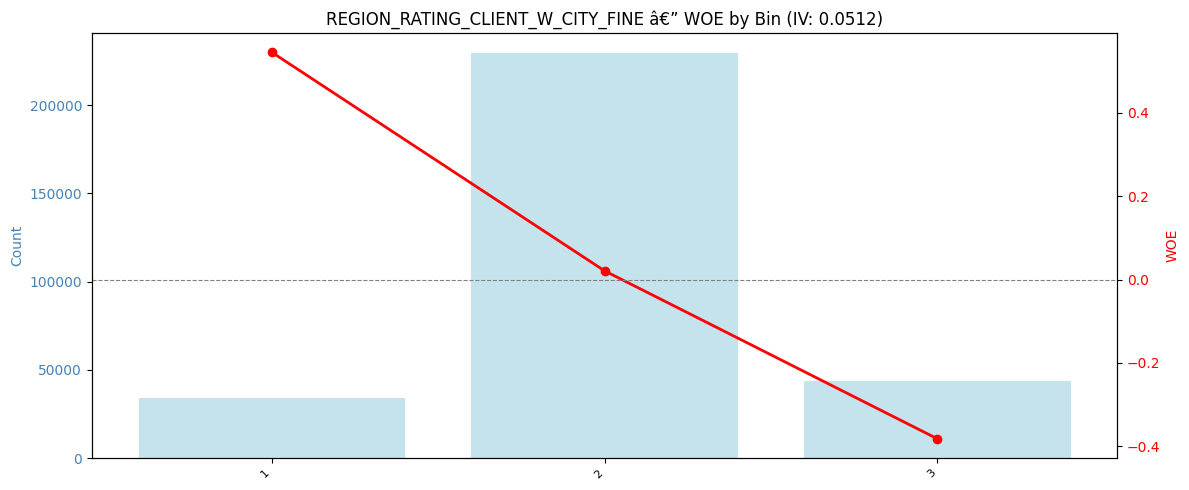

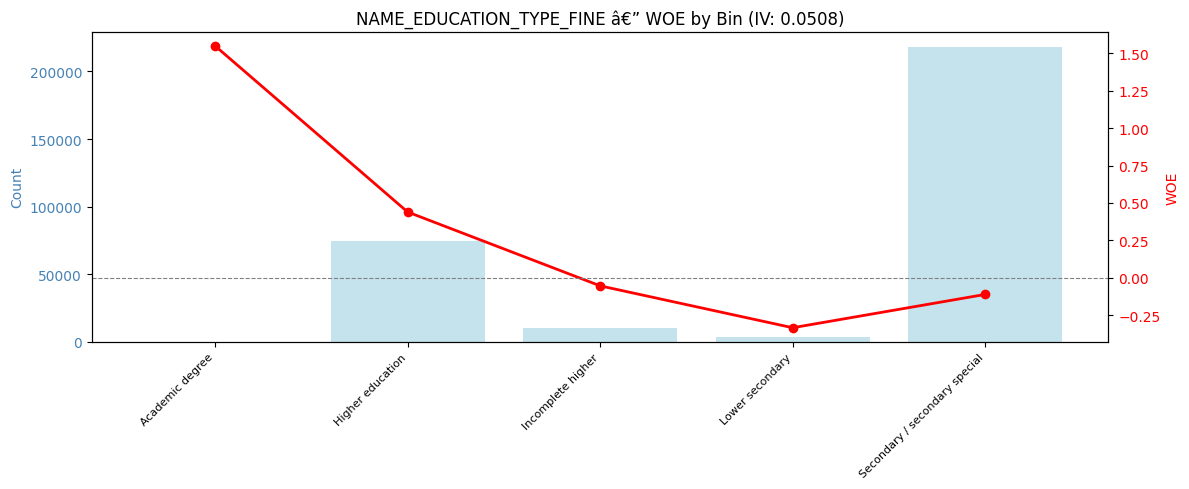

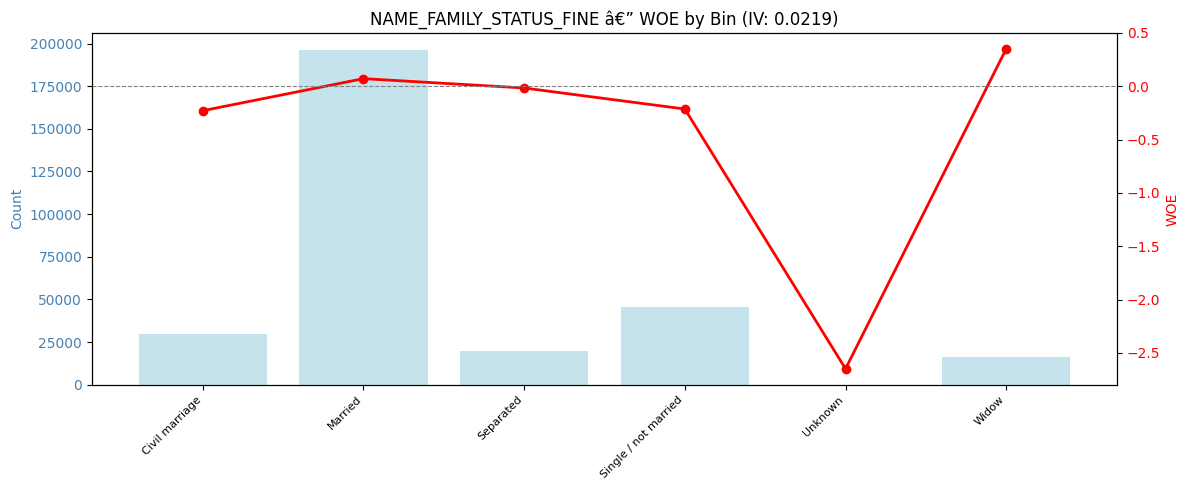

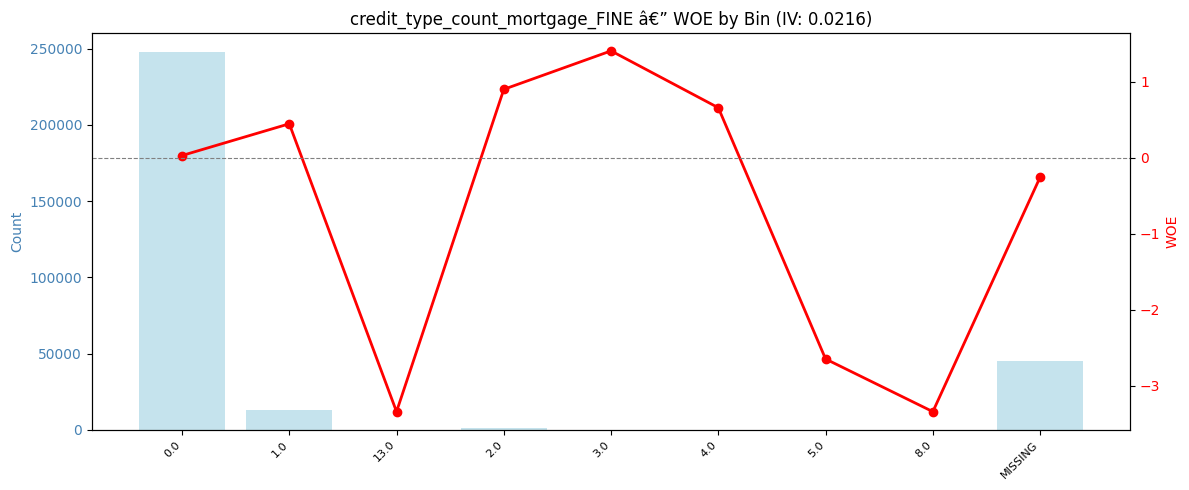

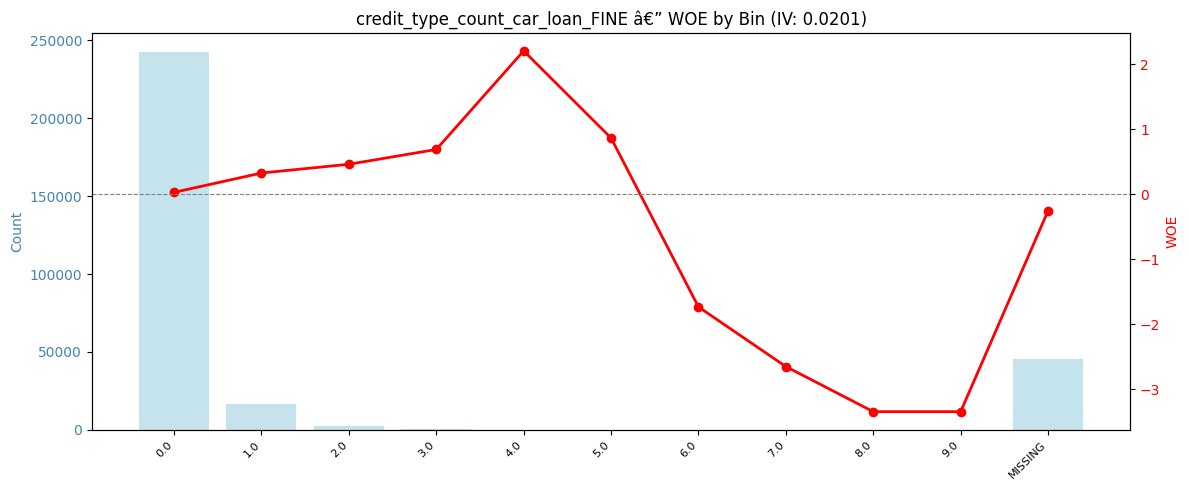

In [43]:

# =========================================================
# 1. FINE CLASS CATEGORICAL VARIABLES
# =========================================================
def fine_class_categorical(df, feature):
    fine_col = f'{feature}_FINE'
    df[fine_col] = df[feature].fillna('MISSING').astype(str)
    return df


categorical_features = merged_df_reduced.select_dtypes(include=['object', 'category']).columns.tolist()
categorical_features = categorical_features + pseudo_cat_cols
categorical_features = [
    c for c in categorical_features
    if c != 'TARGET' and not c.endswith('_FINE') and not c.endswith('_COARSE')
]

for col in categorical_features:
    merged_df_reduced = fine_class_categorical(merged_df_reduced, col)

fine_categorical_features = [f'{c}_FINE' for c in categorical_features]


# =========================================================
# 2. BIN SUMMARY
# =========================================================
def categorical_bin_summary(df, features, target_col='TARGET'):
    all_rows = []

    for feature in features:
        tmp = df[[feature, target_col]].copy()

        g = tmp.groupby(feature, dropna=False)[target_col].agg(['count', 'sum']).rename(
            columns={'count': 'Count', 'sum': 'Bad'}
        )
        g['Good'] = g['Count'] - g['Bad']
        g['Bad_Rate'] = g['Bad'] / g['Count']

        g = g.reset_index()
        g.columns = ['Bin', 'Count', 'Bad', 'Good', 'Bad_Rate']
        g['Variable'] = feature

        all_rows.append(g[['Variable', 'Bin', 'Count', 'Good', 'Bad', 'Bad_Rate']])

    out = pd.concat(all_rows, ignore_index=True)
    out = out.set_index(['Variable', 'Bin'])
    return out

cat_fine_fine_class_df = categorical_bin_summary(
    merged_df_reduced,
    fine_categorical_features,
    target_col='TARGET'
)

# =========================================================
# 3. IV CALCULATION
# =========================================================
def calc_iv_from_bins(fine_class_df):
    iv_summary = []

    for feature in fine_class_df.index.get_level_values(0).unique():
        feature_data = fine_class_df.loc[feature].copy()

        total_good = feature_data['Good'].sum()
        total_bad = feature_data['Bad'].sum()

        if total_good == 0 or total_bad == 0:
            continue

        feature_data['Dist_Good'] = (feature_data['Good'] / total_good).replace(0, 0.0001)
        feature_data['Dist_Bad'] = (feature_data['Bad'] / total_bad).replace(0, 0.0001)
        feature_data['WOE'] = np.log(feature_data['Dist_Good'] / feature_data['Dist_Bad'])
        feature_data['IV'] = (feature_data['Dist_Good'] - feature_data['Dist_Bad']) * feature_data['WOE']

        iv_summary.append({
            'Variable': feature,
            'IV': feature_data['IV'].sum()
        })

    return pd.DataFrame(iv_summary).sort_values('IV', ascending=False).reset_index(drop=True)

cat_fine_iv_table = calc_iv_from_bins(cat_fine_fine_class_df)
cat_fine_iv_table['IV'] = cat_fine_iv_table['IV'].round(4)
display(cat_fine_iv_table)

# =========================================================
# 4. PLOT WOE CHARTS
# =========================================================
def plot_woe_from_bins(fine_class_df):
    for feature in fine_class_df.index.get_level_values(0).unique():
        result = fine_class_df.loc[feature].copy()

        total_bad = result['Bad'].sum()
        total_good = result['Good'].sum()

        if total_bad == 0 or total_good == 0:
            continue

        result['Dist_Bad'] = (result['Bad'] / total_bad).replace(0, 0.0001)
        result['Dist_Good'] = (result['Good'] / total_good).replace(0, 0.0001)
        result['WOE'] = np.log(result['Dist_Good'] / result['Dist_Bad'])
        result['IV'] = (result['Dist_Good'] - result['Dist_Bad']) * result['WOE']

        fig, ax1 = plt.subplots(figsize=(12, 5))

        x = range(len(result))
        ax1.bar(x, result['Count'], color='lightblue', alpha=0.7)
        ax1.set_ylabel('Count', color='steelblue')
        ax1.tick_params(axis='y', labelcolor='steelblue')

        ax2 = ax1.twinx()
        ax2.plot(x, result['WOE'], color='red', marker='o', linewidth=2)
        ax2.axhline(y=0, color='grey', linestyle='--', linewidth=0.8)
        ax2.set_ylabel('WOE', color='red')
        ax2.tick_params(axis='y', labelcolor='red')

        ax1.set_xticks(list(x))
        ax1.set_xticklabels(result.index.astype(str), rotation=45, ha='right', fontsize=8)

        plt.title(f'{feature} â€” WOE by Bin (IV: {result["IV"].sum():.4f})')
        fig.tight_layout()
        plt.show()

# only keep fine-classed categorical variables with IV >= 0.02
selected_fine_categorical_features = cat_fine_iv_table[
    cat_fine_iv_table['IV'] >= 0.02
]['Variable'].tolist()

print("Fine-classed categorical variables with IV >= 0.02:")
print(selected_fine_categorical_features)

plot_woe_from_bins(cat_fine_fine_class_df.loc[selected_fine_categorical_features])


## COARSE CLASSING- Categorical

,Variable,Min_Bin_Pct,Min_5%_Rule
2,NAME_INCOME_TYPE_COARSE,0.000179,FAIL
4,ORGANIZATION_TYPE_COARSE,0.006419,FAIL
0,NAME_EDUCATION_TYPE_COARSE,0.243982,PASS
1,NAME_FAMILY_STATUS_COARSE,0.052323,PASS
3,OCCUPATION_TYPE_COARSE,0.274683,PASS


,Fine_Variable,Fine_IV,Coarse_Variable,Coarse_IV,Fine_IV_Range,Coarse_IV_Range,IV_Check,IV_0.02_Check
3,NAME_EDUCATION_TYPE_FINE,0.0508,NAME_EDUCATION_TYPE_COARSE,0.0497,0.02-0.10,0.02-0.10,PASS,PASS
4,NAME_FAMILY_STATUS_FINE,0.0219,NAME_FAMILY_STATUS_COARSE,0.0212,0.02-0.10,0.02-0.10,PASS,PASS
2,NAME_INCOME_TYPE_FINE,0.0584,NAME_INCOME_TYPE_COARSE,0.0459,0.02-0.10,0.02-0.10,PASS,PASS
0,OCCUPATION_TYPE_FINE,0.0829,OCCUPATION_TYPE_COARSE,0.0757,0.02-0.10,0.02-0.10,PASS,PASS
1,ORGANIZATION_TYPE_FINE,0.0734,ORGANIZATION_TYPE_COARSE,0.0474,0.02-0.10,0.02-0.10,PASS,PASS


,Variable,IV
0,OCCUPATION_TYPE_COARSE,0.0757
1,NAME_EDUCATION_TYPE_COARSE,0.0497
2,ORGANIZATION_TYPE_COARSE,0.0474
3,NAME_INCOME_TYPE_COARSE,0.0459
4,NAME_FAMILY_STATUS_COARSE,0.0212


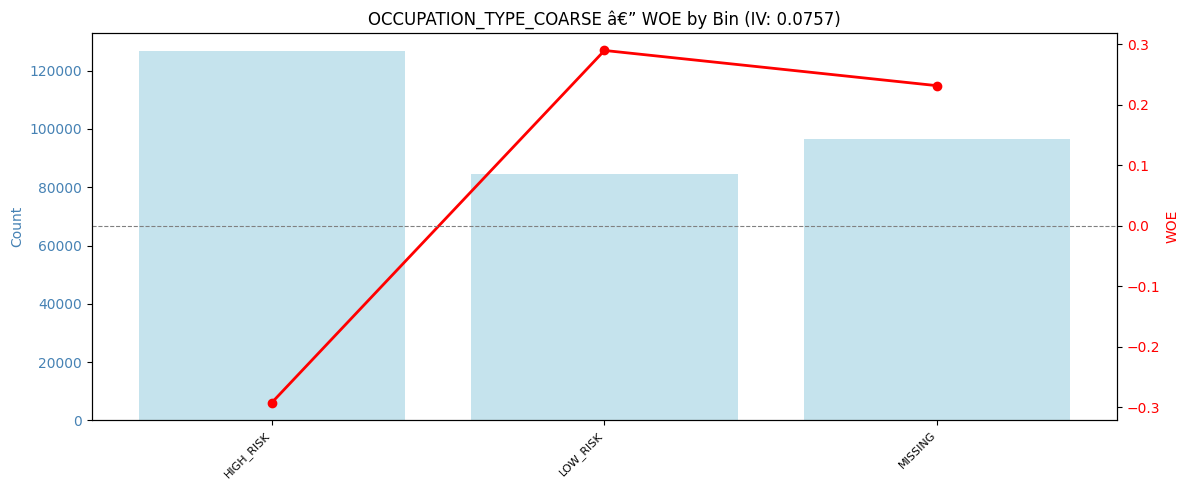

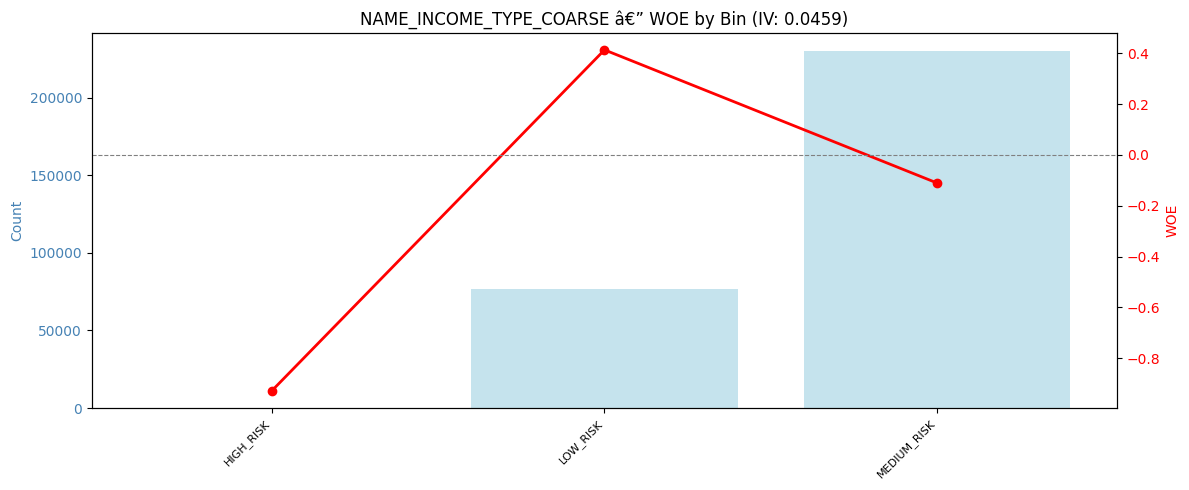

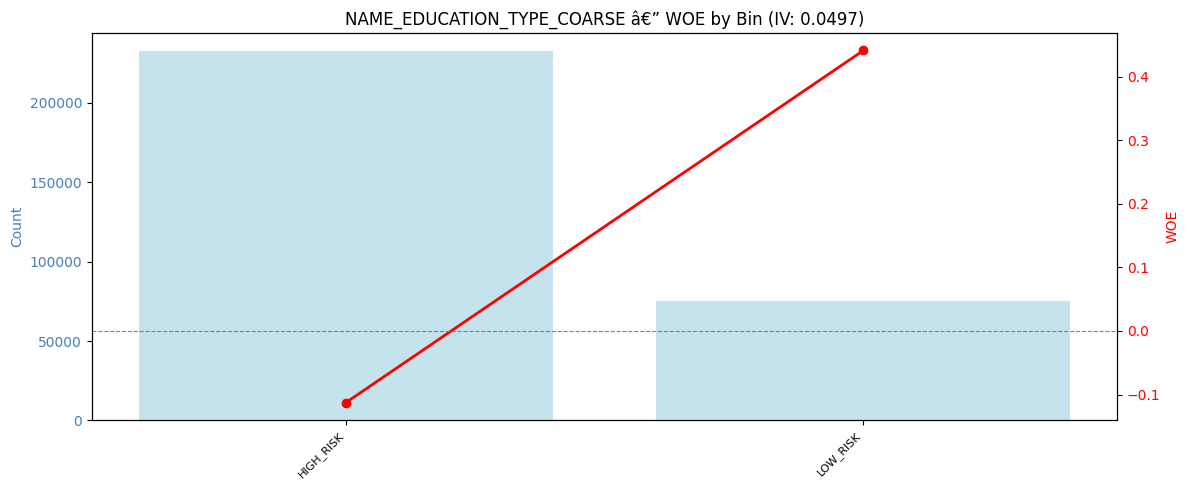

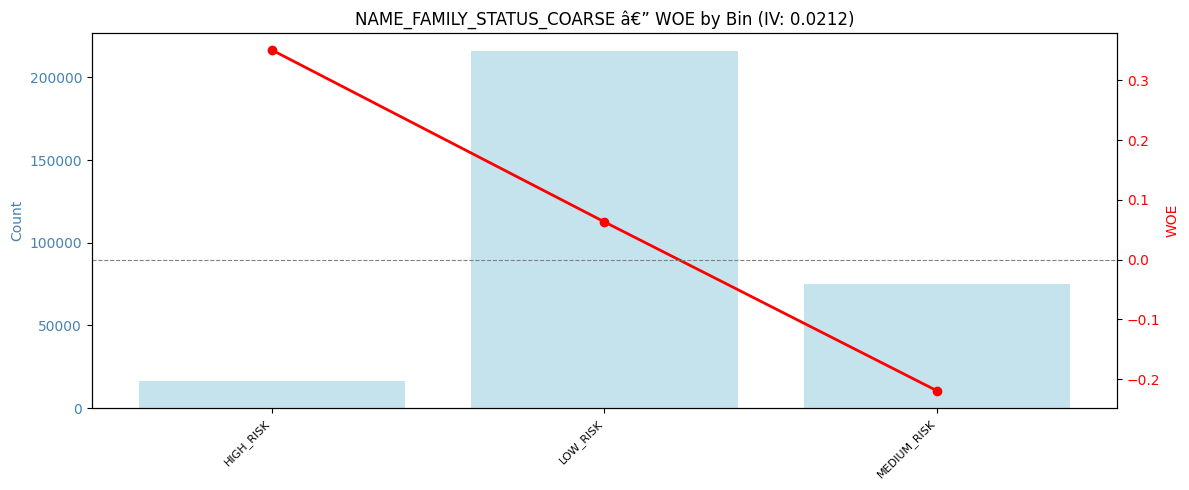

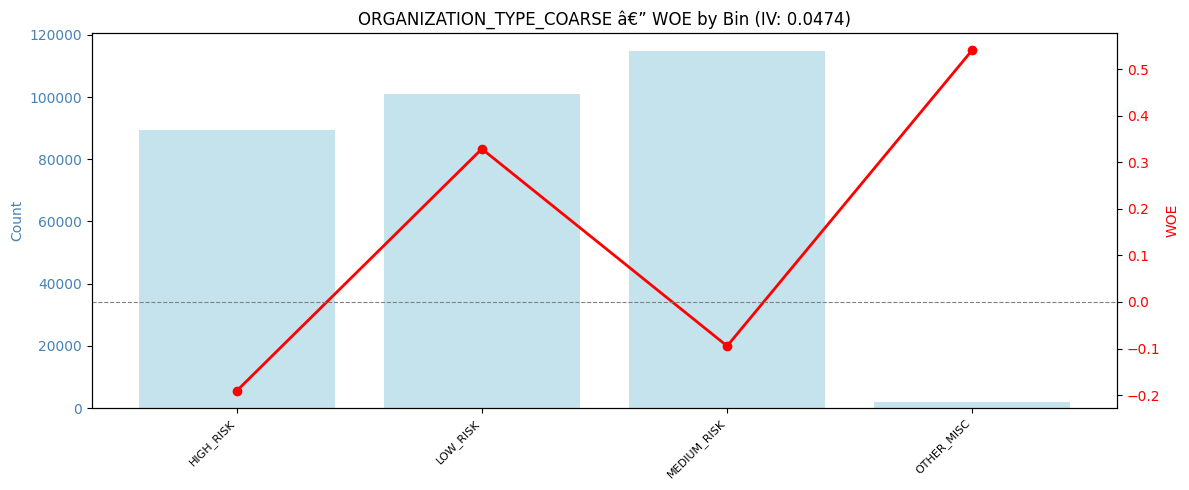

In [44]:
# =========================================================
# 1. MANUAL COARSE CLASSING RULES FOR CATEGORICAL VARIABLES
# =========================================================
categorical_coarse_rules = {
    'OCCUPATION_TYPE_FINE': {
        'Accountants': 'LOW_RISK',
        'Core staff': 'LOW_RISK',
        'HR staff': 'LOW_RISK',
        'High skill tech staff': 'LOW_RISK',
        'IT staff': 'LOW_RISK',
        'Managers': 'LOW_RISK',
        'Medicine staff': 'LOW_RISK',
        'Private service staff': 'LOW_RISK',
        'Realty agents': 'LOW_RISK',
        'Secretaries': 'LOW_RISK',

        'Cleaning staff': 'HIGH_RISK',
        'Cooking staff': 'HIGH_RISK',
        'Drivers': 'HIGH_RISK',
        'Laborers': 'HIGH_RISK',
        'Low-skill Laborers': 'HIGH_RISK',
        'Sales staff': 'HIGH_RISK',
        'Security staff': 'HIGH_RISK',
        'Waiters/barmen staff': 'HIGH_RISK',

        'MISSING': 'MISSING'
    },

    'NAME_INCOME_TYPE_FINE': {
        'Pensioner': 'LOW_RISK',
        'State servant': 'LOW_RISK',

        'Commercial associate': 'MEDIUM_RISK',
        'Working': 'MEDIUM_RISK',

        'Businessman': 'HIGH_RISK',
        'Maternity leave': 'HIGH_RISK',
        'Student': 'HIGH_RISK',
        'Unemployed': 'HIGH_RISK',
        'MISSING': 'HIGH_RISK'
    },

    'NAME_EDUCATION_TYPE_FINE': {
        'Academic degree': 'LOW_RISK',
        'Higher education': 'LOW_RISK',

        'Incomplete higher': 'HIGH_RISK',
        'Lower secondary': 'HIGH_RISK',
        'Secondary / secondary special': 'HIGH_RISK',
        'MISSING': 'HIGH_RISK'
    },

    'NAME_FAMILY_STATUS_FINE': {
        'Married': 'LOW_RISK',
        'Separated': 'LOW_RISK',

        'Civil marriage': 'MEDIUM_RISK',
        'Single / not married': 'MEDIUM_RISK',

        'Widow': 'HIGH_RISK',
        'Unknown': 'HIGH_RISK',
        'MISSING': 'HIGH_RISK'
    },

    'ORGANIZATION_TYPE_FINE': {
        'Bank': 'LOW_RISK',
        'Emergency': 'LOW_RISK',
        'Government': 'LOW_RISK',
        'Insurance': 'LOW_RISK',
        'Kindergarten': 'LOW_RISK',
        'Legal Services': 'LOW_RISK',
        'Medicine': 'LOW_RISK',
        'Mobile': 'LOW_RISK',
        'Postal': 'LOW_RISK',
        'School': 'LOW_RISK',
        'Telecom': 'LOW_RISK',
        'University': 'LOW_RISK',
        'XNA': 'LOW_RISK',

        'Advertising': 'MEDIUM_RISK',
        'Agriculture': 'MEDIUM_RISK',
        'Business Entity Type 1': 'MEDIUM_RISK',
        'Business Entity Type 2': 'MEDIUM_RISK',
        'Culture': 'MEDIUM_RISK',
        'Hotel': 'MEDIUM_RISK',
        'Housing': 'MEDIUM_RISK',
        'Industry: type 1': 'MEDIUM_RISK',
        'Industry: type 4': 'MEDIUM_RISK',
        'Industry: type 5': 'MEDIUM_RISK',
        'Industry: type 6': 'MEDIUM_RISK',
        'Industry: type 7': 'MEDIUM_RISK',
        'Industry: type 9': 'MEDIUM_RISK',
        'Military': 'MEDIUM_RISK',
        'Other': 'MEDIUM_RISK',
        'Police': 'MEDIUM_RISK',
        'Realtor': 'MEDIUM_RISK',
        'Religion': 'MEDIUM_RISK',
        'Self-employed': 'MEDIUM_RISK',
        'Services': 'MEDIUM_RISK',
        'Trade: type 2': 'MEDIUM_RISK',
        'Trade: type 3': 'MEDIUM_RISK',
        'Trade: type 4': 'MEDIUM_RISK',
        'Trade: type 5': 'MEDIUM_RISK',
        'Trade: type 6': 'MEDIUM_RISK',
        'Trade: type 7': 'MEDIUM_RISK',
        'Transport: type 1': 'MEDIUM_RISK',
        'Transport: type 2': 'MEDIUM_RISK',
        'Transport: type 4': 'MEDIUM_RISK',

        'Business Entity Type 3': 'HIGH_RISK',
        'Cleaning': 'HIGH_RISK',
        'Construction': 'HIGH_RISK',
        'Electricity': 'HIGH_RISK',
        'Industry: type 2': 'HIGH_RISK',
        'Industry: type 3': 'HIGH_RISK',
        'Industry: type 8': 'HIGH_RISK',
        'Industry: type 10': 'HIGH_RISK',
        'Industry: type 11': 'HIGH_RISK',
        'Industry: type 12': 'HIGH_RISK',
        'Industry: type 13': 'HIGH_RISK',
        'Restaurant': 'HIGH_RISK',
        'Security': 'HIGH_RISK',
        'Trade: type 1': 'HIGH_RISK',
        'Transport: type 3': 'HIGH_RISK',
        'MISSING': 'HIGH_RISK'
    }
}

# =========================================================
# 2. APPLY COARSE CLASSING
# Applies the mapping dictionary to replace category names with risk labels. Any category not explicitly listed is labelled OTHER_MISC.
# =========================================================
def apply_coarse_classing(df, fine_feature, mapping):
    coarse_col = fine_feature.replace('_FINE', '_COARSE')
    df[coarse_col] = df[fine_feature].map(mapping).fillna('OTHER_MISC')
    return df

selected_categorical_coarse_rules = {
    k: v for k, v in categorical_coarse_rules.items()
    if k in selected_fine_categorical_features
}

for fine_feature, mapping in selected_categorical_coarse_rules.items():
    merged_df_reduced = apply_coarse_classing(merged_df_reduced, fine_feature, mapping)

coarse_categorical_features = [
    f.replace('_FINE', '_COARSE')
    for f in selected_categorical_coarse_rules.keys()
]

# =========================================================
# 3. BUILD COARSE SUMMARY
# =========================================================
cat_coarse_fine_class_df = categorical_bin_summary(
    merged_df_reduced,
    coarse_categorical_features,
    target_col='TARGET'
)

cat_coarse_iv_table = calc_iv_from_bins(cat_coarse_fine_class_df)
cat_coarse_iv_table['IV'] = cat_coarse_iv_table['IV'].round(4)

# =========================================================
# 4. IV RANGE CHECK
# =========================================================
selected_fine_iv_table = cat_fine_iv_table[
    cat_fine_iv_table['Variable'].isin(selected_fine_categorical_features)
].copy()

selected_fine_iv_table['Coarse_Variable'] = selected_fine_iv_table['Variable'].str.replace('_FINE', '_COARSE', regex=False)
selected_fine_iv_table = selected_fine_iv_table.rename(columns={'Variable': 'Fine_Variable'})

coarse_compare_input = cat_coarse_iv_table.copy()
coarse_compare_input['Fine_Variable'] = coarse_compare_input['Variable'].str.replace('_COARSE', '_FINE', regex=False)

cat_iv_comparison = selected_fine_iv_table[['Fine_Variable', 'IV']].rename(columns={'IV': 'Fine_IV'}).merge(
    coarse_compare_input[['Fine_Variable', 'Variable', 'IV']].rename(columns={'Variable': 'Coarse_Variable', 'IV': 'Coarse_IV'}),
    on='Fine_Variable',
    how='inner'
)

def iv_range(iv):
    if 0.30 <= iv <= 0.50:
        return '0.30-0.50'
    elif 0.10 <= iv < 0.30:
        return '0.10-0.30'
    elif 0.02 <= iv < 0.10:
        return '0.02-0.10'
    else:
        return 'OUT_OF_RANGE'

cat_iv_comparison['Fine_IV_Range'] = cat_iv_comparison['Fine_IV'].apply(iv_range)
cat_iv_comparison['Coarse_IV_Range'] = cat_iv_comparison['Coarse_IV'].apply(iv_range)
cat_iv_comparison['IV_Check'] = np.where(
    cat_iv_comparison['Fine_IV_Range'] == cat_iv_comparison['Coarse_IV_Range'],
    'PASS',
    'FAIL'
)
cat_iv_comparison['IV_0.02_Check'] = np.where(cat_iv_comparison['Coarse_IV'] >= 0.02, 'PASS', 'FAIL')

# =========================================================
# 5. BIN SIZE CHECK
# =========================================================
def check_categorical_bin_size(fine_class_df, total_n):
    rows = []

    for feature in fine_class_df.index.get_level_values(0).unique():
        d = fine_class_df.loc[feature].copy().reset_index()
        d['Obs_%'] = d['Count'] / total_n
        d['Min_5%_Rule'] = np.where(d['Obs_%'] >= 0.05, 'PASS', 'FAIL')
        d['Variable'] = feature
        rows.append(d[['Variable', 'Bin', 'Count', 'Obs_%', 'Min_5%_Rule']])

    return pd.concat(rows, ignore_index=True).sort_values(['Min_5%_Rule', 'Variable', 'Obs_%'])

cat_coarse_bin_check = check_categorical_bin_size(cat_coarse_fine_class_df, len(merged_df_reduced))

cat_coarse_min_check = (
    cat_coarse_bin_check.groupby('Variable', as_index=False)
    .agg(Min_Bin_Pct=('Obs_%', 'min'))
)
cat_coarse_min_check['Min_5%_Rule'] = np.where(cat_coarse_min_check['Min_Bin_Pct'] >= 0.05, 'PASS', 'FAIL')

# =========================================================
# 6. DISPLAY RESULTS
# =========================================================
display(cat_coarse_min_check.sort_values(['Min_5%_Rule', 'Variable']))
display(cat_iv_comparison.sort_values(['IV_Check', 'IV_0.02_Check', 'Fine_Variable']))
display(cat_coarse_iv_table.sort_values('IV', ascending=False))

# =========================================================
# 7. PLOT COARSE WOE CHARTS
# =========================================================
plot_woe_from_bins(cat_coarse_fine_class_df)


# SCORECARD

In [45]:
import scorecardpy as sc
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
import pprint

C:\Users\teoji\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scorecardpy\germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## Feature Selection

In [46]:

# Keep only numeric coarse variables with IV > 0.05
selected_numeric_coarse_features = coarse_iv_table.loc[
    (coarse_iv_table['IV'] > 0.05) &
    (~coarse_iv_table['Variable'].isin(['AMT_GOODS_PRICE', 'credit_type_count_credit_card'])), #Manually excludes two specific variables even if their IV is good enough
    'Variable'
].tolist()

# Keep only categorical coarse variables with IV > 0.05
selected_categorical_coarse_features = cat_coarse_iv_table.loc[
    cat_coarse_iv_table['IV'] > 0.05,
    'Variable'
].tolist()

scorecard_data = merged_df_reduced[
    selected_numeric_coarse_features + selected_categorical_coarse_features + ['TARGET']
].copy()

display(scorecard_data.head())

display(scorecard_data.shape)
display(scorecard_data.columns)


,EXT_SOURCE_1,days_credit_avg,YEARS_EMPLOYED,credit_utilisation,active_loan_ratio,AGE_YEARS,REGION_RATING_CLIENT_W_CITY,OCCUPATION_TYPE_COARSE,TARGET
0,0.083037,-874.00,1.745205,0.284122,0.25,26,2,HIGH_RISK,1
1,0.311267,-1400.75,3.254795,0.000000,0.25,46,1,LOW_RISK,0
2,NaN,-867.00,0.616438,0.000000,0.00,52,2,HIGH_RISK,0
3,NaN,NaN,8.326027,NaN,NaN,52,2,HIGH_RISK,0
4,NaN,-1149.00,8.323288,0.000000,0.00,55,2,LOW_RISK,0


(307511, 9)

Index(['EXT_SOURCE_1', 'days_credit_avg', 'YEARS_EMPLOYED',
       'credit_utilisation', 'active_loan_ratio', 'AGE_YEARS',
       'REGION_RATING_CLIENT_W_CITY', 'OCCUPATION_TYPE_COARSE', 'TARGET'],
      dtype='object')

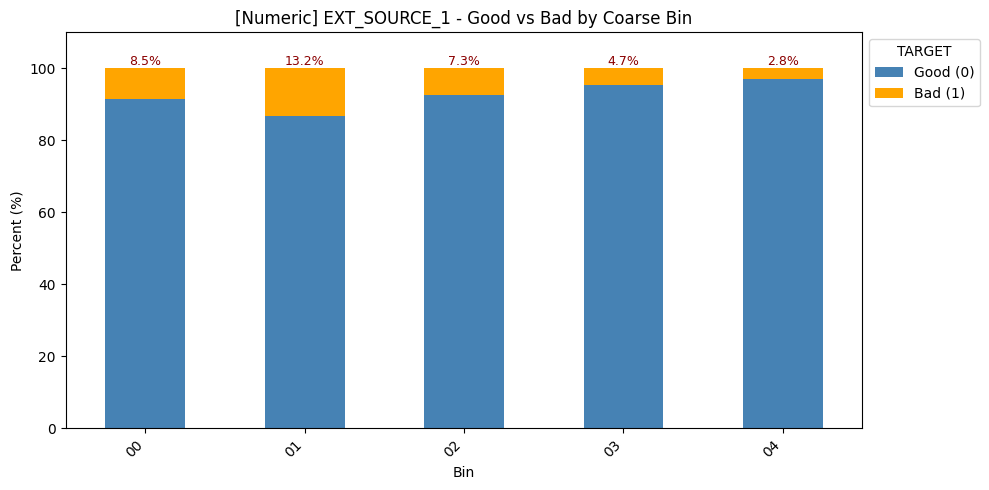

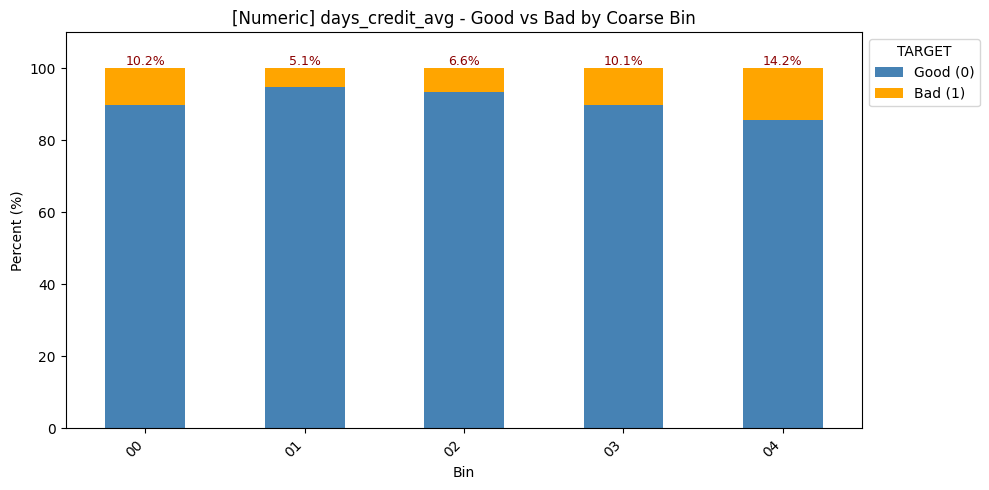

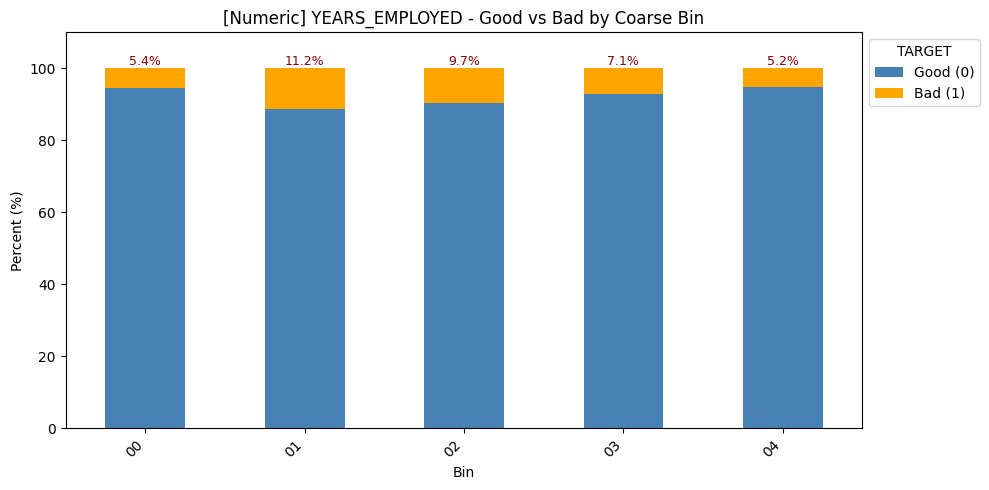

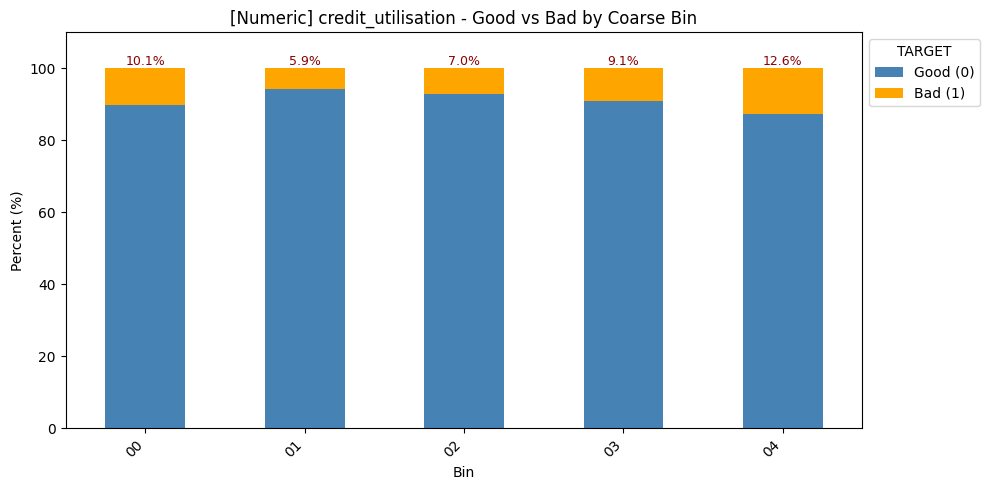

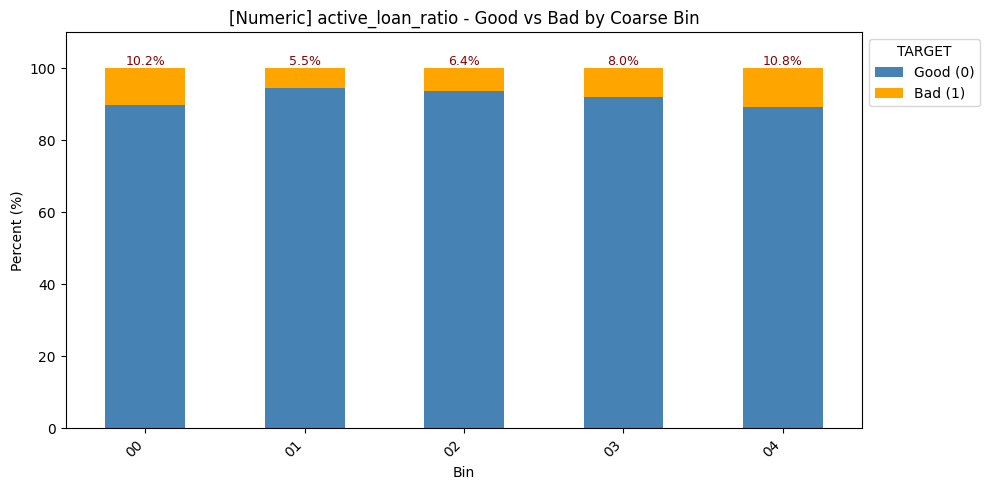

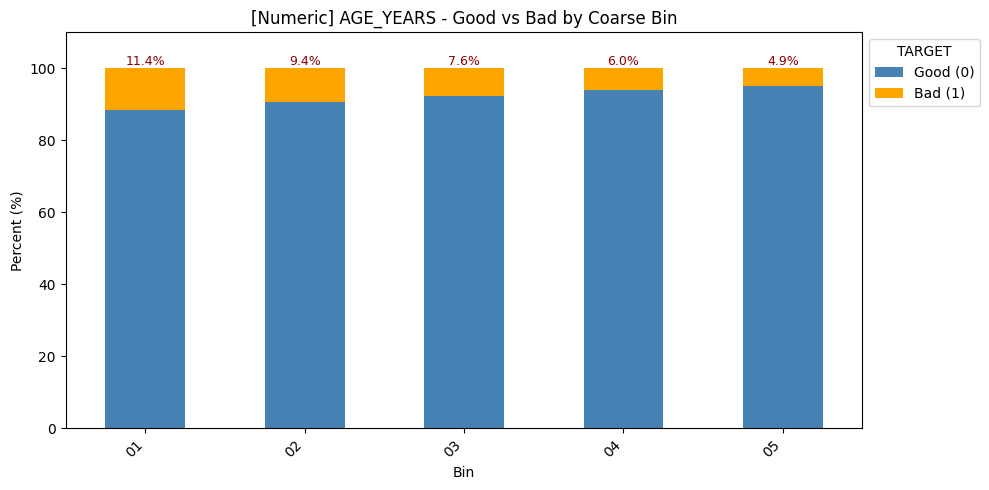

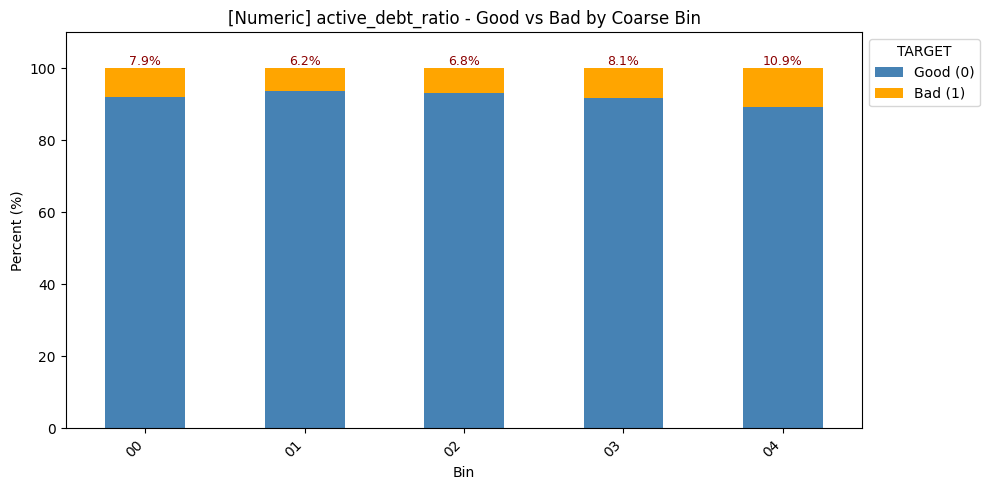

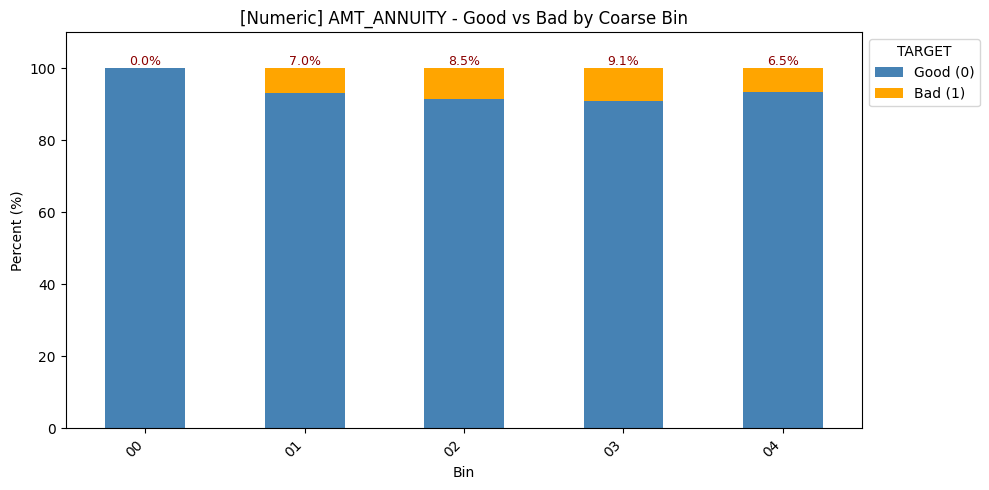

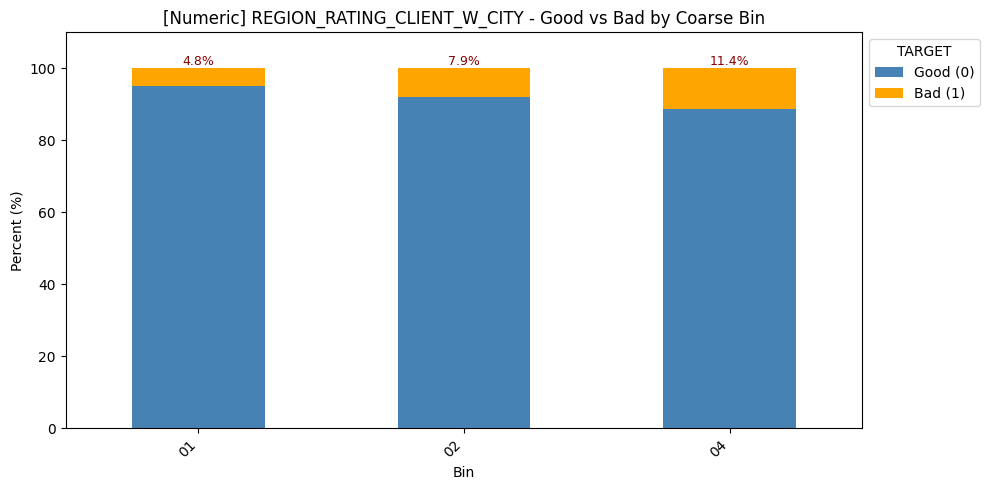

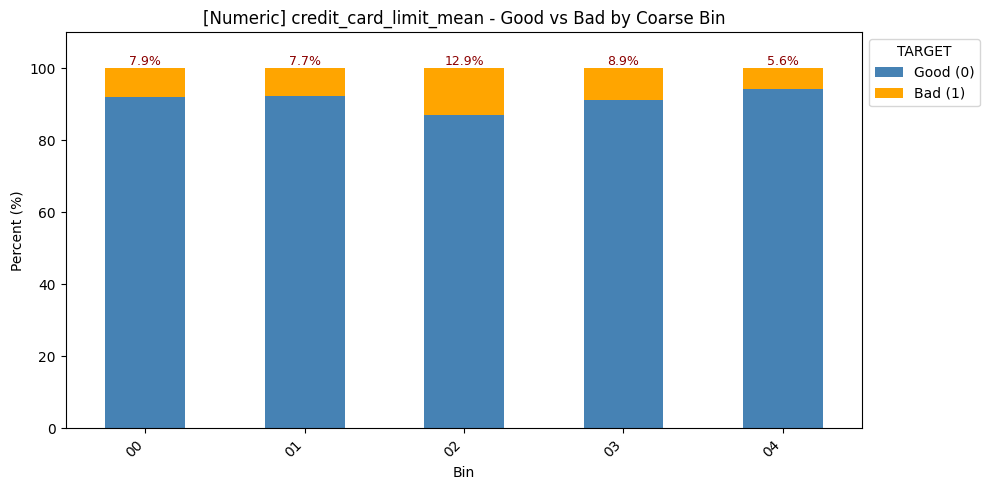

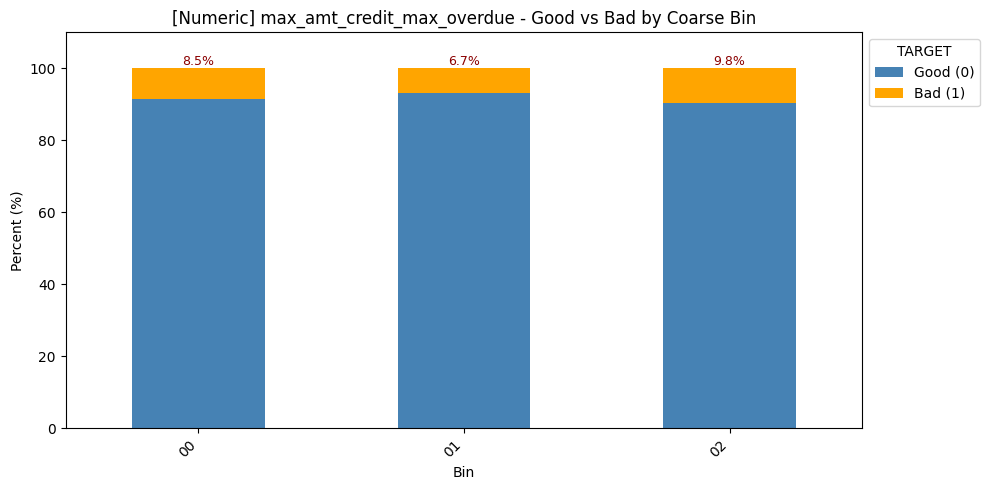

In [47]:
# === STACKED BAR CHARTS: Coarse-classed variables (Good vs Bad per bin) ===
def plot_coarse_stacked(coarse_df, title_prefix=''):
    """
    Plot 100% stacked bar charts for each variable after coarse classing.
    Each bar = one bin; segments show Good vs Bad proportion.
    Expects a multi-index df with ('Variable', 'Bin') and columns ['Good', 'Bad'].
    """
    for feature in coarse_df.index.get_level_values(0).unique():
        stk_result = coarse_df.loc[feature][['Good', 'Bad']].copy()

        # Move Missing bin to the end if present
        if 'Missing' in stk_result.index:
            stk_result = pd.concat([
                stk_result[stk_result.index != 'Missing'],
                stk_result.loc[['Missing']]
            ])
        if 'MISSING' in stk_result.index:
            stk_result = pd.concat([
                stk_result[stk_result.index != 'MISSING'],
                stk_result.loc[['MISSING']]
            ])

        # Normalize each bin to 100%
        stk_pct = stk_result.div(stk_result.sum(axis=1), axis=0) * 100

        fig, ax = plt.subplots(figsize=(10, 5))
        stk_pct.plot(kind='bar', stacked=True, ax=ax,
                     color=['steelblue', 'orange'])

        # Annotate bad rate on each bar
        for idx, (_, row) in enumerate(stk_pct.iterrows()):
            ax.text(idx, 101, f"{row['Bad']:.1f}%",
                    ha='center', fontsize=9, color='darkred')

        ax.set_title(f'{title_prefix}{feature} - Good vs Bad by Coarse Bin')
        ax.set_ylabel('Percent (%)')
        ax.set_xlabel('Bin')
        ax.set_ylim(0, 110)
        ax.legend(title='TARGET', labels=['Good (0)', 'Bad (1)'],
                  bbox_to_anchor=(1.0, 1.0))
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()


# Run on numeric coarse-classed variables
plot_coarse_stacked(coarse_fine_class_df, title_prefix='[Numeric] ')
plot_coarse_stacked(cat_coarse_fine_class_df, title_prefix='[Categorical] ')

## Train/ Test Split

In [48]:
# Use coarse numerical + coarse categorical features, rename TARGET -> BAD

scorecard_data = scorecard_data.rename(columns={'TARGET': 'BAD'})

data_split = sc.split_df(scorecard_data, y='BAD', ratio=0.7, seed=50)
train = data_split['train']
test  = data_split['test']

print(f'Train: {train.shape}, Test: {test.shape}')
print(f'Train bad rate: {train["BAD"].mean():.3f}')
print(f'Test  bad rate: {test["BAD"].mean():.3f}')


Train: (215258, 9), Test: (92253, 9)
Train bad rate: 0.081
Test  bad rate: 0.081


## WOE Binning

In [49]:
# Pass our manual breakpoints for numerics; scorecardpy handles categoricals automatically
bins = sc.woebin(train, y='BAD', breaks_list=manual_bins)

woe_train = sc.woebin_ply(train, bins)
woe_test  = sc.woebin_ply(test,  bins)

[INFO] creating woe binning ...


C:\Users\teoji\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scorecardpy\condition_fun.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
C:\Users\teoji\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scorecardpy\woebin.py:141: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  ).groupby(['variable', 'rowid', 'bin_chr'], group_keys=False).agg({'bad':sum,'goo

Binning on 215258 rows and 9 columns in 00:00:16
[INFO] converting into woe values ...
Woe transformating on 215258 rows and 8 columns in 00:00:10
[INFO] converting into woe values ...


## Logistic Regression

In [50]:
x_train = woe_train.drop(columns='BAD')
y_train = woe_train['BAD']

lr = LogisticRegression(solver='liblinear', class_weight='balanced')
lr.fit(x_train, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

## Build Scorecard

In [51]:
# Base score 600 at odds 1:19, doubles odds every 20 points
scorecard_card = sc.scorecard(
    bins,
    lr,
    x_train.columns,
    points0=700,
    odds0=1/19,
    pdo=40,
    basepoints_eq0=True
)
pprint.pprint(scorecard_card)


{'AGE_YEARS':      variable          bin  points
18  AGE_YEARS  [-inf,30.0)    64.0
19  AGE_YEARS  [30.0,40.0)    65.0
20  AGE_YEARS  [40.0,50.0)    67.0
21  AGE_YEARS  [50.0,60.0)    68.0
22  AGE_YEARS   [60.0,inf)    70.0,
 'EXT_SOURCE_1':        variable          bin  points
0  EXT_SOURCE_1      missing    64.0
1  EXT_SOURCE_1  [-inf,0.35)    44.0
2  EXT_SOURCE_1  [0.35,0.55)    71.0
3  EXT_SOURCE_1  [0.55,0.75)    92.0
4  EXT_SOURCE_1   [0.75,inf)   112.0,
 'OCCUPATION_TYPE_COARSE':                   variable        bin  points
23  OCCUPATION_TYPE_COARSE   LOW_RISK    77.0
24  OCCUPATION_TYPE_COARSE    MISSING    74.0
25  OCCUPATION_TYPE_COARSE  HIGH_RISK    56.0,
 'REGION_RATING_CLIENT_W_CITY':                        variable         bin  points
10  REGION_RATING_CLIENT_W_CITY  [-inf,1.5)    96.0
11  REGION_RATING_CLIENT_W_CITY   [1.5,2.5)    68.0
12  REGION_RATING_CLIENT_W_CITY   [2.5,inf)    45.0,
 'YEARS_EMPLOYED':           variable         bin  points
31  YEARS_EMPLOYED     m

## Score Applicants

In [52]:
# Applies the scorecard to produce a numerical score for every applicant in train and test sets.

train_score = sc.scorecard_ply(train, scorecard_card)
test_score  = sc.scorecard_ply(test,  scorecard_card)

print('Train score summary:')
print(train_score['score'].describe().round(1))
print()
print('Test score summary:')
print(test_score['score'].describe().round(1))

Train score summary:
count    215258.0
mean        540.3
std          36.9
min         428.0
25%         514.0
50%         540.0
75%         566.0
max         666.0
Name: score, dtype: float64

Test score summary:
count    92253.0
mean       540.1
std         36.9
min        428.0
25%        514.0
50%        540.0
75%        566.0
max        666.0
Name: score, dtype: float64


## KS & ROC-AUC
**KS (Kolmogorov-Smirnov)**: maximum separation between the cumulative good and bad distributions. Higher = better discrimination. <br>
**AUC (Area Under ROC Curve)**: probability that a randomly chosen bad applicant scores lower than a randomly chosen good one. Range 0.5 (random) to 1.0 (perfect).

/opt/miniconda3/envs/is453_env/lib/python3.11/site-packages/scorecardpy/perf.py:266: UserWarning: Since the average of pred is not in [0,1], it is treated as predicted score but not probability.
  warnings.warn('Since the average of pred is not in [0,1], it is treated as predicted score but not probability.')


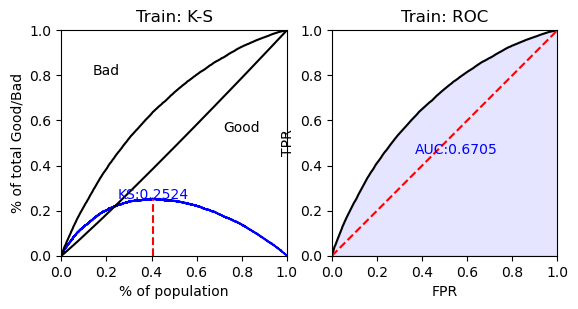

/opt/miniconda3/envs/is453_env/lib/python3.11/site-packages/scorecardpy/perf.py:266: UserWarning: Since the average of pred is not in [0,1], it is treated as predicted score but not probability.
  warnings.warn('Since the average of pred is not in [0,1], it is treated as predicted score but not probability.')


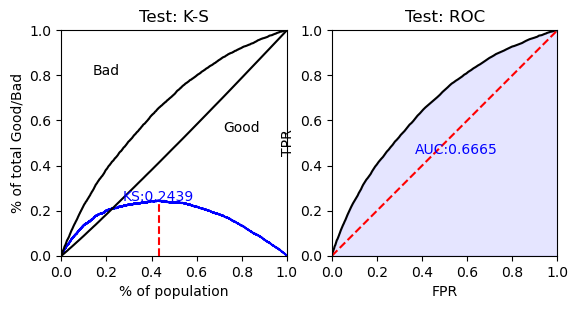

In [42]:
# scorecardpy built-in: KS, AUC, ROC curve - standard credit scorecard metrics
y_test = woe_test['BAD']

train_perf = sc.perf_eva(y_train, train_score['score'], title='Train')
test_perf  = sc.perf_eva(y_test,  test_score['score'],  title='Test')

## Confusion Matrix & Classification Report at Cutoff

In [43]:
cutoff = 500  # score below cutoff => predicted bad (default)

predicted_train_bad = (train_score['score'] < cutoff).astype(int).tolist()
predicted_test_bad  = (test_score['score']  < cutoff).astype(int).tolist()

print('=== TRAIN ===')
print(metrics.confusion_matrix(y_train, predicted_train_bad))
print(metrics.classification_report(y_train, predicted_train_bad))

print('=== TEST ===')
print(metrics.confusion_matrix(y_test, predicted_test_bad))
print(metrics.classification_report(y_test, predicted_test_bad))

=== TRAIN ===
[[171806  26074]
 [ 12196   5182]]
              precision    recall  f1-score   support

           0       0.93      0.87      0.90    197880
           1       0.17      0.30      0.21     17378

    accuracy                           0.82    215258
   macro avg       0.55      0.58      0.56    215258
weighted avg       0.87      0.82      0.84    215258

=== TEST ===
[[73520 11286]
 [ 5181  2266]]
              precision    recall  f1-score   support

           0       0.93      0.87      0.90     84806
           1       0.17      0.30      0.22      7447

    accuracy                           0.82     92253
   macro avg       0.55      0.59      0.56     92253
weighted avg       0.87      0.82      0.84     92253



## Net profit for fixed cutoff- 500

In [44]:
# Defines the financial parameters
wedding_loan_amt = 50000 # Fixed assumed wedding loan amount (SGD) — dataset loan amounts are not representative of wedding loans
profit_pct = 0.05   # 5% interest income on loan
loss_pct   = 0.85   # 85% of loan lost on default

In [45]:
def calc_net_profit(score_df, predicted_bad, actual_target, label=''):
    score_df = score_df.copy()
    score_df['predicted_bad'] = predicted_bad
    score_df['actual_target'] = actual_target
    
    # Approved = predicted Good (score >= cutoff)
    approved = score_df[score_df['predicted_bad'] == 0]
    n_approved = len(approved)
    n_rejected = len(score_df) - n_approved
    
    # Among approved — how many actually defaulted
    n_actual_defaults = approved['actual_target'].sum()
    n_actual_good     = n_approved - n_actual_defaults
    
    # Profit from good payers
    profit_from_good = n_actual_good * profit_pct * wedding_loan_amt
    
    # Loss from actual defaults among approved
    loss_from_default = n_actual_defaults * loss_pct * wedding_loan_amt
    
    # Net profit
    net_profit = profit_from_good - loss_from_default
    
    # Per applicant metrics
    avg_profit  = profit_pct * wedding_loan_amt          # per good payer
    avg_loss    = loss_pct   * wedding_loan_amt          # per defaulter
    
    print(f'=== {label} ===')
    print(f'Total Applicants       : {len(score_df):,}')
    print(f'Approved (score≥{cutoff}) : {n_approved:,}  ({n_approved/len(score_df):.1%})')
    print(f'Rejected (score<{cutoff}) : {n_rejected:,}  ({n_rejected/len(score_df):.1%})')
    print()
    print(f'Actual Good (approved) : {n_actual_good:,}')
    print(f'Actual Bad  (approved) : {n_actual_defaults:,}')
    print(f'Default Rate (approved): {n_actual_defaults/n_approved:.2%}')
    print()
    print(f'Avg Profit per Good    : SGD {avg_profit:,.0f}')
    print(f'Avg Loss per Default   : SGD {avg_loss:,.0f}')
    print()
    print(f'Total Profit (good)    : SGD {profit_from_good:,.0f}')
    print(f'Total Loss (defaults)  : SGD {loss_from_default:,.0f}')
    print(f'Net Profit             : SGD {net_profit:,.0f}')
    print()
    return net_profit

# Run for train and test
net_train = calc_net_profit(
    train_score, 
    predicted_train_bad, 
    train['BAD'].tolist(), 
    label='TRAIN'
)

net_test = calc_net_profit(
    test_score, 
    predicted_test_bad, 
    test['BAD'].tolist(), 
    label='TEST'
)

=== TRAIN ===
Total Applicants       : 215,258
Approved (score≥500) : 184,002  (85.5%)
Rejected (score<500) : 31,256  (14.5%)

Actual Good (approved) : 171,806
Actual Bad  (approved) : 12,196
Default Rate (approved): 6.63%

Avg Profit per Good    : SGD 2,500
Avg Loss per Default   : SGD 42,500

Total Profit (good)    : SGD 429,515,000
Total Loss (defaults)  : SGD 518,330,000
Net Profit             : SGD -88,815,000

=== TEST ===
Total Applicants       : 92,253
Approved (score≥500) : 78,701  (85.3%)
Rejected (score<500) : 13,552  (14.7%)

Actual Good (approved) : 73,520
Actual Bad  (approved) : 5,181
Default Rate (approved): 6.58%

Avg Profit per Good    : SGD 2,500
Avg Loss per Default   : SGD 42,500

Total Profit (good)    : SGD 183,800,000
Total Loss (defaults)  : SGD 220,192,500
Net Profit             : SGD -36,392,500



## Finding Optimal Cut Off

In [64]:
import matplotlib.pyplot as plt
import numpy as np

cutoffs = range(400, 651, 5)  # test cutoffs from 400 to 650

results = []

for cutoff in cutoffs:
    predicted_train_bad = (train_score['score'] < cutoff).astype(int).tolist()
    predicted_test_bad  = (test_score['score']  < cutoff).astype(int).tolist()
    
    for label, score_df, predicted_bad, actual in [
        ('TRAIN', train_score, predicted_train_bad, train['BAD'].tolist()),
        ('TEST',  test_score,  predicted_test_bad,  test['BAD'].tolist())
    ]:
        score_df = score_df.copy()
        score_df['predicted_bad'] = predicted_bad
        score_df['actual']        = actual
        
        approved = score_df[score_df['predicted_bad'] == 0]
        n_approved        = len(approved)
        n_actual_defaults = approved['actual'].sum()
        n_actual_good     = n_approved - n_actual_defaults
        
        profit   = n_actual_good     * profit_pct * wedding_loan_amt
        loss     = n_actual_defaults * loss_pct   * wedding_loan_amt
        net      = profit - loss
        
        results.append({
            'cutoff':       cutoff,
            'label':        label,
            'approval_rate': n_approved / len(score_df),
            'default_rate': n_actual_defaults / n_approved if n_approved > 0 else 0,
            'net_profit':   net,
            'n_approved':   n_approved,
            'n_defaults':   n_actual_defaults,
        })

import pandas as pd
results_df = pd.DataFrame(results)
train_res  = results_df[results_df['label'] == 'TRAIN']
test_res   = results_df[results_df['label'] == 'TEST']

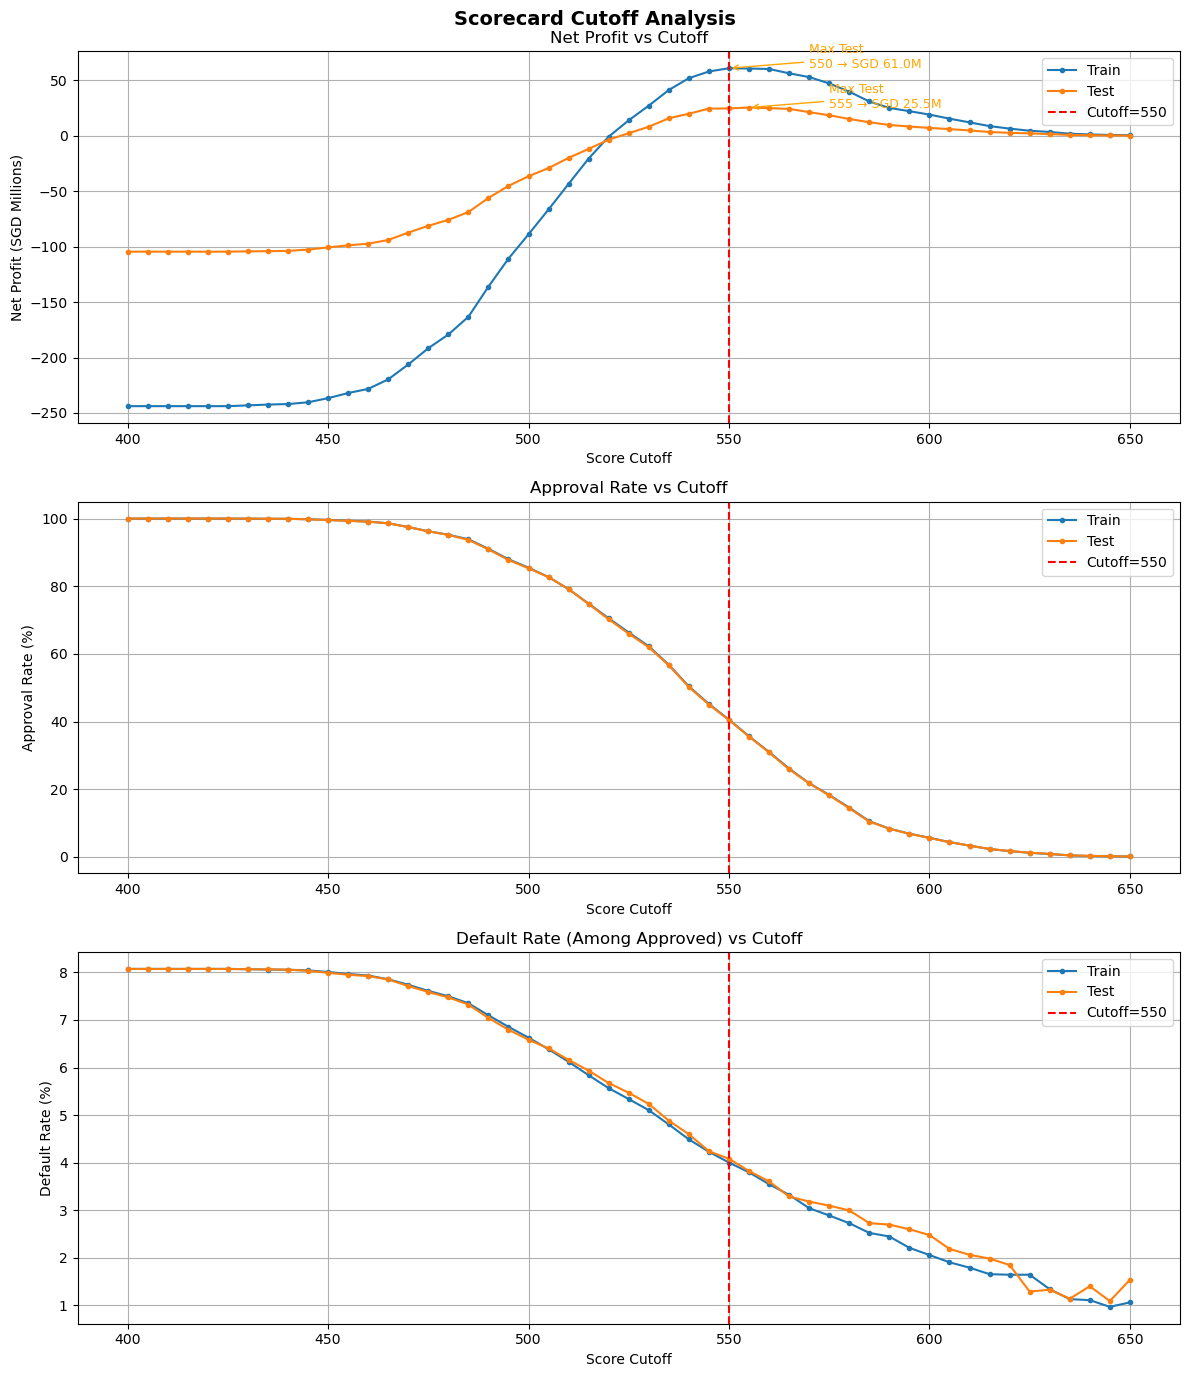

In [67]:
fig, axes = plt.subplots(3, 1, figsize=(12, 14))
fig.suptitle('Scorecard Cutoff Analysis', fontsize=14, fontweight='bold')

# --- Plot 1: Net Profit ---
ax1 = axes[0]
ax1.plot(train_res['cutoff'], train_res['net_profit'] / 1e6, label='Train', marker='o', markersize=3)
ax1.plot(test_res['cutoff'],  test_res['net_profit']  / 1e6, label='Test',  marker='o', markersize=3)
ax1.axvline(x=550, color='red', linestyle='--', label='Cutoff=550')
ax1.set_title('Net Profit vs Cutoff')
ax1.set_ylabel('Net Profit (SGD Millions)')
ax1.set_xlabel('Score Cutoff')
ax1.legend()
ax1.grid(True)


# annotate max train profit
best_test_idx = train_res['net_profit'].idxmax()
best_cutoff   = train_res.loc[best_test_idx, 'cutoff']
best_profit   = train_res.loc[best_test_idx, 'net_profit'] / 1e6
ax1.annotate(f'Max Test\n{best_cutoff} → SGD {best_profit:.1f}M',
             xy=(best_cutoff, best_profit),
             xytext=(best_cutoff + 20, best_profit),
             arrowprops=dict(arrowstyle='->', color='orange'),
             fontsize=9, color='orange')

# annotate max train profit
best_test_idx = test_res['net_profit'].idxmax()
best_cutoff   = test_res.loc[best_test_idx, 'cutoff']
best_profit   = test_res.loc[best_test_idx, 'net_profit'] / 1e6
ax1.annotate(f'Max Test\n{best_cutoff} → SGD {best_profit:.1f}M',
             xy=(best_cutoff, best_profit),
             xytext=(best_cutoff + 20, best_profit),
             arrowprops=dict(arrowstyle='->', color='orange'),
             fontsize=9, color='orange')


# --- Plot 2: Approval Rate ---
ax2 = axes[1]
ax2.plot(train_res['cutoff'], train_res['approval_rate'] * 100, label='Train', marker='o', markersize=3)
ax2.plot(test_res['cutoff'],  test_res['approval_rate']  * 100, label='Test',  marker='o', markersize=3)
ax2.axvline(x=550, color='red', linestyle='--', label='Cutoff=550')
ax2.set_title('Approval Rate vs Cutoff')
ax2.set_ylabel('Approval Rate (%)')
ax2.set_xlabel('Score Cutoff')
ax2.legend()
ax2.grid(True)

# --- Plot 3: Default Rate among Approved ---
ax3 = axes[2]
ax3.plot(train_res['cutoff'], train_res['default_rate'] * 100, label='Train', marker='o', markersize=3)
ax3.plot(test_res['cutoff'],  test_res['default_rate']  * 100, label='Test',  marker='o', markersize=3)
ax3.axvline(x=550, color='red', linestyle='--', label='Cutoff=550')
ax3.set_title('Default Rate (Among Approved) vs Cutoff')
ax3.set_ylabel('Default Rate (%)')
ax3.set_xlabel('Score Cutoff')
ax3.legend()
ax3.grid(True)

plt.tight_layout()
plt.show()

In [68]:
print('=== Summary at Cutoff = 550 ===')
summary = results_df[results_df['cutoff'] == 550][
    ['label', 'n_approved', 'approval_rate', 'n_defaults', 'default_rate', 'net_profit']
].copy()
summary['approval_rate'] = summary['approval_rate'].map('{:.1%}'.format)
summary['default_rate']  = summary['default_rate'].map('{:.2%}'.format)
summary['net_profit']    = summary['net_profit'].map('SGD {:,.0f}'.format)
print(summary.to_string(index=False))

best_train_idx = train_res['net_profit'].idxmax()
best_cutoff = train_res.loc[best_train_idx, 'cutoff']

print('\n=== Best Cutoff by Net Profit (TRAIN) ===')
print(f"Cutoff : {best_cutoff}")
print(f"Profit : SGD {train_res.loc[best_train_idx, 'net_profit']:,.0f}")
print(f"Approval Rate : {train_res.loc[best_train_idx, 'approval_rate']:.1%}")
print(f"Default Rate  : {train_res.loc[best_train_idx, 'default_rate']:.2%}")


=== Summary at Cutoff = 550 ===
label  n_approved approval_rate  n_defaults default_rate     net_profit
TRAIN       87330         40.6%        3496        4.00% SGD 61,005,000
 TEST       37331         40.5%        1524        4.08% SGD 24,747,500

=== Best Cutoff by Net Profit (TRAIN) ===
Cutoff : 550
Profit : SGD 61,005,000
Approval Rate : 40.6%
Default Rate  : 4.00%


In [53]:
cutoff = 550  

predicted_train_bad = (train_score['score'] < cutoff).astype(int).tolist()
predicted_test_bad  = (test_score['score']  < cutoff).astype(int).tolist()

print('=== TRAIN ===')
print(metrics.confusion_matrix(y_train, predicted_train_bad))
print(metrics.classification_report(y_train, predicted_train_bad))

print('=== TEST ===')
print(metrics.confusion_matrix(y_test, predicted_test_bad))
print(metrics.classification_report(y_test, predicted_test_bad))

=== TRAIN ===
[[ 83834 114046]
 [  3496  13882]]
              precision    recall  f1-score   support

           0       0.96      0.42      0.59    197880
           1       0.11      0.80      0.19     17378

    accuracy                           0.45    215258
   macro avg       0.53      0.61      0.39    215258
weighted avg       0.89      0.45      0.56    215258

=== TEST ===
[[35807 48999]
 [ 1524  5923]]
              precision    recall  f1-score   support

           0       0.96      0.42      0.59     84806
           1       0.11      0.80      0.19      7447

    accuracy                           0.45     92253
   macro avg       0.53      0.61      0.39     92253
weighted avg       0.89      0.45      0.55     92253

